## Setup
Imports, particle masses and helper functions used throughout the notebook.

Every fit plot also shows its **χ²** ("chi-squared"), worked out from the pulls:
- each bin's **pull** is (data − fit) / error, with error = √(number of candidates in the bin);
- **χ²** is the sum of the squared pulls over all bins that contain data;
- **ndf** (number of degrees of freedom) is the number of those bins minus the number of things the fit was free to adjust.

The **reduced χ²** is χ²/ndf. For a good fit it is close to 1: each bin is off by about one error bar, as expected from random fluctuations. Much bigger than 1 means the shape doesn't describe the data. The **p-value** is the chance of getting a χ² at least this big if the model were exactly right; a tiny p-value (e.g. below 0.01) means the model is clearly missing something.

Two cautions: bins with only a few candidates (e.g. the tails of the rare-decay fit) make χ² less reliable; and with hundreds of thousands of events, even a very small imperfection in the shape gives a large χ², although it may not matter for the result.

In [72]:
import pickle
import numpy as np
import pandas
from matplotlib import pyplot as plt
from tabulate import tabulate
import zfit
from scipy.stats import chi2 as chi2_distribution

#Particle masses in MeV/c^2 (PDG values)
M_KAON  = 493.7
M_MUON  = 105.7
M_PION  = 139.6
M_JPSI  = 3097
M_PSI2S = 3686
M_D0    = 1864.8

In [75]:
def track_energy(data, track, mass):
    #Energy of a track given the mass we choose. mass=None uses the energy stored in the data.
    if mass is None:
        return data[f'{track} 4-momentum energy component']
    p = [data[f'{track} 4-momentum {c} component'] for c in 'xyz']
    return np.sqrt(p[0]**2 + p[1]**2 + p[2]**2 + mass**2)


def two_body_mass(data, track1, track2, mass1=None, mass2=None):
    #Invariant mass of two tracks, where we choose which mass each track is given.
    #track names are 'Kaon', 'Opposite-sign muon' or 'Same-sign muon'.
    #Changing mass1/mass2 lets us test what happens if a particle was misidentified.
    p1 = [data[f'{track1} 4-momentum {c} component'] for c in 'xyz']
    p2 = [data[f'{track2} 4-momentum {c} component'] for c in 'xyz']

    energy1 = track_energy(data, track1, mass1)
    energy2 = track_energy(data, track2, mass2)

    combined_energy = energy1 + energy2
    combined_momentum_sq = (p1[0] + p2[0])**2 + (p1[1] + p2[1])**2 + (p1[2] + p2[2])**2
    return np.sqrt(combined_energy**2 - combined_momentum_sq)


def plot_mass(values, xlabel, title=None, show_peak=False, bins=100, **hist_kwargs):
    #Histogram of a mass, with the y-axis label showing the real bin width.
    #show_peak=True marks the centre of the tallest bin.
    counts, edges, _ = plt.hist(values, bins=bins, **hist_kwargs)
    bin_width = edges[1] - edges[0]

    if show_peak:
        i = np.argmax(counts)
        peak = 0.5 * (edges[i] + edges[i + 1])
        plt.axvline(peak, linestyle='--', color='red', label=f'Peak: {peak:.0f} MeV')
        plt.legend()

    if title:
        plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(rf'Candidates / ({bin_width:.0f} MeV/$c^2$)')
    plt.show()


def plot_fit(values, model, components=None, bins=100, xlabel=r'Mass / MeV/$c^2$', title=None, show_pulls=False):
    #Draw data as a filled histogram (with sqrt(N) error bars) with an already-fitted zfit model (and optionally its parts) on top.
    #fit_and_plot uses this, and it can be used on its own when a fit was done another way
    #(e.g. the B+ and B- fit below, which fits two datasets at once).
    #Also works out the chi-squared of the fit from the pulls, prints it (with the reduced chi-squared = chi2/ndf),
    #shows it in the legend and returns (chi2, ndf).
    lower = float(np.ravel(model.space.lower)[0])
    upper = float(np.ravel(model.space.upper)[0])
    values = np.asarray(values)
    in_range = values[(values >= lower) & (values <= upper)]

    #Turn a PDF (which integrates to 1) into candidates per bin
    counts, edges = np.histogram(in_range, bins=bins, range=(lower, upper))
    bin_width = edges[1] - edges[0]
    centres = 0.5 * (edges[1:] + edges[:-1])

    def candidates_per_bin(pdf, x):
        if pdf.is_extended:
            return np.asarray(pdf.ext_pdf(x)) * bin_width
        if pdf is model:
            return np.asarray(pdf.pdf(x)) * len(in_range) * bin_width
        raise ValueError('Components must have their own yield (extended=...) so they can be drawn.')

    #What the fit predicts for each bin: the average of the model over 10 points inside the bin
    #(more accurate than only using the bin centre, where the peak is steep)
    sub_points = edges[:-1, None] + (np.arange(10)[None, :] + 0.5) / 10 * bin_width
    expected = candidates_per_bin(model, sub_points.ravel()).reshape(len(counts), 10).mean(axis=1)

    #Pull = (data - fit) / error in each bin, with error = sqrt(number of candidates in the bin)
    errors = np.sqrt(counts)
    pulls = np.divide(counts - expected, errors, out=np.zeros(len(counts)), where=errors > 0)

    #Chi-squared = sum of the squared pulls, over the bins that contain data.
    #Degrees of freedom (ndf) = number of those bins - number of parameters the fit was free to change.
    #For a good fit chi2/ndf is close to 1, and the p-value (the chance of a chi2 at least this big if the
    #model were exactly right) is not tiny. Bins with only a few candidates make chi2 less reliable.
    used = counts > 0
    chi2_value = float(np.sum(pulls[used]**2))
    ndf = int(used.sum()) - len(model.get_params(floating=True))
    p_value = chi2_distribution.sf(chi2_value, ndf) if ndf > 0 else float('nan')
    reduced_chi2 = chi2_value / ndf if ndf > 0 else float('nan')   #reduced chi2 = chi2 / ndf, close to 1 for a good fit
    print(f'chi2 = {chi2_value:.1f}, ndf = {ndf}, reduced chi2 = {reduced_chi2:.2f}, p-value = {p_value:.3g}')

    if show_pulls:
        fig, (ax, ax_pull) = plt.subplots(2, 1, sharex=True, figsize=(6.4, 6), gridspec_kw={'height_ratios': [3, 1]})
    else:
        fig, ax = plt.subplots()

    #Data as a filled histogram, fits as lines on top
    ax.hist(in_range, bins=bins, range=(lower, upper), color='blue', label='Data')
    #Statistical uncertainty on the number of candidates in each bin: sqrt(N)
    ax.errorbar(centres, counts, yerr=np.sqrt(counts), fmt='none', ecolor='orange', elinewidth=1,
                capsize=2.5, capthick=1, zorder=3, label=r'Data error ($\sqrt{N}$)')

    x = np.linspace(lower, upper, 1000)
    ax.plot(x, candidates_per_bin(model, x), 'r-', label='Total fit')
    for (label, pdf), style in zip((components or {}).items(), ['y--', 'g:', 'm-.', 'c--']):
        ax.plot(x, candidates_per_bin(pdf, x), style, label=label)

    ax.set_ylabel(rf'Candidates / ({bin_width:.0f} MeV/$c^2$)')
    ax.legend(title=rf'$\chi^2$/ndf = {chi2_value:.1f}/{ndf}' + '\n' + rf'reduced $\chi^2$ = {reduced_chi2:.2f}, p = {p_value:.2g}',
              title_fontsize=9)
    if title:
        ax.set_title(title)

    if show_pulls:
        ax_pull.bar(centres, pulls, width=bin_width, color='grey')
        ax_pull.axhline(0, color='black', linewidth=0.8)
        for level in (-3, 3):
            ax_pull.axhline(level, color='red', linestyle='--', linewidth=0.8)
        ax_pull.set_ylabel('Pull')
        ax_pull.set_xlabel(xlabel)
    else:
        ax.set_xlabel(xlabel)

    plt.show()
    return chi2_value, ndf


def fit_and_plot(values, model, components=None, bins=100, xlabel=r'Mass / MeV/$c^2$', title=None, show_pulls=False):
    #Fit a zfit model to some data, print the result and plot the fit on top of the data.
    #values:     the data to fit, e.g. b_mass. Only the values inside the model's range are used.
    #model:      any zfit PDF you have built. If it has a yield (extended=...) an extended fit is done.
    #components: optional {label: pdf} of parts of the model to draw as well,
    #            e.g. {'Signal': signalPDF, 'Background': backgroundPDF}. Each part needs its own yield.
    #show_pulls: set to True to also draw (data - fit) / error for each bin underneath. Good fits scatter randomly around 0.
    #The chi-squared of the fit (from the pulls) is printed and shown in the legend.
    #Returns the zfit fit result, so you can read off the fitted values with result.params[parameter]['value'].
    lower = float(np.ravel(model.space.lower)[0])
    upper = float(np.ravel(model.space.upper)[0])

    values = np.asarray(values)
    in_range = values[(values >= lower) & (values <= upper)]
    zdata = zfit.Data.from_numpy(obs=model.space, array=in_range)

    if model.is_extended:
        nll = zfit.loss.ExtendedUnbinnedNLL(model=model, data=zdata)
    else:
        nll = zfit.loss.UnbinnedNLL(model=model, data=zdata)

    result = zfit.minimize.Minuit().minimize(nll)
    #Uncertainties from Hesse (the curvature of the likelihood at the minimum)
    result.hesse()

    print(result)
    print(f"Converged: {result.converged}")
    print(f"Valid: {result.valid}")
    if not result.valid:
        print('WARNING: the fit is not valid, do not trust these numbers.')

    plot_fit(in_range, model, components, bins, xlabel, title, show_pulls)
    return result


## The datasets

All the files are in `../Data/`. They come in three kinds.

### 1. Real LHCb data
| File | Candidates | What it is |
|---|---|---|
| `dataset_2011` | 0.89 million | Collisions recorded in 2011 (7 TeV). Both magnet settings mixed together |
| `dataset_2012_MagnetDown` | 1.02 million | Collisions recorded in 2012 (8 TeV), magnet pointing down |
| `dataset_2012_MagnetUp` | 1.07 million | Collisions recorded in 2012 (8 TeV), magnet pointing up |

**What's in it:** each row is one *candidate*: a kaon and two muons of opposite charge that *might* have come from a B⁺ or B⁻.
Some are real B decays (mostly B → J/ψ K, some B → ψ(2S) K, and a few of the rare B → K μ⁺μ⁻ we want). The rest are background.

**What we use it for:**
- **The measurement itself.** Using all three files gives about 3× more events than 2011 alone, so a smaller error on A_CP.
- **Cross-checks.** The answer should not depend on the year or on the magnet setting. Flipping the magnet swaps which way K⁺ and K⁻ bend in the detector, so effects from one side of the detector being better than the other flip too. If magnet up and magnet down give the same A_CP, those effects are under control.

### 2. Same-sign data (background only)
| File | Candidates |
|---|---|
| `samesign_2011` | 41 thousand |
| `samesign_2012` | 123 thousand |

**What it is:** real data again, but chosen so that the **two muons have the same charge** (for example K⁺ μ⁻ μ⁻).
No real B decay gives this, because a muon pair from a B → K μμ decay (or from a J/ψ) always has one μ⁺ and one μ⁻.
So **every candidate here is fake**: random tracks that happened to be combined. We checked: there is no peak at the B mass and no J/ψ peak.

(Careful: the column names still say "Same-sign muon" and "Opposite-sign muon", but in these files both muons have the same charge.)

**What we use it for:**
- **A clean background sample for training XGBoost.** It is better than "B mass > 5700 MeV" because it covers the *whole* mass range, including right under the B peak.
- **The shape of the random-combination background** under the B peak, for choosing the background model in the fit.

It only describes *random-combination* background. It does **not** contain peaking backgrounds from misidentified particles (like the J/ψ kaon↔muon swap).

### 3. Simulation
| File | Events | What it is |
|---|---|---|
| `rapidsim_JpsiK` | 1 million | Simulated B⁺ → J/ψ K⁺, with J/ψ → μ⁺μ⁻ |
| `rapidsim_Kmumu` | 1 million | Simulated rare B⁺ → K⁺ μ⁺μ⁻ |

**What it is:** fake events made by a computer program (RapidSim), so we know exactly what each event really is.
It also has extra `(true)` columns: the real momentum of each particle *before* the detector smeared it.

**Limits:**
- Only B⁺ (no B⁻), so it **cannot** be used to measure an asymmetry.
- It is a fast, simplified simulation: 91 columns instead of 140. There are **no χ² variables, no PID scores and no isolation variables.** Three of our XGBoost variables are missing (`B decay vertex fit chi2`, `B impact parameter chi2 wrt primary vertex`, `B flight distance chi2 wrt primary vertex`), so we can't train our current XGBoost on it.
- The detector is simplified, so the peak may not be exactly the same width as in real data. Compare it with real J/ψ K events before relying on it.

**What we use it for:**
- **The shape of the signal peak** in the B mass fit, including its tail on the low-mass side.
- **Detector resolution:** compare the measured mass with the true mass.
- **How much signal our cuts throw away** (efficiency). For example, what fraction of rare decays are removed by the J/ψ and ψ(2S) vetoes.
- **Comparing the two decays.** E.g. check that the kaon momentum looks similar in J/ψ K and in K μμ, which is what makes the J/ψ K correction to A_CP work.

In [3]:
def load_dataset(name):
    with open(f'../Data/{name}.pkl', 'rb') as infile:
        return pickle.load(infile)

#Real data. Add a 'Year' column so we can still tell the files apart after combining them
#(the magnet setting is already stored in 'Magnet polarity': +1 = up, -1 = down)
real_files = {
    'dataset_2011':            2011,
    'dataset_2012_MagnetDown': 2012,
    'dataset_2012_MagnetUp':   2012,
}
real_parts = []
for name, year in real_files.items():
    part = load_dataset(name)
    part['Year'] = year
    real_parts.append(part)
data_all = pandas.concat(real_parts, ignore_index=True)
del real_parts   #free the memory used by the separate copies

#Same-sign data (background only)
samesign_parts = []
for name, year in {'samesign_2011': 2011, 'samesign_2012': 2012}.items():
    part = load_dataset(name)
    part['Year'] = year
    samesign_parts.append(part)
samesign_all = pandas.concat(samesign_parts, ignore_index=True)
del samesign_parts

#Simulation
sim_jpsik = load_dataset('rapidsim_JpsiK')
sim_kmumu = load_dataset('rapidsim_Kmumu')

In [4]:
#How many candidates are in each dataset
summary = [
    ('Real data, 2011',               (data_all['Year'] == 2011).sum()),
    ('Real data, 2012 magnet down',   ((data_all['Year'] == 2012) & (data_all['Magnet polarity'] == -1)).sum()),
    ('Real data, 2012 magnet up',     ((data_all['Year'] == 2012) & (data_all['Magnet polarity'] == 1)).sum()),
    ('Real data, total',              len(data_all)),
    ('Same-sign, 2011',               (samesign_all['Year'] == 2011).sum()),
    ('Same-sign, 2012',               (samesign_all['Year'] == 2012).sum()),
    ('Simulation, B -> J/psi K',      len(sim_jpsik)),
    ('Simulation, B -> K mu mu',      len(sim_kmumu)),
]
print(tabulate(summary, headers=['Dataset', 'Candidates']))

Dataset                        Candidates
---------------------------  ------------
Real data, 2011                    894996
Real data, 2012 magnet down       1023524
Real data, 2012 magnet up         1066069
Real data, total                  2984589
Same-sign, 2011                     41124
Same-sign, 2012                    122980
Simulation, B -> J/psi K          1000000
Simulation, B -> K mu mu          1000000


### Which data the analysis uses
The analysis below uses **all the real data** (2011 + 2012, both magnet settings): about 3.0 million candidates.
The same-sign background sample automatically uses the same years (Task 3).

To go back to 2011 only (faster, e.g. while testing changes), use the commented-out line in the cell below instead.
Running on all the data takes a while: the variable pruning in step 7 alone takes about 20–30 minutes, and the notebook needs about 10 GB of memory.

In [5]:
#All years. data_all already has a clean 0, 1, 2, ... index, so no copy is needed (a copy would use another ~3 GB of memory)
data = data_all
#data = data_all[data_all['Year'] == 2011].reset_index(drop=True)   #2011 only

#Shortcuts for the columns we use the most
b_mass      = data['B invariant mass']
dimuon_mass = data['dimuon-system invariant mass']

In [6]:
#We can look at all the types of information stored in this data
list(data)

['B decay vertex x position',
 'B decay vertex y position',
 'B decay vertex z position',
 'B decay vertex fit chi2',
 'B impact parameter wrt primary vertex',
 'B impact parameter chi2 wrt primary vertex',
 'B flight distance wrt primary vertex',
 'B flight distance chi2 wrt primary vertex',
 'B cos(angle) between line-of-flight and momentum',
 'B magnitude of momentum',
 'B magnitude of momentum transverse to beam',
 'B 4-momentum energy component',
 'B 4-momentum x component',
 'B 4-momentum y component',
 'B 4-momentum z component',
 'B invariant mass',
 'B assumed particle type',
 'B lifetime',
 'Isolation: Charged cone angle',
 'Isolation: Charged cone number of particles contained',
 'Isolation: Charged cone eta difference between cone momentum and B',
 'Isolation: Charged cone phi difference between cone momentum and B',
 'Isolation: Charged cone ratio of B momentum and B+cone momentum all in transverse plane',
 'Isolation: Charged cone 4-momentum of max-PT object energy compon

## Task 1: B mass distribution and fit

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_382, Composed_autoparam_383]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(1936635, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 1.7e-06 │      11217454.47 | -594487.9 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name               value  (rounded)        hesse    at limit
---------------  ------------------  -----------  ----------
signalYield             1.10782e+06  +/- 1.1e+03       False
backgroundYield              828814  +/- 9.9e+02       False
mean                        5283.57  +/-    0.02    

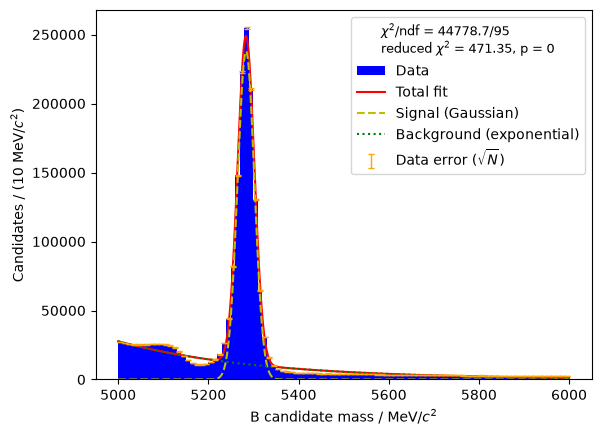

In [76]:
#Gaussian for the B peak plus an exponential for the background
b_mass_space = zfit.Space('B invariant mass', (5000, 6000))

mean  = zfit.Parameter('mean', 5280, 5000, 6000)
sigma = zfit.Parameter('sigma', 20,    5,  100)
signalYield = zfit.Parameter('signalYield', 1e6, 0, 1e7)

signalPDF = zfit.pdf.Gauss(obs=b_mass_space, mu=mean, sigma=sigma, extended=signalYield)

exponent  = zfit.Parameter('exponent', -0.01, -1e-1, -1e-6)
backgroundYield = zfit.Parameter('backgroundYield', 8e5, 0, 1e7)

backgroundPDF = zfit.pdf.Exponential(obs=b_mass_space, lam=exponent, extended=backgroundYield)

totalPDF = zfit.pdf.SumPDF(pdfs=[signalPDF, backgroundPDF])

result = fit_and_plot(b_mass, totalPDF,
                      components={'Signal (Gaussian)': signalPDF, 'Background (exponential)': backgroundPDF},
                      xlabel=r'B candidate mass / MeV/$c^2$')

mu_fit         = result.params[mean]['value']
sigma_fit      = result.params[sigma]['value']
sig_yield_fit  = result.params[signalYield]['value']
back_yield_fit = result.params[backgroundYield]['value']
exponent_fit   = result.params[exponent]['value']

**Mass and width of the B⁺ compared with the literature** (all data)

| | Fitted | PDG | Difference |
|---|---|---|---|
| B⁺ mass, Gaussian fit | 5283.57 ± 0.02 MeV | 5279.34 MeV | +4.2 MeV (+0.080%) |
| B⁺ mass, double Crystal Ball fit (below) | 5283.90 ± 0.03 MeV | 5279.34 MeV | +4.6 MeV (+0.086%) |
| J/ψ mass (Task 2) | 3099.93 ± 0.01 MeV | 3096.90 MeV | +3.0 MeV (+0.098%) |
| ψ(2S) mass (Task 2) | 3689.80 ± 0.05 MeV | 3686.10 MeV | +3.7 MeV (+0.100%) |

**The mass is about 4.5 MeV too high**, which is hundreds of times its statistical uncertainty. It is **not** caused by the fit shape: the Gaussian and the much better double Crystal Ball (reduced χ² 471 vs 4.8) give the same mean to within 0.3 MeV. Instead, **all three peaks are too high by about the same fraction (≈ 0.09%)**. A shift that is the same *fraction* for every particle points to the **momentum scale**: the detector's momentum measurement is slightly too high (by about 0.1%), so every reconstructed mass comes out slightly too high. (LHCb corrects for this with a dedicated momentum-scale calibration, which has not been applied to this dataset.)

**The width.** The fitted width of the peak is σ ≈ 18 MeV. The true (natural) width of the B⁺ is tiny: Γ = ħ/τ = 6.58 × 10⁻²² MeV s / 1.638 × 10⁻¹² s ≈ **4 × 10⁻¹⁰ MeV**, because the B⁺ lives a relatively long time. So the 18 MeV we see is entirely the **detector resolution**: momenta are only measured to about 0.5%, which smears the reconstructed mass. The low-mass tail of the peak comes mainly from photons radiated by the final-state particles, and the high-mass tail from the resolution not being exactly Gaussian.

### Crystal Ball fits 
Includes both single and double sided

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_385, Composed_autoparam_386]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(1429614, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 0.00032 │         7163918.41 | -945881 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                    value  (rounded)        hesse    at limit
--------------------  ------------------  -----------  ----------
b_cb_signalYield             1.20408e+06  +/- 1.6e+03       False
b_cb_backgroundYield              225526  +/- 1.2e+03       False
b_cb_mean                       

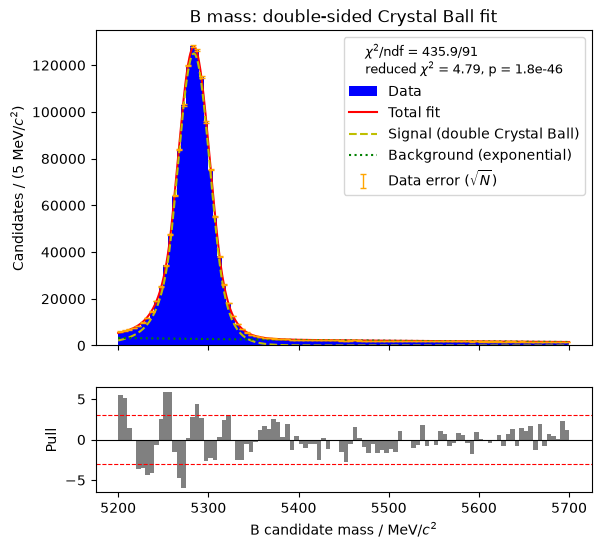

In [77]:
#Double-sided Crystal Ball for the B peak plus an exponential for the background
b_cb_space = zfit.Space('B invariant mass', (5200, 5700))

b_cb_mean   = zfit.Parameter('b_cb_mean',   5280, 5200, 5400)
b_cb_sigma  = zfit.Parameter('b_cb_sigma',  18,   1,    100)
b_cb_alphaL = zfit.Parameter('b_cb_alphaL', 1.5,  0.1,  10)
b_cb_nL     = zfit.Parameter('b_cb_nL',     3,    0.5,  100)
b_cb_alphaR = zfit.Parameter('b_cb_alphaR', 1.5,  0.1,  10)
b_cb_nR     = zfit.Parameter('b_cb_nR',     3,    0.5,  100)
b_cb_signalYield = zfit.Parameter('b_cb_signalYield', 3e5, 0, 1e7)

b_cb_signalPDF = zfit.pdf.DoubleCB(obs=b_cb_space, mu=b_cb_mean, sigma=b_cb_sigma,
                                   alphal=b_cb_alphaL, nl=b_cb_nL, alphar=b_cb_alphaR, nr=b_cb_nR,
                                   extended=b_cb_signalYield)

b_cb_exponent        = zfit.Parameter('b_cb_exponent', -0.003, -0.1, 0.1)
b_cb_backgroundYield = zfit.Parameter('b_cb_backgroundYield', 5e4, 0, 1e7)

b_cb_backgroundPDF = zfit.pdf.Exponential(obs=b_cb_space, lam=b_cb_exponent, extended=b_cb_backgroundYield)

b_cb_totalPDF = zfit.pdf.SumPDF(pdfs=[b_cb_signalPDF, b_cb_backgroundPDF])

result_b_cb = fit_and_plot(b_mass, b_cb_totalPDF,
                           components={'Signal (double Crystal Ball)': b_cb_signalPDF, 'Background (exponential)': b_cb_backgroundPDF},
                           xlabel=r'B candidate mass / MeV/$c^2$', title='B mass: double-sided Crystal Ball fit', show_pulls=True)

b_cb_mu_fit        = result_b_cb.params[b_cb_mean]['value']
b_cb_sigma_fit     = result_b_cb.params[b_cb_sigma]['value']
b_cb_sig_yield_fit = result_b_cb.params[b_cb_signalYield]['value']

**Like-for-like comparison.** The first Gaussian fit (above) covered 5000–6000 MeV, which includes the low-mass bump that neither model describes. To compare the two signal shapes fairly, here is the Gaussian (plus the same exponential background) fitted over exactly the same range as the double-sided Crystal Ball, 5200–5700 MeV.

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_388, Composed_autoparam_389]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(1429614, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 0.00062 │       7169109.88 | -37566.63 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                          value  (rounded)        hesse    at limit
--------------------------  ------------------  -----------  ----------
gauss_same_signalYield             1.12572e+06  +/- 1.2e+03       False
gauss_same_backgroundYield              303880  +/- 7.9e+02       False
gauss_sa

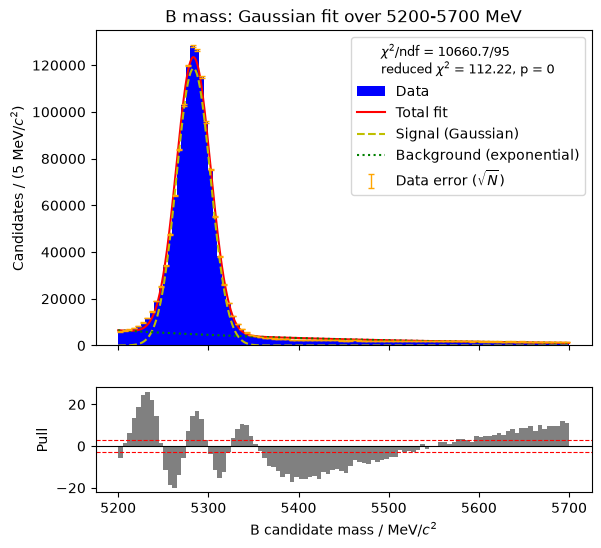

In [78]:
#Gaussian for the B peak plus an exponential, over the same range as the double-sided Crystal Ball fit
gauss_same_space = zfit.Space('B invariant mass', (5200, 5700))

gauss_same_mean  = zfit.Parameter('gauss_same_mean',  5280, 5200, 5400)
gauss_same_sigma = zfit.Parameter('gauss_same_sigma', 18,   1,    100)
gauss_same_signalYield = zfit.Parameter('gauss_same_signalYield', 1e6, 0, 1e7)
gauss_same_signalPDF = zfit.pdf.Gauss(obs=gauss_same_space, mu=gauss_same_mean, sigma=gauss_same_sigma,
                                      extended=gauss_same_signalYield)

gauss_same_exponent        = zfit.Parameter('gauss_same_exponent', -0.003, -0.1, 0.1)
gauss_same_backgroundYield = zfit.Parameter('gauss_same_backgroundYield', 2e5, 0, 1e7)
gauss_same_backgroundPDF = zfit.pdf.Exponential(obs=gauss_same_space, lam=gauss_same_exponent,
                                                extended=gauss_same_backgroundYield)

gauss_same_totalPDF = zfit.pdf.SumPDF(pdfs=[gauss_same_signalPDF, gauss_same_backgroundPDF])

result_gauss_same = fit_and_plot(b_mass, gauss_same_totalPDF,
                                 components={'Signal (Gaussian)': gauss_same_signalPDF, 'Background (exponential)': gauss_same_backgroundPDF},
                                 xlabel=r'B candidate mass / MeV/$c^2$', title='B mass: Gaussian fit over 5200-5700 MeV', show_pulls=True)

**Something else under the high-mass tail: B⁺ → J/ψ π⁺.** If a pion is mistaken for a kaon, it is given the kaon mass, which is too heavy, so the B mass comes out about 50 MeV too high.
The check below takes J/ψ candidates sitting just *above* the B peak (5320–5420 MeV), gives the "kaon" the pion mass instead, and recomputes the B mass. If they are really B⁺ → J/ψ π⁺, they pile up at the B mass (5279 MeV).
The double-sided Crystal Ball's high-mass tail partly absorbs these events, so the signal yield above includes some J/ψ π decays. To count B → J/ψ K properly, this needs its own component in the fit (or a particle-ID cut on the kaon).

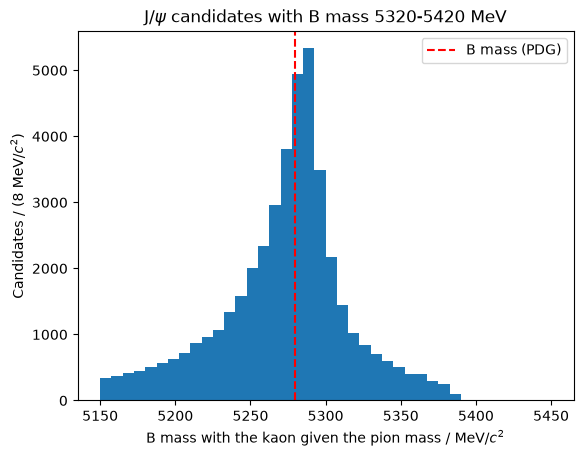

In [79]:
#Recompute the B mass with the kaon given the pion mass, for J/psi candidates just above the B peak
above_peak = (abs(dimuon_mass - M_JPSI) < 45) & (b_mass > 5320) & (b_mass < 5420)
check = data[above_peak]

kaon_as_pion_energy = track_energy(check, 'Kaon', M_PION)
total_energy = kaon_as_pion_energy + check['Same-sign muon 4-momentum energy component'] + check['Opposite-sign muon 4-momentum energy component']
total_momentum_sq = sum((check[f'Kaon 4-momentum {c} component'] + check[f'Same-sign muon 4-momentum {c} component']
                         + check[f'Opposite-sign muon 4-momentum {c} component'])**2 for c in 'xyz')
b_mass_kaon_as_pion = np.sqrt(total_energy**2 - total_momentum_sq)

plt.axvline(5279.3, color='red', linestyle='--', label='B mass (PDG)')
plt.legend()
plot_mass(b_mass_kaon_as_pion, r'B mass with the kaon given the pion mass / MeV/$c^2$', bins=40, range=(5150, 5450),
          title=r'J/$\psi$ candidates with B mass 5320-5420 MeV')

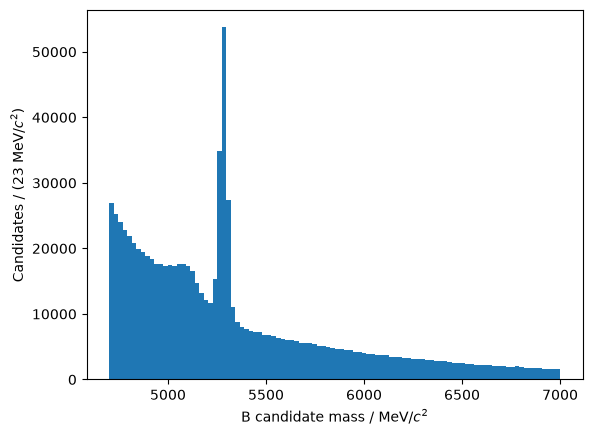

In [80]:
#Most of the real B mesons are actually B -> J/psi K decays. The J/psi is a charm-anticharm meson which decays to our two muons, and
#so, the dimuon system will have a mass consistent with the J/psi meson, 3097 MeV. If we remove these we get

not_jpsi = abs(dimuon_mass - M_JPSI) > 100

plot_mass(b_mass[not_jpsi], r'B candidate mass / MeV/$c^2$')

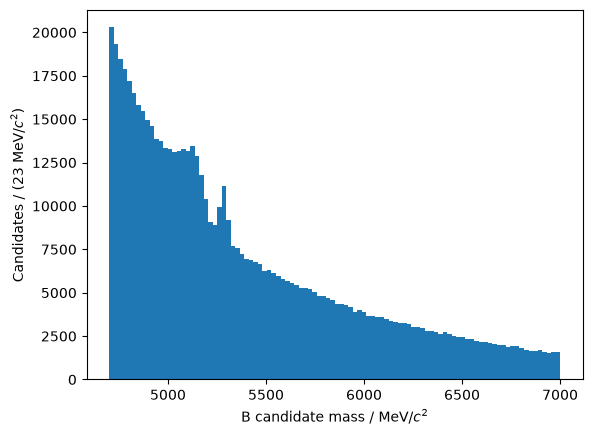

In [81]:
#Now most of what's remaining are actually B -> psi(2S) K decays. The psi(2S) is an excited state of the J/psi.
#It can also decay to our two muons, but now the dimuon system will have a mass consistent with the psi(2S) meson, 3686 MeV.
#If we also remove these, we'll see how much work we've got to do

not_psi2s = abs(dimuon_mass - M_PSI2S) > 100

plot_mass(b_mass[not_jpsi & not_psi2s], r'B candidate mass / MeV/$c^2$')

## Task 2: Dimuon mass spectrum

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.dist_tfp.Gauss'>  params=[jpsi_mean, jpsi_sigma]] data=[<zfit.Data: Data obs=('dimuon-system invariant mass',) shape=(2064472, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 1.2e-06 │        8558769.87 | -1551455 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                value  (rounded)        hesse    at limit
----------------  ------------------  -----------  ----------
jpsi_signalYield         2.06447e+06  +/- 1.4e+03       False
jpsi_mean                     3099.3  +/-   0.011       False
jpsi_sigma                   15.4055  +/-  0.0079       False

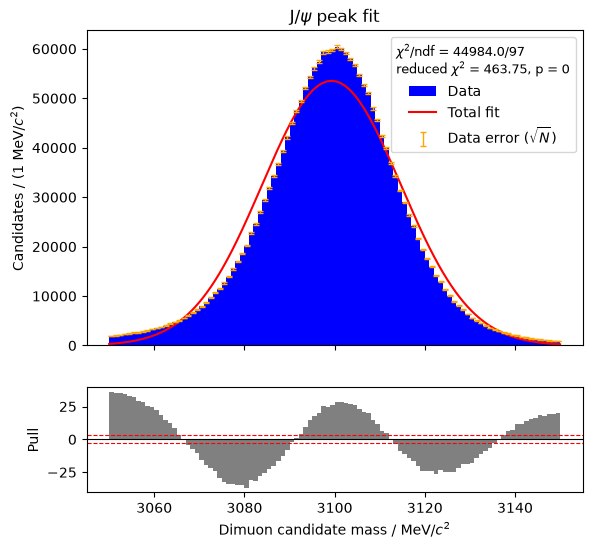

In [82]:
# Fit the J/psi peak and obtain a sigma to justify the width of exclusion
jpsi_space = zfit.Space('dimuon-system invariant mass', (3050, 3150))

jpsi_mean  = zfit.Parameter('jpsi_mean', 3102, 2700, 3200)
jpsi_sigma = zfit.Parameter('jpsi_sigma', 12,    5,  100)
jpsi_signalYield = zfit.Parameter('jpsi_signalYield', 5e5, 0, 1e7)

jpsi_PDF = zfit.pdf.Gauss(obs=jpsi_space, mu=jpsi_mean, sigma=jpsi_sigma, extended=jpsi_signalYield)

result_jpsi = fit_and_plot(dimuon_mass, jpsi_PDF, xlabel=r'Dimuon candidate mass / MeV/$c^2$', title=r'J/$\psi$ peak fit', show_pulls=True)

jpsi_mu_fit         = result_jpsi.params[jpsi_mean]['value']
jpsi_sigma_fit      = result_jpsi.params[jpsi_sigma]['value']
jpsi_sig_yield_fit  = result_jpsi.params[jpsi_signalYield]['value']

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_391, Composed_autoparam_392]] data=[<zfit.Data: Data obs=('dimuon-system invariant mass',) shape=(2167126, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 0.00056 │        9465579.09 | -1195376 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                       value  (rounded)        hesse    at limit
-----------------------  ------------------  -----------  ----------
jpsi_cb_signalYield             2.08167e+06  +/- 1.6e+03       False
jpsi_cb_backgroundYield             85449.2  +/- 7.3e+02       False
jpsi_cb_

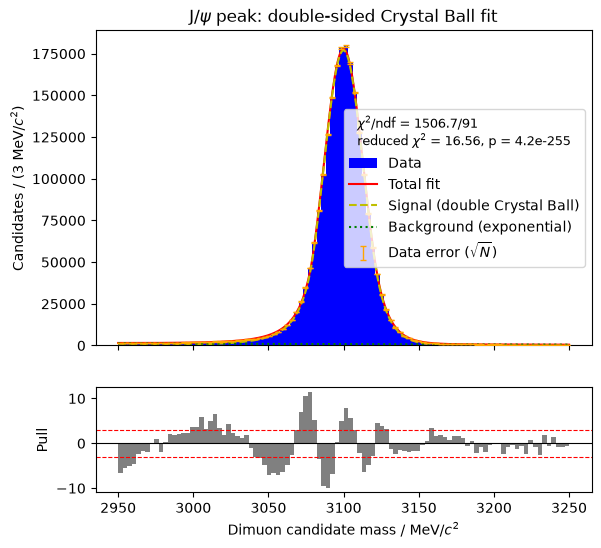

In [83]:
#Double-sided Crystal Ball for the J/psi peak plus an exponential for the background under it.
#A wider range than the Gaussian fit, so the tails and the background are included.
jpsi_cb_space = zfit.Space('dimuon-system invariant mass', (2950, 3250))

jpsi_cb_mean   = zfit.Parameter('jpsi_cb_mean',   3097, 3050, 3150)
jpsi_cb_sigma  = zfit.Parameter('jpsi_cb_sigma',  14,   1,    100)
jpsi_cb_alphaL = zfit.Parameter('jpsi_cb_alphaL', 1.5,  0.1,  10)
jpsi_cb_nL     = zfit.Parameter('jpsi_cb_nL',     3,    0.5,  100)
jpsi_cb_alphaR = zfit.Parameter('jpsi_cb_alphaR', 1.5,  0.1,  10)
jpsi_cb_nR     = zfit.Parameter('jpsi_cb_nR',     3,    0.5,  100)
jpsi_cb_signalYield = zfit.Parameter('jpsi_cb_signalYield', 6e5, 0, 1e7)

jpsi_cb_signalPDF = zfit.pdf.DoubleCB(obs=jpsi_cb_space, mu=jpsi_cb_mean, sigma=jpsi_cb_sigma,
                                      alphal=jpsi_cb_alphaL, nl=jpsi_cb_nL, alphar=jpsi_cb_alphaR, nr=jpsi_cb_nR,
                                      extended=jpsi_cb_signalYield)

jpsi_cb_exponent        = zfit.Parameter('jpsi_cb_exponent', -0.003, -0.1, 0.1)
jpsi_cb_backgroundYield = zfit.Parameter('jpsi_cb_backgroundYield', 3e4, 0, 1e7)

jpsi_cb_backgroundPDF = zfit.pdf.Exponential(obs=jpsi_cb_space, lam=jpsi_cb_exponent, extended=jpsi_cb_backgroundYield)

jpsi_cb_totalPDF = zfit.pdf.SumPDF(pdfs=[jpsi_cb_signalPDF, jpsi_cb_backgroundPDF])

result_jpsi_cb = fit_and_plot(dimuon_mass, jpsi_cb_totalPDF,
                              components={'Signal (double Crystal Ball)': jpsi_cb_signalPDF, 'Background (exponential)': jpsi_cb_backgroundPDF},
                              xlabel=r'Dimuon candidate mass / MeV/$c^2$', title=r'J/$\psi$ peak: double-sided Crystal Ball fit', show_pulls=True)

jpsi_cb_mu_fit        = result_jpsi_cb.params[jpsi_cb_mean]['value']
jpsi_cb_sigma_fit     = result_jpsi_cb.params[jpsi_cb_sigma]['value']
jpsi_cb_sig_yield_fit = result_jpsi_cb.params[jpsi_cb_signalYield]['value']

For the ψ(2S) a **single** Crystal Ball (low-mass tail only) is enough: the pulls already scatter within about ±3.
There are about 12× fewer ψ(2S) than J/ψ, so small differences in the tail shape can't be seen. We use the simplest shape that describes the data.

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_394, Composed_autoparam_395]] data=[<zfit.Data: Data obs=('dimuon-system invariant mass',) shape=(212954, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 3.7e-05 │       1025446.87 | -134523.3 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                        value  (rounded)        hesse    at limit
------------------------  ------------------  -----------  ----------
psi2s_cb_signalYield                  166602  +/- 5.3e+02       False
psi2s_cb_backgroundYield             46352.3  +/-   4e+02       False
psi2s

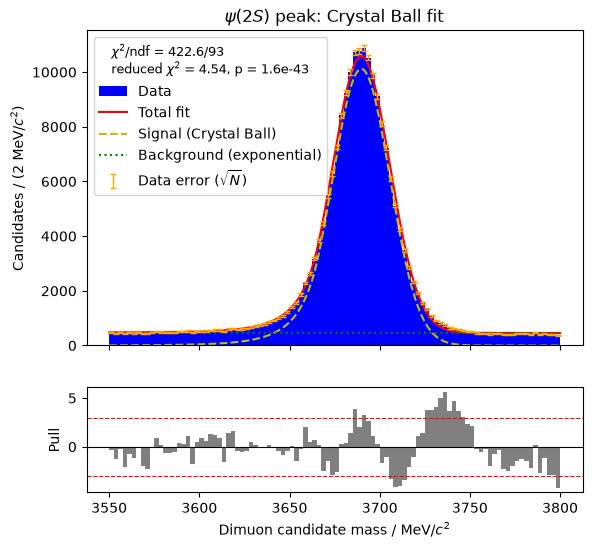

In [84]:
#Single Crystal Ball for the psi(2S) peak plus an exponential for the background under it
psi2s_cb_space = zfit.Space('dimuon-system invariant mass', (3550, 3800))

psi2s_cb_mean  = zfit.Parameter('psi2s_cb_mean',  3686, 3650, 3720)
psi2s_cb_sigma = zfit.Parameter('psi2s_cb_sigma', 17,   1,    100)
psi2s_cb_alpha = zfit.Parameter('psi2s_cb_alpha', 1.5,  0.1,  10)
psi2s_cb_n     = zfit.Parameter('psi2s_cb_n',     3,    0.5,  100)
psi2s_cb_signalYield = zfit.Parameter('psi2s_cb_signalYield', 3e4, 0, 1e7)

psi2s_cb_signalPDF = zfit.pdf.CrystalBall(obs=psi2s_cb_space, mu=psi2s_cb_mean, sigma=psi2s_cb_sigma,
                                          alpha=psi2s_cb_alpha, n=psi2s_cb_n, extended=psi2s_cb_signalYield)

psi2s_cb_exponent        = zfit.Parameter('psi2s_cb_exponent', -0.003, -0.1, 0.1)
psi2s_cb_backgroundYield = zfit.Parameter('psi2s_cb_backgroundYield', 3e4, 0, 1e7)

psi2s_cb_backgroundPDF = zfit.pdf.Exponential(obs=psi2s_cb_space, lam=psi2s_cb_exponent, extended=psi2s_cb_backgroundYield)

psi2s_cb_totalPDF = zfit.pdf.SumPDF(pdfs=[psi2s_cb_signalPDF, psi2s_cb_backgroundPDF])

result_psi2s_cb = fit_and_plot(dimuon_mass, psi2s_cb_totalPDF,
                               components={'Signal (Crystal Ball)': psi2s_cb_signalPDF, 'Background (exponential)': psi2s_cb_backgroundPDF},
                               xlabel=r'Dimuon candidate mass / MeV/$c^2$', title=r'$\psi(2S)$ peak: Crystal Ball fit', show_pulls=True)

psi2s_cb_mu_fit        = result_psi2s_cb.params[psi2s_cb_mean]['value']
psi2s_cb_sigma_fit     = result_psi2s_cb.params[psi2s_cb_sigma]['value']
psi2s_cb_sig_yield_fit = result_psi2s_cb.params[psi2s_cb_signalYield]['value']

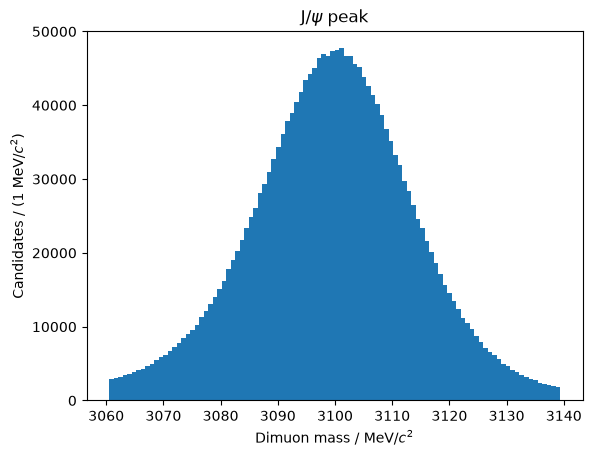

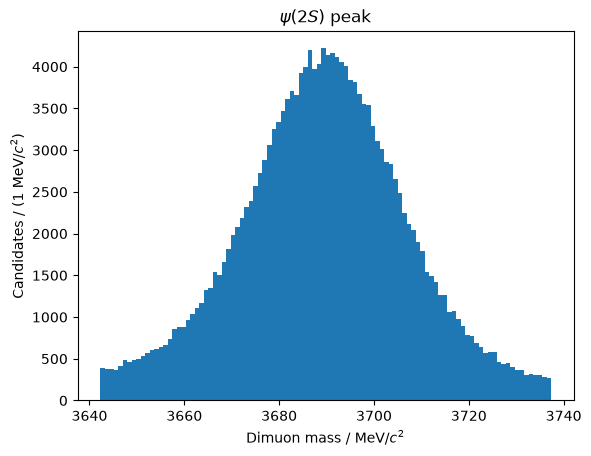

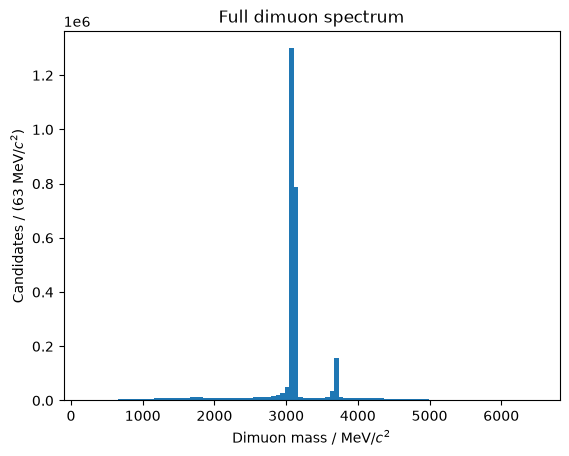

In [85]:
#J/psi and psi(2S) regions of the dimuon spectrum
#Each window is the fitted mean +- 3 sigma of the core, from the Crystal Ball fits above
#(True/False masks rather than copies of the data, to save memory)
jpsi_region  = abs(dimuon_mass - jpsi_cb_mu_fit)  < 3*jpsi_cb_sigma_fit
psi2s_region = abs(dimuon_mass - psi2s_cb_mu_fit) < 3*psi2s_cb_sigma_fit

plot_mass(dimuon_mass[jpsi_region],  r'Dimuon mass / MeV/$c^2$', title=r'J/$\psi$ peak')
plot_mass(dimuon_mass[psi2s_region], r'Dimuon mass / MeV/$c^2$', title=r'$\psi(2S)$ peak')
plot_mass(dimuon_mass, r'Dimuon mass / MeV/$c^2$', title='Full dimuon spectrum')

## Task 3: Signal-like and background-like regions
### Signal-like data
Real data where **both** masses sit in their peaks: the dimuon mass near the J/ψ **and** the B mass near the B peak.
Cutting on the dimuon mass alone is not enough, because it keeps every B mass from 4700 to 7000 MeV. That includes a real J/ψ combined with a random kaon, and B decays with a missed particle (the bump below 5150 MeV).
With both cuts, almost everything left is real B⁺ → J/ψ K⁺. This has the same final-state particles as the rare decay, and the B flies and decays the same way, so it is a good stand-in for the signal we want.

In [17]:
def add_muon_features(df):
    #Combine the two muons so it doesn't matter which one is called "same-sign" (the labels mean different things in the same-sign files)
    df['Muon min impact parameter chi2'] = np.minimum(df['Same-sign muon impact parameter chi2 wrt primary vertex'],
                                                      df['Opposite-sign muon impact parameter chi2 wrt primary vertex'])
    df['Muon min transverse momentum']   = np.minimum(df['Same-sign muon magnitude of momentum transverse to beam'],
                                                      df['Opposite-sign muon magnitude of momentum transverse to beam'])
    return df

data = add_muon_features(data)
samesign_all = add_muon_features(samesign_all)


Signal-like candidates: 1066157


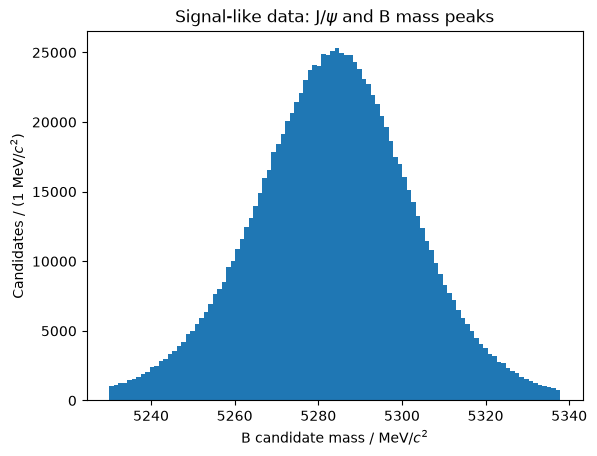

In [86]:
#Both masses within 3 sigma of their peaks (core widths from the Crystal Ball fits)
in_jpsi_peak = abs(dimuon_mass - jpsi_cb_mu_fit) < 3*jpsi_cb_sigma_fit
in_b_peak    = abs(b_mass - b_cb_mu_fit) < 3*b_cb_sigma_fit

signal_like = data[in_jpsi_peak & in_b_peak]

#Shuffle, so the train/test split later takes a random mix of events
signal_like = signal_like.sample(frac=1, random_state=42).reset_index(drop=True)

print(f'Signal-like candidates: {len(signal_like)}')
plot_mass(signal_like['B invariant mass'], r'B candidate mass / MeV/$c^2$', title=r'Signal-like data: J/$\psi$ and B mass peaks')

### Background-like data
Same-sign data: both muons have the same charge, so no real B decay can produce these candidates. Every one is a random combination of tracks.
We only use the same years as `data`. 2012 had a higher collision energy, so its events look slightly different; mixing years would let XGBoost learn "looks like 2012 = background" instead of real differences between signal and background.

Background-like candidates: 164104 (years: [np.int64(2011), np.int64(2012)])


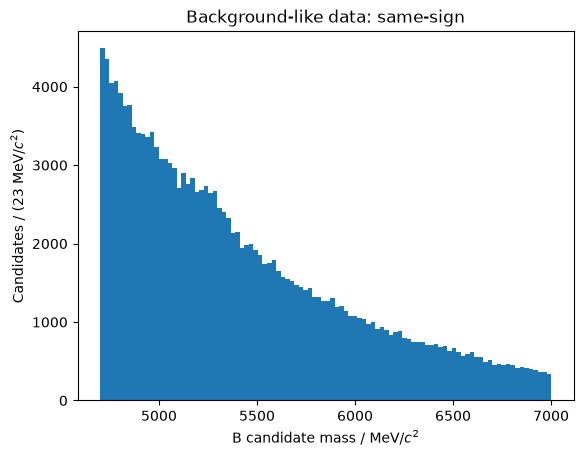

In [87]:
#Same-sign data from the same years as the signal sample
noise_like = samesign_all[samesign_all['Year'].isin(data['Year'].unique())]

#Shuffle: samesign_all is all of 2011 followed by all of 2012, so without this
#the test sample (the last 10%) could end up being all from one year
noise_like = noise_like.sample(frac=1, random_state=42).reset_index(drop=True)

print(f'Background-like candidates: {len(noise_like)} (years: {sorted(noise_like["Year"].unique())})')
plot_mass(noise_like['B invariant mass'], r'B candidate mass / MeV/$c^2$', title='Background-like data: same-sign')

### Identify how features vary between datasets

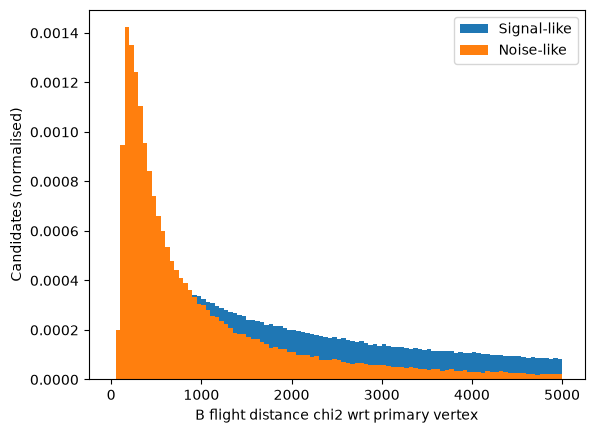

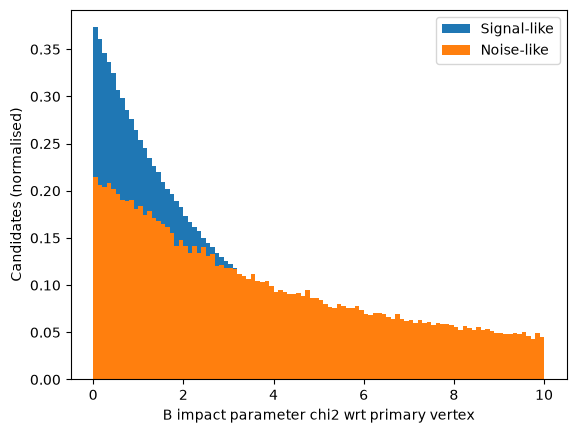

In [20]:
#(variable, plot range)
compare_variables = [
    ('B flight distance chi2 wrt primary vertex',  (0, 5000)),
    ('B impact parameter chi2 wrt primary vertex', (0, 10)),
]

for variable, plot_range in compare_variables:
    plt.hist(signal_like[variable], bins=100, range=plot_range, label='Signal-like', density=True)
    plt.hist(noise_like[variable],  bins=100, range=plot_range, label='Noise-like',  density=True)
    plt.xlabel(variable)
    plt.ylabel('Candidates (normalised)')
    plt.legend()
    plt.show()

### Choosing variables for XGBoost
 1. Initial shortlist: What could be useful

In [21]:
shortlist = [
    #B candidate
    'B decay vertex fit chi2',
    'B impact parameter wrt primary vertex',
    'B impact parameter chi2 wrt primary vertex',
    'B flight distance wrt primary vertex',
    'B flight distance chi2 wrt primary vertex',
    'B cos(angle) between line-of-flight and momentum',
    'B lifetime',
    'B magnitude of momentum transverse to beam',
    'B magnitude of momentum',
    #muon pair
    'dimuon-system decay vertex fit chi2',
    'dimuon-system impact parameter chi2 wrt primary vertex',
    'dimuon-system flight distance wrt B-decay vertex',
    'dimuon-system flight distance chi2 wrt B-decay vertex',
    'dimuon-system cos(angle) between line-of-flight from B-decay vertex and momentum',
    #tracks
    'Kaon impact parameter chi2 wrt primary vertex',
    'Kaon magnitude of momentum transverse to beam',
    'Muon min impact parameter chi2',
    'Muon min transverse momentum',
    #isolation
    'Isolation: B vertex delta chi2 adding one extra track (best fit)',
    'Isolation: B vertex delta chi2 adding two extra tracks (best fits)',
    'Isolation: B vertex number of well fitting additional tracks',
    'Isolation: ML output of best fitting extra track',
    'Isolation: Charged cone ratio of B momentum and B+cone momentum all in transverse plane',
    'Isolation: Charged cone number of particles contained',
    'Isolation: Neutral cone ratio of B momentum and B+cone momentum all in transverse plane',
    'Isolation: Neutral cone number of particles containted',
]


 2. Overlay plots for each variable

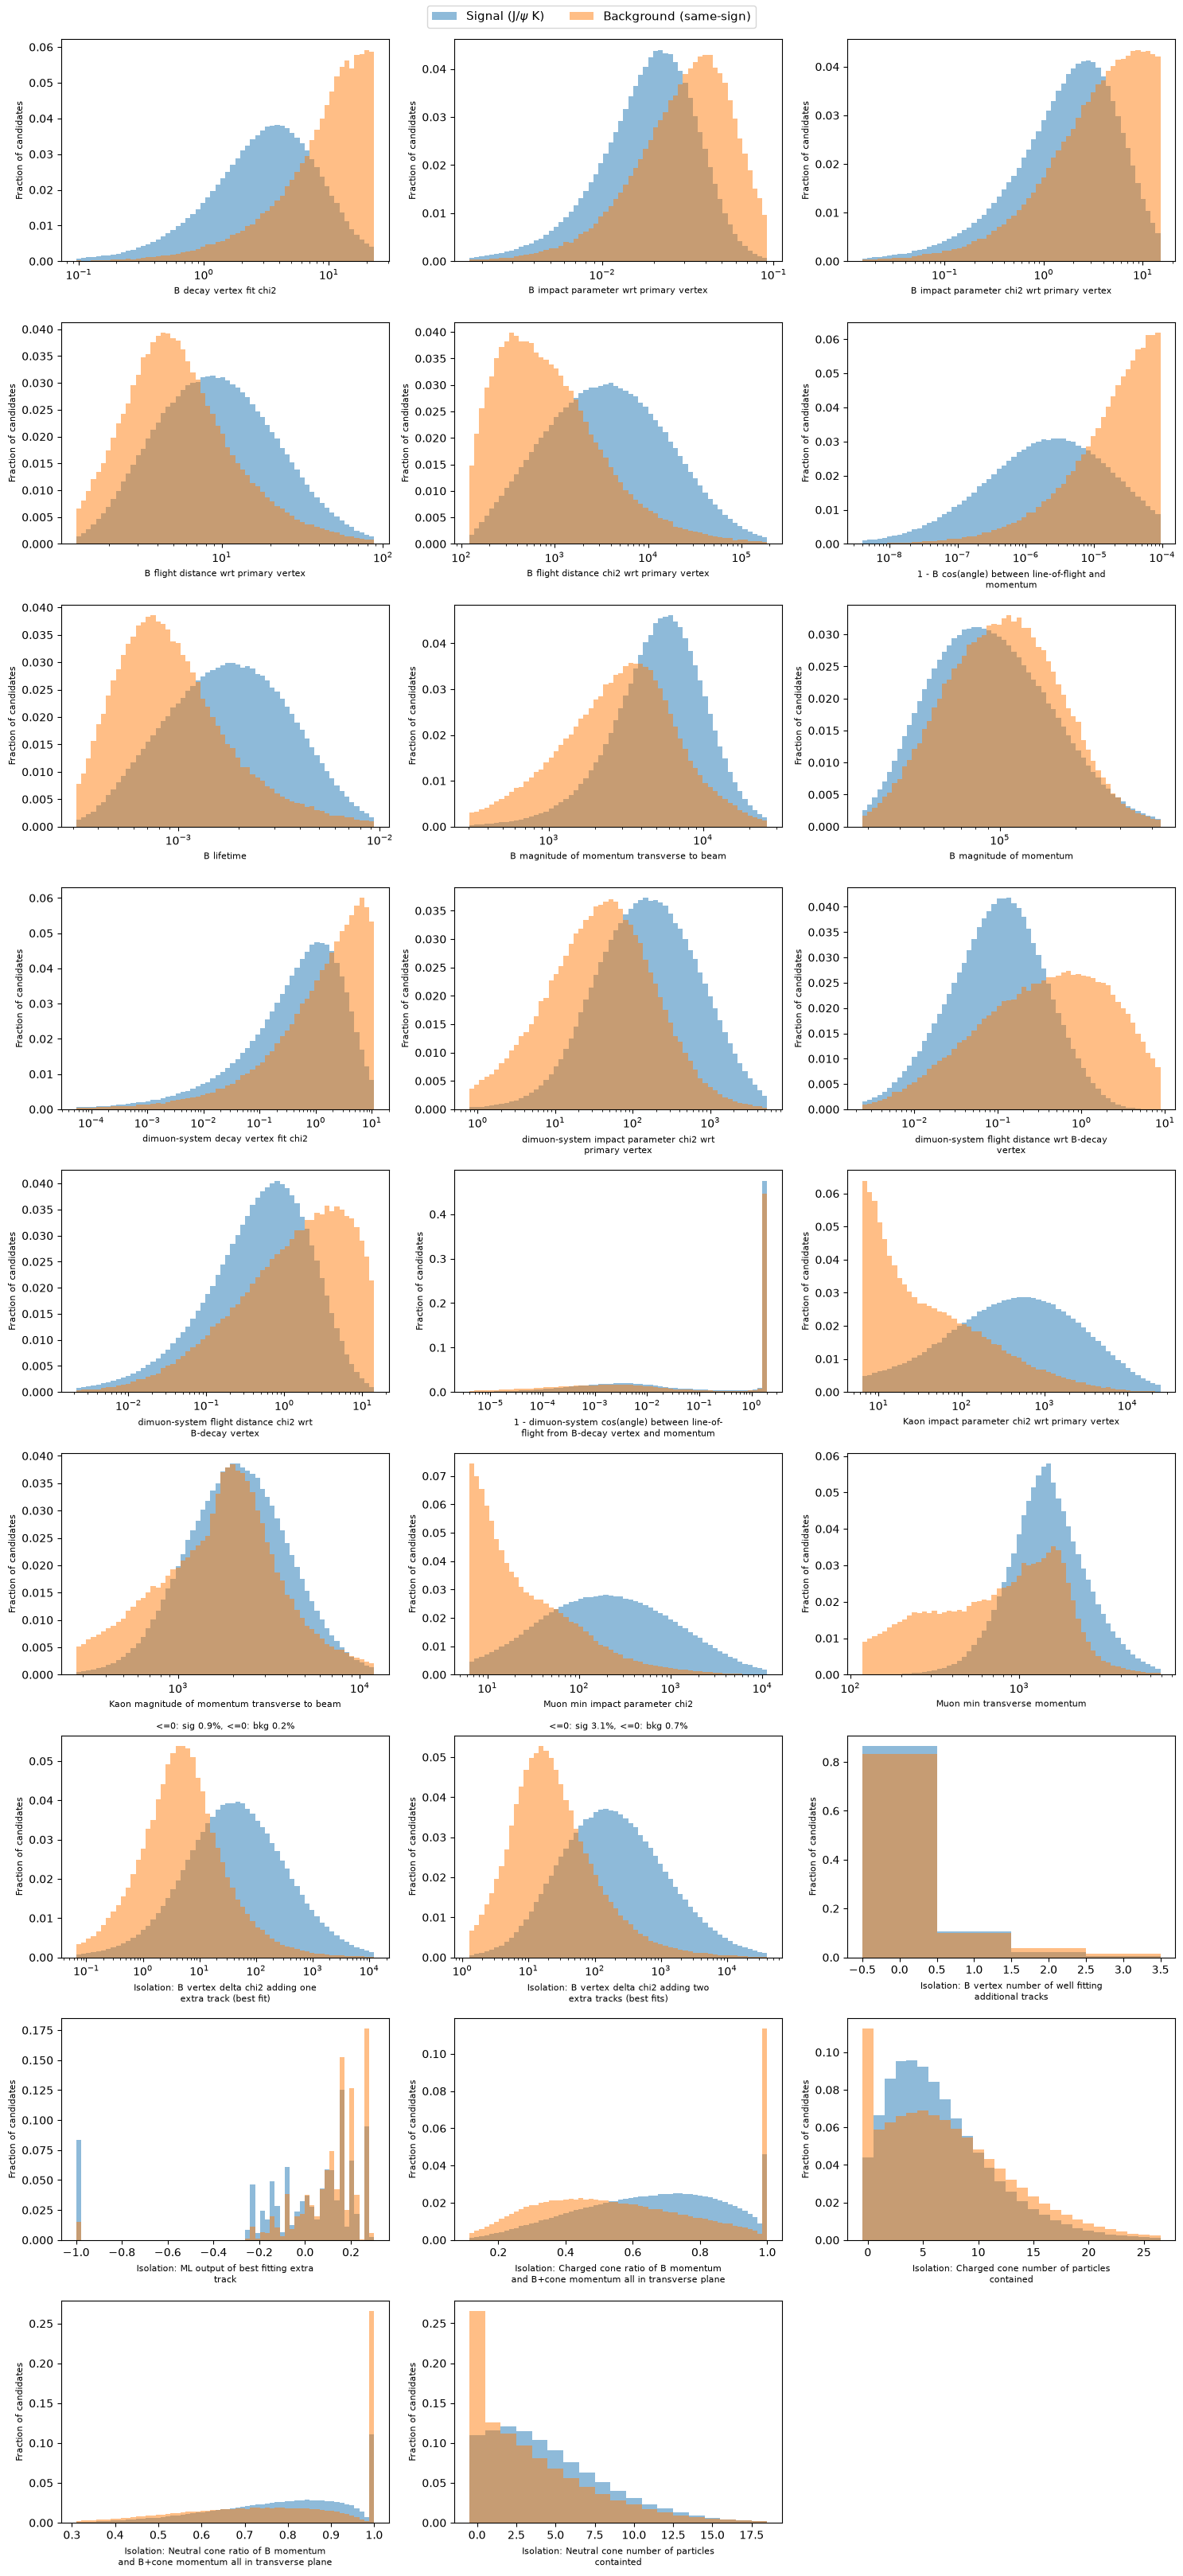

In [22]:
#Step 2: overlay signal (J/psi K) and background (same-sign) for every variable in the shortlist.
#Each histogram is normalised so its bars add up to 1: we compare the SHAPES, not the numbers of events.
#If the two shapes are different, the variable can help tell signal from background.
#
#chi2 variables (and those in log_also) have very long tails, so they get a log x-axis.
#Values <= 0 can't go on a log axis (the isolation variables use -1 to mean "nothing found"),
#so they are left out of the plot and the fraction of them is written above it instead.
#The plot range also leaves out the most extreme 0.5% on each side, so the tails don't squash the plot.

import textwrap
from matplotlib.ticker import NullFormatter

#Other long-tailed variables that are easier to read on a log axis
log_also = [
    'B impact parameter wrt primary vertex',
    'B flight distance wrt primary vertex',
    'B lifetime',
    'B magnitude of momentum transverse to beam',
    'B magnitude of momentum',
    'dimuon-system flight distance wrt B-decay vertex',
    'Kaon magnitude of momentum transverse to beam',
    'Muon min transverse momentum',
]

def overlay(ax, variable, signal, background, bins=60):
    sig = signal[variable].to_numpy(dtype=float)
    bkg = background[variable].to_numpy(dtype=float)
    notes = []

    #Missing values
    for name, values in (('sig', sig), ('bkg', bkg)):
        if np.isnan(values).mean() >= 0.001:
            notes.append(f'missing: {name} {np.isnan(values).mean():.1%}')
    sig, bkg = sig[~np.isnan(sig)], bkg[~np.isnan(bkg)]

    label = variable
    if 'cos(angle)' in variable:
        #cos is squeezed right up against 1 for everything, so plot 1 - cos on a log axis instead
        sig, bkg = 1 - sig, 1 - bkg
        label = '1 - ' + variable
        use_log = True
    else:
        use_log = 'chi2' in variable or variable in log_also

    if use_log:
        for name, values in (('sig', sig), ('bkg', bkg)):
            if (values <= 0).mean() >= 0.001:
                notes.append(f'<=0: {name} {(values <= 0).mean():.1%}')
        sig, bkg = sig[sig > 0], bkg[bkg > 0]
        lo, hi = np.percentile(np.concatenate([sig, bkg]), [0.5, 99.5])
        edges = np.logspace(np.log10(lo), np.log10(hi), bins + 1)
        ax.set_xscale('log')
        ax.xaxis.set_minor_formatter(NullFormatter())   #stop the small in-between ticks being labelled
    else:
        both = np.concatenate([sig, bkg])
        lo, hi = np.percentile(both, [0.5, 99.5])
        if np.all(both == np.round(both)) and hi - lo < 100:
            edges = np.arange(lo - 0.5, hi + 1.5)   #whole-number counts: one bin per value
        else:
            edges = np.linspace(lo, hi, bins + 1)

    ax.hist(sig, bins=edges, weights=np.full(len(sig), 1 / len(sig)), alpha=0.5, color='tab:blue', label=r'Signal (J/$\psi$ K)')
    ax.hist(bkg, bins=edges, weights=np.full(len(bkg), 1 / len(bkg)), alpha=0.5, color='tab:orange', label='Background (same-sign)')
    ax.set_xlabel(textwrap.fill(label, 45), fontsize=8)
    ax.set_ylabel('Fraction of candidates', fontsize=8)
    if notes:
        ax.set_title(', '.join(notes), fontsize=8)


n_cols = 3
n_rows = int(np.ceil(len(shortlist) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.6 * n_rows))

for ax, variable in zip(axes.flat, shortlist):
    overlay(ax, variable, signal_like, noise_like)
for ax in axes.flat[len(shortlist):]:
    ax.set_visible(False)   #hide the unused spaces in the last row

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.99))
plt.show()

Check PMCC of all variables with B mass and dimuon mass in *background* dataset - lower correlation is a check for good candidate variable to train XGBoost on.

3. AUC 'separation' score thing for each variable

In [23]:
from sklearn.metrics import roc_auc_score

scores = []
for var in shortlist:
    sig = signal_like[var].dropna()
    bkg = noise_like[var].dropna()
    y = np.r_[np.ones(len(sig)), np.zeros(len(bkg))]
    auc = roc_auc_score(y, np.r_[sig, bkg])
    scores.append((var, max(auc, 1 - auc)))   #1-auc in case background has the larger values
print(tabulate(sorted(scores, key=lambda s: -s[1]), headers=['Variable', 'Separation (AUC)']))


Variable                                                                                   Separation (AUC)
---------------------------------------------------------------------------------------  ------------------
Muon min impact parameter chi2                                                                     0.843555
Kaon impact parameter chi2 wrt primary vertex                                                      0.829274
B decay vertex fit chi2                                                                            0.804419
B cos(angle) between line-of-flight and momentum                                                   0.795841
Isolation: B vertex delta chi2 adding two extra tracks (best fits)                                 0.79449
Isolation: B vertex delta chi2 adding one extra track (best fit)                                   0.787246
B flight distance chi2 wrt primary vertex                                                          0.765711
B lifetime                   

4. Safety check: correlation with the B mass and the dimuon mass, in *background* data (same-sign)

We use the same-sign data from **all** years here: it is only a safety check, so more events is better, and whether a variable is tied to a mass shouldn't depend on the year.

Two kinds of correlation are shown:
- **Pearson** (PMCC) only measures straight-line relationships, and the long tails of the χ² variables can hide a relationship completely.
- **Spearman** (rank correlation) replaces each value by its rank (1st, 2nd, 3rd...) before correlating, so long tails don't matter and any "goes up together" relationship is caught.

Spearman is the one we use for decisions. Example: `dimuon-system flight distance wrt B-decay vertex` has Pearson 0.09 with the dimuon mass but Spearman 0.65.

In [24]:
#Correlation of every shortlisted variable with the B mass, in background data (same-sign)
b_mass_background = samesign_all['B invariant mass']

corr_b_mass = {}
for var in shortlist:
    pearson  = abs(samesign_all[var].corr(b_mass_background))
    spearman = abs(samesign_all[var].corr(b_mass_background, method='spearman'))
    corr_b_mass[var] = (pearson, spearman)

rows = sorted(((var, p, s) for var, (p, s) in corr_b_mass.items()), key=lambda r: r[2])
print(tabulate(rows, headers=['Variable', 'Pearson', 'Spearman'], floatfmt='.3f'))

Variable                                                                                   Pearson    Spearman
---------------------------------------------------------------------------------------  ---------  ----------
B flight distance chi2 wrt primary vertex                                                    0.011       0.002
Isolation: B vertex number of well fitting additional tracks                                 0.006       0.016
dimuon-system flight distance chi2 wrt B-decay vertex                                        0.011       0.025
dimuon-system cos(angle) between line-of-flight from B-decay vertex and momentum             0.028       0.031
Isolation: Charged cone ratio of B momentum and B+cone momentum all in transverse plane      0.037       0.035
dimuon-system decay vertex fit chi2                                                          0.035       0.035
dimuon-system flight distance wrt B-decay vertex                                             0.005       0.036
B

In [25]:
#Correlation of every shortlisted variable with the dimuon mass, in background data (same-sign)
dimuon_mass_background = samesign_all['dimuon-system invariant mass']

corr_dimuon_mass = {}
for var in shortlist:
    pearson  = abs(samesign_all[var].corr(dimuon_mass_background))
    spearman = abs(samesign_all[var].corr(dimuon_mass_background, method='spearman'))
    corr_dimuon_mass[var] = (pearson, spearman)

rows = sorted(((var, p, s) for var, (p, s) in corr_dimuon_mass.items()), key=lambda r: r[2])
print(tabulate(rows, headers=['Variable', 'Pearson', 'Spearman'], floatfmt='.3f'))

Variable                                                                                   Pearson    Spearman
---------------------------------------------------------------------------------------  ---------  ----------
B decay vertex fit chi2                                                                      0.025       0.013
Isolation: B vertex number of well fitting additional tracks                                 0.029       0.016
B lifetime                                                                                   0.004       0.019
Isolation: B vertex delta chi2 adding one extra track (best fit)                             0.002       0.022
Isolation: B vertex delta chi2 adding two extra tracks (best fits)                           0.004       0.023
B impact parameter chi2 wrt primary vertex                                                   0.029       0.031
Isolation: Charged cone number of particles contained                                        0.021       0.043
B

5. Does the **signal** change with the dimuon mass?

The background check above only tells us whether a variable *carries* dimuon-mass information. What we really need to know is whether real signal looks different at different dimuon masses, because we train on J/ψ K (dimuon mass 3.1 GeV) but want the rare decay at *all* dimuon masses.

Our data contains real signal at two different dimuon masses: B → J/ψ K and B → ψ(2S) K. Both samples are clean (B mass and dimuon mass both in their peaks), so we compare them with the same AUC score as step 3:
- **AUC ≈ 0.5**: the variable looks the same for both, so it doesn't depend on the dimuon mass.
- **AUC well above 0.5**: real signal changes with dimuon mass. The rare decay covers an even wider range of dimuon masses, so it would change even more.

(The simulation can't be used for this: it says every variable looks the same at all dimuon masses, but the real data shows clear differences. The simulation is too simple to show this effect.)

In [26]:
#Clean B -> psi(2S) K sample: dimuon mass in the psi(2S) peak and B mass in the B peak
in_psi2s_peak = abs(dimuon_mass - psi2s_cb_mu_fit) < 3*psi2s_cb_sigma_fit
psi2s_signal_like = data[in_psi2s_peak & in_b_peak]
print(f'B -> J/psi K candidates: {len(signal_like)}, B -> psi(2S) K candidates: {len(psi2s_signal_like)}')

#AUC between the two signals for every shortlisted variable (0.5 = no difference)
signal_dimuon_auc = {}
for var in shortlist:
    jpsi_values  = signal_like[var].dropna()
    psi2s_values = psi2s_signal_like[var].dropna()
    y = np.r_[np.ones(len(jpsi_values)), np.zeros(len(psi2s_values))]
    auc = roc_auc_score(y, np.r_[jpsi_values, psi2s_values])
    signal_dimuon_auc[var] = max(auc, 1 - auc)

rows = sorted(signal_dimuon_auc.items(), key=lambda r: r[1])
print(tabulate(rows, headers=['Variable', 'AUC J/psi K vs psi(2S) K'], floatfmt='.3f'))

B -> J/psi K candidates: 1066157, B -> psi(2S) K candidates: 92428
Variable                                                                                   AUC J/psi K vs psi(2S) K
---------------------------------------------------------------------------------------  --------------------------
B impact parameter chi2 wrt primary vertex                                                                    0.500
dimuon-system cos(angle) between line-of-flight from B-decay vertex and momentum                              0.501
dimuon-system decay vertex fit chi2                                                                           0.501
Isolation: B vertex number of well fitting additional tracks                                                  0.501
Isolation: ML output of best fitting extra track                                                              0.502
Isolation: Neutral cone ratio of B momentum and B+cone momentum all in transverse plane                       0.503
B lif

### New shortlist from the AUC and safety checks
A variable is kept only if it passes all three tests:
1. **It separates signal from background:** AUC above 0.65 (step 3).
2. **It is safe for the B mass:** Spearman correlation with B mass in background below 0.15.
   A weak, smooth correlation can only tilt the background a little, and the background's slope is a free parameter in the fit, so that is absorbed. What we must avoid is a cut that *creates a bump*, and we check that directly after training (step 9).
3. **It is safe for the dimuon mass:** dropped if it **both** carries dimuon-mass information in background (Spearman above 0.2) **and** changes for real signal between J/ψ K and ψ(2S) K (AUC above 0.55).
   Together these mean XGBoost could learn "looks like a J/ψ = signal" and throw away real rare decays at other dimuon masses. If only one of the two is true, the risk is small.

In [27]:
# thresholds used
min_auc                 = 0.65
max_corr_b_mass         = 0.15
max_corr_dimuon_mass    = 0.20
max_signal_dimuon_auc   = 0.55

auc_of = dict(scores)
rows = []
shortlist_safe = []
for var in sorted(shortlist, key=lambda v: -auc_of[v]):
    reasons = []
    if auc_of[var] <= min_auc:
        reasons.append('weak separation')
    if corr_b_mass[var][1] >= max_corr_b_mass:
        reasons.append('tied to B mass')
    if corr_dimuon_mass[var][1] >= max_corr_dimuon_mass and signal_dimuon_auc[var] >= max_signal_dimuon_auc:
        reasons.append('tied to dimuon mass')

    if not reasons:
        shortlist_safe.append(var)
    rows.append((var, auc_of[var], corr_b_mass[var][1], corr_dimuon_mass[var][1], signal_dimuon_auc[var],
                 'KEEP' if not reasons else 'drop: ' + ', '.join(reasons)))

print(tabulate(rows, headers=['Variable', 'AUC (sig vs bkg)', 'Spearman B mass', 'Spearman dimuon mass',
                              'AUC J/psi vs psi(2S)', 'Decision'], floatfmt='.3f'))
print(f'\n{len(shortlist_safe)} of {len(shortlist)} variables kept')

Variable                                                                                   AUC (sig vs bkg)    Spearman B mass    Spearman dimuon mass    AUC J/psi vs psi(2S)  Decision
---------------------------------------------------------------------------------------  ------------------  -----------------  ----------------------  ----------------------  ------------------------------------------
Muon min impact parameter chi2                                                                        0.844              0.077                   0.297                   0.522  KEEP
Kaon impact parameter chi2 wrt primary vertex                                                         0.829              0.131                   0.140                   0.558  KEEP
B decay vertex fit chi2                                                                               0.804              0.082                   0.013                   0.505  KEEP
B cos(angle) between line-of-flight and momentum     

## Task 4: Selection with XGBoost
### Training

We split each sample (signal and background) into three parts:
- **Training (70%)**: what XGBoost learns from.
- **Validation (15%)**: used to decide when to stop adding trees, and to compare different variable lists when pruning.
- **Test (15%)**: never used to make any choice. Only used at the end for the ROC curve, the overtraining check and the efficiency of the cut. Because nothing was tuned on it, it gives an honest measure of how well the model works.

Before, early stopping used the test sample, so the test sample was helping to choose the model and its AUC came out slightly too good.

`train_bdt` uses gentle XGBoost settings (small trees, small learning steps, plenty of events in every branch, and each tree only sees a random 80% of the data). With the original settings (learning rate 0.3, depth 6), on 2011 data, the model memorised parts of the background training sample: it scored AUC 0.962 on its training events but only 0.947 on the test sample. The gentle settings give a *higher* test AUC (about 0.949) and much less overtraining (step 8). The cost is that each training takes about 30 s instead of 3 s, so the pruning in step 7 takes a few minutes.

In [28]:
import xgboost

def split_sample(df):
    #Both samples were shuffled when they were made, so taking slices gives random parts
    n = len(df)
    n_train, n_val = int(0.7*n), int(0.15*n)
    return df[:n_train], df[n_train:n_train + n_val], df[n_train + n_val:]

signal_train,     signal_val,     signal_test     = split_sample(signal_like)
background_train, background_val, background_test = split_sample(noise_like)

def make_xy(signal, background, variables):
    #Inputs (x) and labels (y: 1 = signal, 0 = background) for XGBoost
    x = pandas.concat([signal[variables], background[variables]], ignore_index=True)
    y = np.r_[np.ones(len(signal)), np.zeros(len(background))]
    return x, y

def train_bdt(variables):
    #Train XGBoost on the given variables. Returns the model and its AUC on the validation sample.
    x_train, y_train = make_xy(signal_train, background_train, variables)
    x_val,   y_val   = make_xy(signal_val,   background_val,   variables)
    #Gentle settings so the model can't memorise the (small) background training sample - see step 8
    bdt = xgboost.XGBClassifier(eval_metric='auc', early_stopping_rounds=50, n_estimators=3000,
                                learning_rate=0.05,      #small steps: each tree only corrects a little
                                max_depth=3,             #small trees: each one can only use a few variables at once
                                min_child_weight=100,    #every final branch must contain plenty of events
                                subsample=0.8,           #each tree sees a random 80% of the events...
                                colsample_bytree=0.8,    #...and a random 80% of the variables
                                random_state=42,         #so the random choices are the same every time we run it
                                importance_type='gain')
    bdt.fit(x_train, y_train, eval_set=[(x_val, y_val)], verbose=False)
    val_auc = roc_auc_score(y_val, bdt.predict_proba(x_val)[:, 1])
    return bdt, val_auc

print(f'Signal:     {len(signal_train)} train, {len(signal_val)} validation, {len(signal_test)} test')
print(f'Background: {len(background_train)} train, {len(background_val)} validation, {len(background_test)} test')

Signal:     746309 train, 159923 validation, 159925 test
Background: 114872 train, 24615 validation, 24617 test


6. Train on every variable in the safe shortlist and look at how much XGBoost uses each one.

"Importance" here is the *gain*: how much each variable improved the separation, summed over every time the model used it.
We also measure how noisy the validation AUC is, by recomputing it on many random resamples of the validation sample (a "bootstrap"). Any change in AUC smaller than this noise can't be told apart from chance.

In [29]:
full_bdt, full_auc = train_bdt(shortlist_safe)
print(f'Validation AUC with all {len(shortlist_safe)} variables: {full_auc:.4f}\n')

for var, imp in sorted(zip(shortlist_safe, full_bdt.feature_importances_), key=lambda x: -x[1]):
    print(f'{imp:.3f}  {var}')

#How noisy is the validation AUC? Recompute it on 200 random resamples of the validation sample
x_val, y_val = make_xy(signal_val, background_val, shortlist_safe)
val_prob = full_bdt.predict_proba(x_val)[:, 1]
rng = np.random.default_rng(1)
bootstrap_aucs = []
for _ in range(200):
    pick = rng.integers(0, len(y_val), len(y_val))
    bootstrap_aucs.append(roc_auc_score(y_val[pick], val_prob[pick]))
auc_uncertainty = np.std(bootstrap_aucs)
print(f'\nUncertainty on the validation AUC: {auc_uncertainty:.4f}')

Validation AUC with all 14 variables: 0.9562

0.277  Muon min impact parameter chi2
0.236  B decay vertex fit chi2
0.111  Kaon impact parameter chi2 wrt primary vertex
0.077  Isolation: B vertex delta chi2 adding two extra tracks (best fits)
0.075  B impact parameter wrt primary vertex
0.051  Isolation: B vertex delta chi2 adding one extra track (best fit)
0.043  B magnitude of momentum transverse to beam
0.043  B impact parameter chi2 wrt primary vertex
0.027  Isolation: ML output of best fitting extra track
0.024  B cos(angle) between line-of-flight and momentum
0.012  B flight distance chi2 wrt primary vertex
0.009  dimuon-system decay vertex fit chi2
0.008  B flight distance wrt primary vertex
0.005  B lifetime

Uncertainty on the validation AUC: 0.0008


7. Pruning: remove the least important variable, retrain, and see how much the validation AUC drops. Repeat all the way down to one variable.

We then keep the **smallest** list whose AUC is still within the AUC's uncertainty of the model with **all** the variables. Removing more than that would make the model measurably worse; keeping more adds variables that we can't show are helping.
(We compare with the all-variables model rather than the highest AUC in the table, because the highest value is usually the one that happened to fluctuate upwards.)
Pruning also deals with near-duplicates (e.g. `B lifetime` and `B flight distance chi2`): when two variables carry the same information, removing one barely changes the AUC.

In [30]:
#Remove variables one at a time, weakest first. Stop as soon as a removal makes the validation AUC
#drop below (all-variables AUC - its uncertainty): removing even more after that only makes it worse.
threshold = full_auc - auc_uncertainty

current = list(shortlist_safe)
bdt = full_bdt
history = [(len(current), full_auc, '(none, all variables)', list(current))]

while len(current) > 1:
    weakest = current[int(np.argmin(bdt.feature_importances_))]
    trial = [v for v in current if v != weakest]
    trial_bdt, auc = train_bdt(trial)
    history.append((len(trial), auc, weakest, list(trial)))
    print(f'Removed {weakest} -> {len(trial)} variables, validation AUC {auc:.4f}', flush=True)
    if auc < threshold:
        print('AUC is now clearly worse, so we stop here and keep the previous list.')
        break
    current, bdt = trial, trial_bdt

print()
print(tabulate([(n, auc, removed) for n, auc, removed, _ in history],
               headers=['Variables', 'Validation AUC', 'Removed'], floatfmt='.4f'))

#Smallest list within the uncertainty of the all-variables AUC
chosen = min((h for h in history if h[1] >= threshold), key=lambda h: h[0])
training_variables = chosen[3]


Removed B lifetime -> 13 variables, validation AUC 0.9553
AUC is now clearly worse, so we stop here and keep the previous list.

  Variables    Validation AUC  Removed
-----------  ----------------  ---------------------
         14            0.9562  (none, all variables)
         13            0.9553  B lifetime


**The full pruning curve.** The pruning above stops as soon as removing a variable makes the classifier clearly worse. To show the whole picture, this cell carries on removing the least important variable all the way down to a single variable, and plots the validation AUC against the number of variables. It does not change which variables are used. It retrains the classifier about a dozen times, so on all the data it takes roughly an hour: set `make_full_pruning_curve = False` to skip it.

Removed B flight distance wrt primary vertex -> 12 variables, validation AUC 0.9547
Removed B flight distance chi2 wrt primary vertex -> 11 variables, validation AUC 0.9530
Removed dimuon-system decay vertex fit chi2 -> 10 variables, validation AUC 0.9529
Removed B cos(angle) between line-of-flight and momentum -> 9 variables, validation AUC 0.9510
Removed Isolation: ML output of best fitting extra track -> 8 variables, validation AUC 0.9501
Removed B impact parameter chi2 wrt primary vertex -> 7 variables, validation AUC 0.9492
Removed Isolation: B vertex delta chi2 adding one extra track (best fit) -> 6 variables, validation AUC 0.9482
Removed B magnitude of momentum transverse to beam -> 5 variables, validation AUC 0.9438
Removed Isolation: B vertex delta chi2 adding two extra tracks (best fits) -> 4 variables, validation AUC 0.9374
Removed B impact parameter wrt primary vertex -> 3 variables, validation AUC 0.9246
Removed Kaon impact parameter chi2 wrt primary vertex -> 2 variables

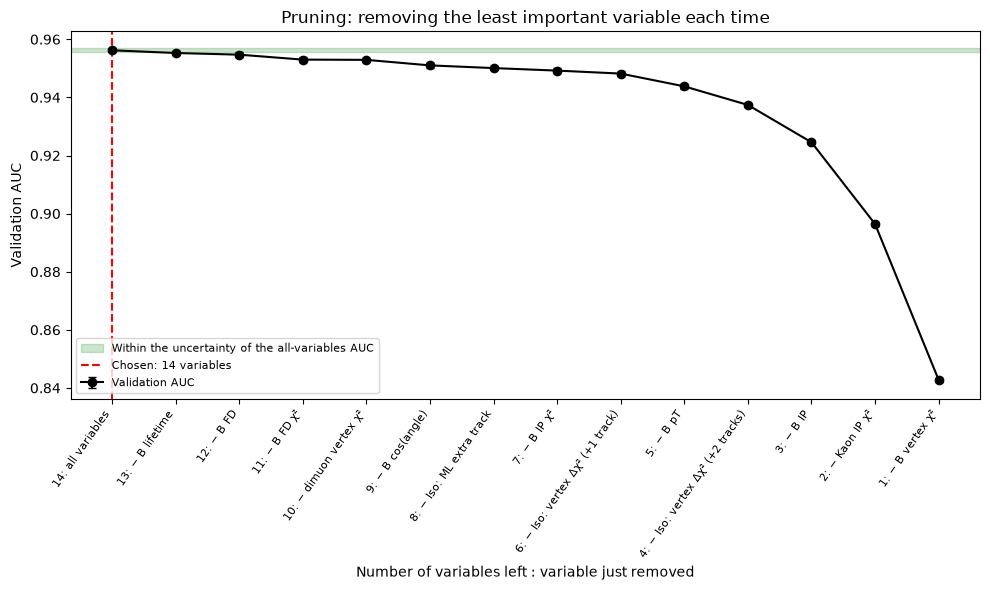

In [31]:
make_full_pruning_curve = True

if make_full_pruning_curve:
    #Start from where the pruning above stopped (no model is trained twice)
    full_history = [(n, auc, removed) for n, auc, removed, _ in history]
    current_full = list(history[-1][3])
    bdt_full = trial_bdt if len(history) > 1 else full_bdt

    while len(current_full) > 1:
        weakest = current_full[int(np.argmin(bdt_full.feature_importances_))]
        current_full = [v for v in current_full if v != weakest]
        bdt_full, auc = train_bdt(current_full)
        full_history.append((len(current_full), auc, weakest))
        print(f'Removed {weakest} -> {len(current_full)} variables, validation AUC {auc:.4f}', flush=True)

    print()
    print(tabulate(full_history, headers=['Variables', 'Validation AUC', 'Removed'], floatfmt='.4f'))

    def short_name(variable):
        #Shorter variable names for the axis labels
        for long, short in (('Isolation: B vertex delta chi2 adding one extra track (best fit)', 'Iso: vertex Δχ² (+1 track)'),
                            ('Isolation: B vertex delta chi2 adding two extra tracks (best fits)', 'Iso: vertex Δχ² (+2 tracks)'),
                            ('Isolation: ML output of best fitting extra track', 'Iso: ML extra track'),
                            ('cos(angle) between line-of-flight and momentum', 'cos(angle)'),
                            ('magnitude of momentum transverse to beam', 'pT'), ('magnitude of momentum', 'p'),
                            (' wrt primary vertex', ''), ('impact parameter', 'IP'), ('flight distance', 'FD'),
                            ('decay vertex fit chi2', 'vertex χ²'), ('dimuon-system', 'dimuon'), (' chi2', ' χ²')):
            variable = variable.replace(long, short)
        return variable

    n_vars = np.array([h[0] for h in full_history])
    aucs   = np.array([h[1] for h in full_history])
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.errorbar(n_vars, aucs, yerr=auc_uncertainty, fmt='o-', color='black', capsize=3, label='Validation AUC')
    ax.axhspan(full_auc - auc_uncertainty, full_auc + auc_uncertainty, color='green', alpha=0.2,
               label='Within the uncertainty of the all-variables AUC')
    ax.axvline(len(training_variables), color='red', linestyle='--', label=f'Chosen: {len(training_variables)} variables')
    #Each tick: how many variables are left, and which variable was just removed to get there
    ax.set_xticks(n_vars)
    ax.set_xticklabels([f'{n_vars[0]}: all variables'] + [f'{n}: − {short_name(removed)}' for n, _, removed in full_history[1:]],
                       rotation=55, ha='right', fontsize=8)
    ax.set_xlabel('Number of variables left : variable just removed')
    ax.set_ylabel('Validation AUC')
    ax.set_title('Pruning: removing the least important variable each time')
    ax.invert_xaxis()   #read left to right: all variables -> one variable
    ax.legend(fontsize=8, loc='lower left')
    fig.tight_layout()
    plt.show()

### Final model
Retrain on the chosen variables. The test sample is used here for the first time.

In [32]:
model, val_auc = train_bdt(training_variables)

x_test, y_test = make_xy(signal_test, background_test, training_variables)
test_auc = roc_auc_score(y_test, model.predict_proba(x_test)[:, 1])
print(f'Validation AUC: {val_auc:.4f}, test AUC: {test_auc:.4f}')

Validation AUC: 0.9562, test AUC: 0.9563


### Results on the test sample

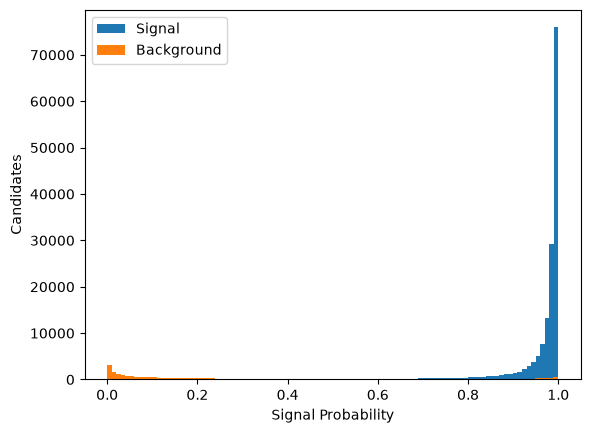

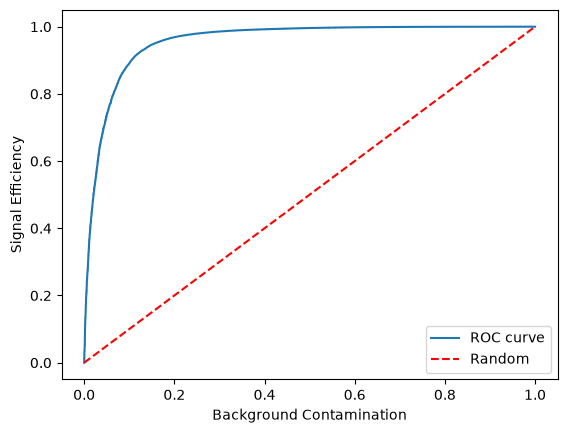

In [33]:
from sklearn.metrics import roc_curve

test_prediction = model.predict_proba(x_test)

plt.hist([p[1] for p,cls in zip(test_prediction, y_test) if cls == 1], bins=100, label='Signal')
plt.hist([p[1] for p,cls in zip(test_prediction, y_test) if cls == 0], bins=100, label='Background')
plt.xlabel(r'Signal Probability')
plt.ylabel(r'Candidates')
plt.legend()
plt.show()

background_accepted, signal_accepted, probabilities_tested = roc_curve(y_test, test_prediction[:,1])
plt.plot(background_accepted, signal_accepted, label='ROC curve')
plt.plot([0,1], [0,1], color='red', linestyle='--', label = 'Random')
plt.xlabel(r'Background Contamination')
plt.ylabel(r'Signal Efficiency')
plt.legend()
plt.show()

8. Overtraining check

"Overtraining" means the model has memorised its training events instead of learning patterns that are true for all events. If so, it scores its own training events better than new events, and its performance on real data will be worse than it looks.

To check, we compare the model's output for **training** events (filled bars) and **test** events (points) that it has never seen, separately for signal and background. If there is no overtraining, the two match within their error bars.

We also compare the **train AUC with the test AUC**. The training value is always a little higher; a gap much bigger than the AUC's uncertainty means overtraining.

Train AUC: 0.9588, test AUC: 0.9563, difference: 0.0025 (AUC uncertainty is about 0.0008)


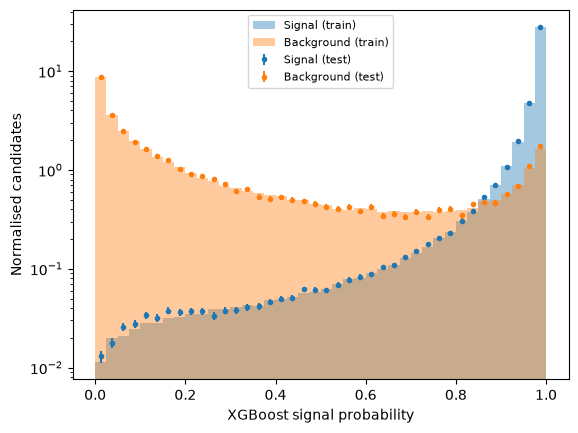

In [34]:
#Model output for every training and test event
prob = {
    ('Signal', 'train'):     model.predict_proba(signal_train[training_variables])[:, 1],
    ('Signal', 'test'):      model.predict_proba(signal_test[training_variables])[:, 1],
    ('Background', 'train'): model.predict_proba(background_train[training_variables])[:, 1],
    ('Background', 'test'):  model.predict_proba(background_test[training_variables])[:, 1],
}

train_auc = roc_auc_score(np.r_[np.ones(len(prob['Signal', 'train'])), np.zeros(len(prob['Background', 'train']))],
                          np.r_[prob['Signal', 'train'], prob['Background', 'train']])
print(f'Train AUC: {train_auc:.4f}, test AUC: {test_auc:.4f}, difference: {train_auc - test_auc:.4f} '
      f'(AUC uncertainty is about {auc_uncertainty:.4f})')

edges = np.linspace(0, 1, 41)
centres = 0.5 * (edges[1:] + edges[:-1])
colours = {'Signal': 'tab:blue', 'Background': 'tab:orange'}

for kind in ('Signal', 'Background'):
    train, test = prob[kind, 'train'], prob[kind, 'test']

    #Training events as filled bars, normalised to area 1
    plt.hist(train, bins=edges, density=True, alpha=0.4, color=colours[kind], label=f'{kind} (train)')

    #Test events as points with error bars, normalised the same way
    counts, _ = np.histogram(test, bins=edges)
    scale = 1 / (len(test) * (edges[1] - edges[0]))
    plt.errorbar(centres, counts * scale, yerr=np.sqrt(counts) * scale, fmt='o', markersize=3,
                 color=colours[kind], label=f'{kind} (test)')

plt.yscale('log')   #log scale so the small tails in the middle are visible too
plt.xlabel('XGBoost signal probability')
plt.ylabel('Normalised candidates')
plt.legend(fontsize=8)
plt.show()

### Apply the selection to the full dataset

In [35]:
#Signal probability for every candidate in the dataset
signal_probability = model.predict_proba(data[training_variables])[:, 1]

#XGBoost cut. It is chosen with the S/sqrt(S+B) sweep in Task 6 ("Choosing the XGBoost cut").
#To change it, change this number and re-run the notebook from this cell onwards.
bdt_cut = 0.9
passes_bdt = signal_probability > bdt_cut

## Task 5: K+ mu- two body system

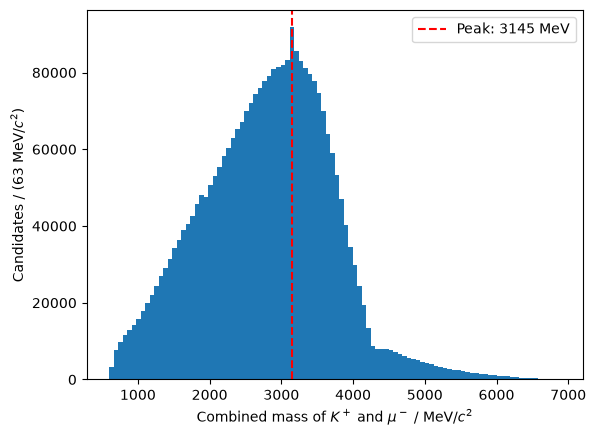

In [36]:
#Using the energies stored in the data (the detector's own mass assignments)
kmu_mass = two_body_mass(data, 'Kaon', 'Opposite-sign muon')

plot_mass(kmu_mass, r'Combined mass of $K^+$ and $\mu^-$ / MeV/$c^2$', show_peak=True)

### Masses correct
Kaon given the kaon mass, muon given the muon mass.

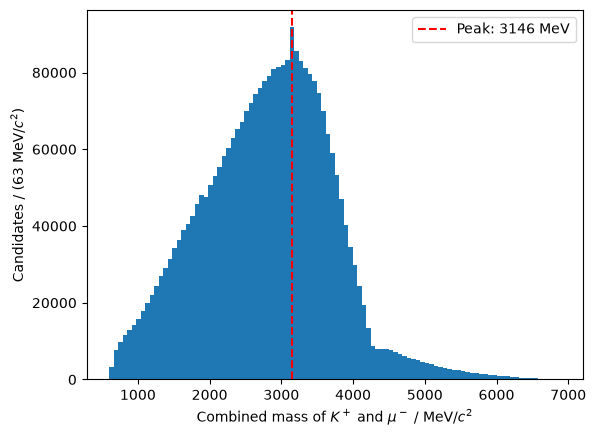

In [37]:
kmu_mass_correct = two_body_mass(data, 'Kaon', 'Opposite-sign muon', M_KAON, M_MUON)

plot_mass(kmu_mass_correct, r'Combined mass of $K^+$ and $\mu^-$ / MeV/$c^2$', show_peak=True)

## Kaon mistaken for a muon (so muon has kaon mass)

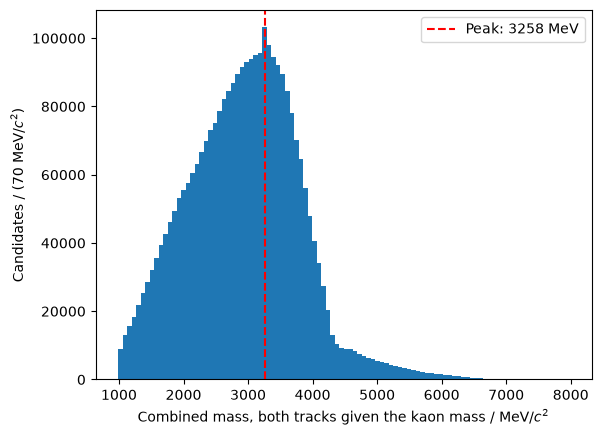

In [38]:
kmu_mass_as_kk = two_body_mass(data, 'Kaon', 'Opposite-sign muon', M_KAON, M_KAON)

plot_mass(kmu_mass_as_kk, r'Combined mass, both tracks given the kaon mass / MeV/$c^2$', show_peak=True)

## Muon mistaken for a kaon (so kaon has muon mass)

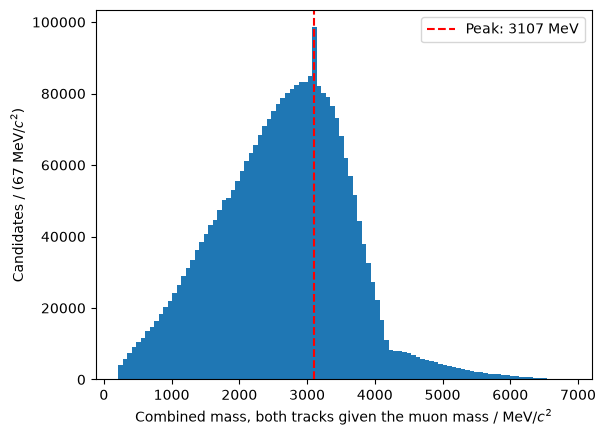

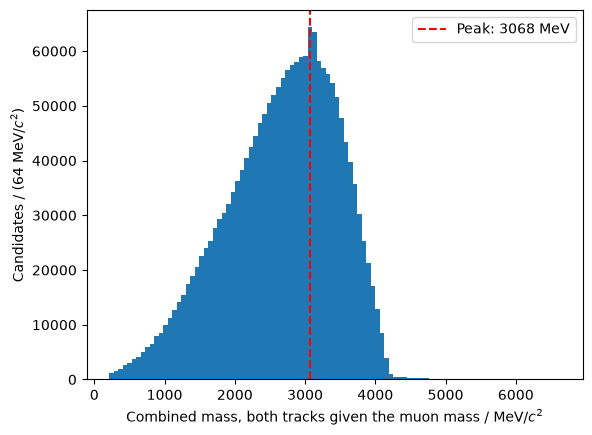

In [39]:
kmu_mass_as_mumu = two_body_mass(data, 'Kaon', 'Opposite-sign muon', M_MUON, M_MUON)

#before the XGBoost selection
plot_mass(kmu_mass_as_mumu, r'Combined mass, both tracks given the muon mass / MeV/$c^2$', show_peak=True)

#after the XGBoost selection
plot_mass(kmu_mass_as_mumu[passes_bdt], r'Combined mass, both tracks given the muon mass / MeV/$c^2$', show_peak=True)

## Kill the peak

after the XGBoost algorithm is used to cut out the background noise the mode is exactly 3097. In general, the peak being close to 3000 MeV/c^2 seems to be a coincidence (from the research that I've done. So a peak within that region or so is normal.). However, the peak at 3097 specifically is not normal. 

We previously cleaned the J/psi decays. However, that assumes muons are identified correctly. If one of the muons registered as a kaon in the detector then the 3097 J/psi decay would register as a 3097 kaon + muon combination. This is the peak we observe here. 

We remove these events by cutting out ±50 MeV around 3097 MeV in this kaon + muon mass (with both tracks given the muon mass). That window is about 3.8σ of the J/ψ peak's core width (13.1 MeV, from the Crystal Ball fit in Task 2), so it removes essentially all of these swapped events, while only removing a small fraction of real rare decays. The same method is used for the ψ(2S) below.

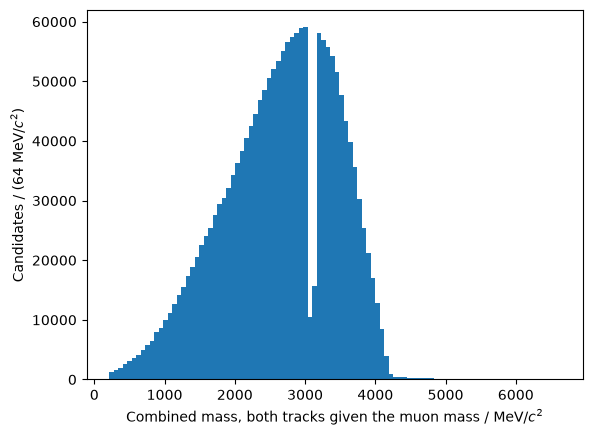

In [40]:
#Veto candidates where the kaon + muon look like a J/psi (the kaon was really a muon)
jpsi_swap_veto = abs(kmu_mass_as_mumu - M_JPSI) > 50

plot_mass(kmu_mass_as_mumu[passes_bdt & jpsi_swap_veto], r'Combined mass, both tracks given the muon mass / MeV/$c^2$')

## ψ(2S) with the kaon and a muon swapped
Exactly the same mistake as the J/ψ above, but for B → ψ(2S) K: one of the ψ(2S) muons is recorded as the "kaon", and the real kaon as a muon.
The dimuon vetoes don't catch it, because the pair *labelled* as the two muons is not really the ψ(2S) pair.
If we give the "kaon" the muon mass, the "kaon" + μ⁻ pair is really the ψ(2S)'s two muons, so these events pile up at the ψ(2S) mass (3686 MeV).

There are about 12× fewer ψ(2S) than J/ψ decays, so this peak is much smaller than the J/ψ one. We fit it with a Gaussian plus an exponential to check that it is really there.

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_397, Composed_autoparam_398]] data=[<zfit.Data: Data obs=('psi2s swap mass',) shape=(5993, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 0.00019 │         33427.43 |  1123.723 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                          value  (rounded)        hesse    at limit
--------------------------  ------------------  -----------  ----------
psi2s_swap_yield                        585.38  +/-      61       False
psi2s_swap_backgroundYield             5407.94  +/-      93       False
psi2s_swap_m

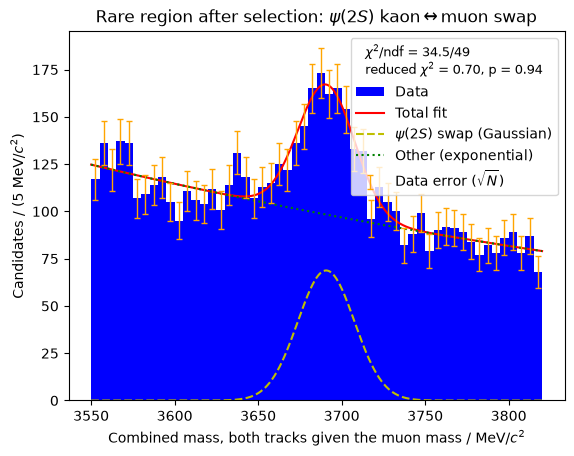

In [88]:
#Candidates in the rare region after the selection and the J/psi swap veto
rare_selected = not_jpsi & not_psi2s & passes_bdt & jpsi_swap_veto

#Same mass as for the J/psi swap: both tracks given the muon mass. Zoom in around the psi(2S)
psi2s_swap_space = zfit.Space('psi2s swap mass', (3550, 3820))

psi2s_swap_mean  = zfit.Parameter('psi2s_swap_mean',  3686, 3650, 3720)
psi2s_swap_sigma = zfit.Parameter('psi2s_swap_sigma', 15,   3,    50)
psi2s_swap_yield = zfit.Parameter('psi2s_swap_yield', 50,   0,    1e6)
psi2s_swap_lam   = zfit.Parameter('psi2s_swap_exponent', -0.002, -0.1, 0.1)
psi2s_swap_bkg   = zfit.Parameter('psi2s_swap_backgroundYield', 500, 0, 1e6)

psi2s_swap_peak = zfit.pdf.Gauss(obs=psi2s_swap_space, mu=psi2s_swap_mean, sigma=psi2s_swap_sigma, extended=psi2s_swap_yield)
psi2s_swap_flat = zfit.pdf.Exponential(obs=psi2s_swap_space, lam=psi2s_swap_lam, extended=psi2s_swap_bkg)
psi2s_swap_PDF  = zfit.pdf.SumPDF([psi2s_swap_peak, psi2s_swap_flat])

result_psi2s_swap = fit_and_plot(kmu_mass_as_mumu[rare_selected], psi2s_swap_PDF,
                                 components={r'$\psi(2S)$ swap (Gaussian)': psi2s_swap_peak, 'Other (exponential)': psi2s_swap_flat},
                                 bins=54, xlabel=r'Combined mass, both tracks given the muon mass / MeV/$c^2$',
                                 title=r'Rare region after selection: $\psi(2S)$ kaon$\leftrightarrow$muon swap')

There is a small peak at the ψ(2S) mass. We remove it in the same way as the J/ψ swap: cut out ±50 MeV around 3686 MeV. That is about 3σ of the ψ(2S) peak width (15.8 MeV from the Crystal Ball fit in Task 2), the same as the window used for the J/ψ swap.

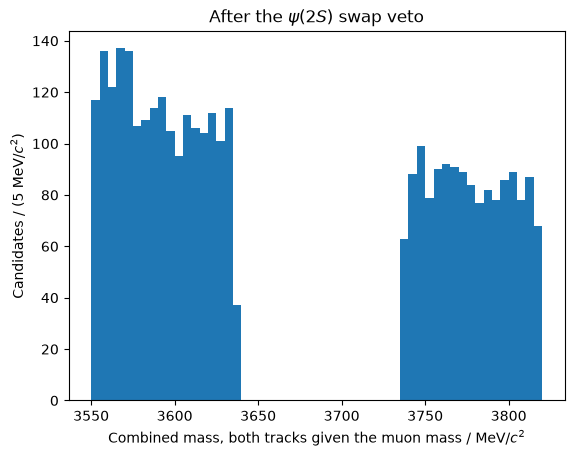

In [42]:
#Veto candidates where the kaon + muon look like a psi(2S) (the kaon was really a muon)
psi2s_swap_veto = abs(kmu_mass_as_mumu - M_PSI2S) > 50

plot_mass(kmu_mass_as_mumu[rare_selected & psi2s_swap_veto], r'Combined mass, both tracks given the muon mass / MeV/$c^2$',
          bins=54, range=(3550, 3820), title=r'After the $\psi(2S)$ swap veto')

## D⁰ → K⁺π⁻ with the pion mistaken for a muon
D⁰ mesons are very common in B decays (e.g. B⁺ → D̄⁰ π⁺, or B⁺ → D̄⁰ μ⁺ ν), and a D̄⁰ often decays to K⁺π⁻.
Pions are sometimes mistaken for muons, because they can decay into a muon or travel far enough to reach the muon detectors. If the π⁻ is recorded as our μ⁻, the event can look like a B → K μμ candidate.

To find these, we give the μ⁻ the **pion mass** and recompute the K⁺ + "μ⁻" mass. Real D⁰ decays pile up at the D⁰ mass (1865 MeV).

As a check, we do the same with the *other* muon (the same-sign μ⁺). A K⁺ and a π⁺ can't come from a D⁰ (the charges don't add up to zero), so there should be **no** peak there.

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_400, Composed_autoparam_401]] data=[<zfit.Data: Data obs=('K pi mass',) shape=(6664, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 7.8e-06 │         32824.39 | -245.3993 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                  value  (rounded)        hesse    at limit
------------------  ------------------  -----------  ----------
d0_yield                       2235.29  +/-      63       False
d0_backgroundYield             4428.55  +/-      78       False
d0_mean                        1865.51  +/-    0.2

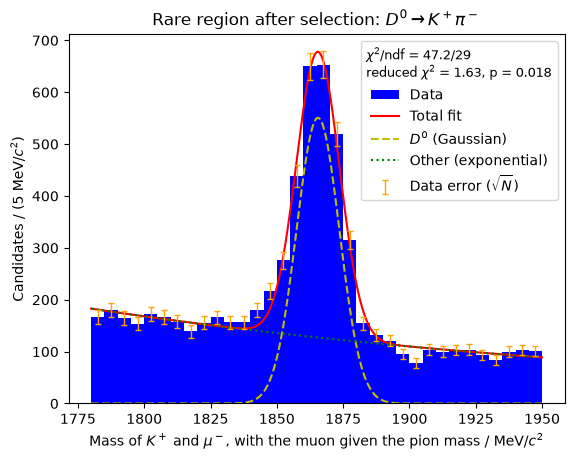

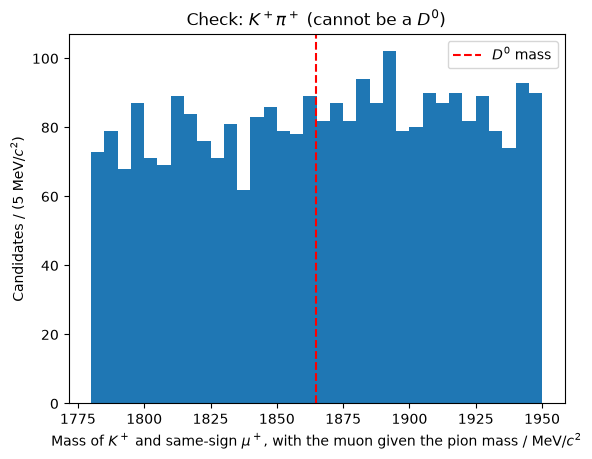

In [89]:
#K+ and the opposite-sign "muon", with the muon given the pion mass
kpi_mass = two_body_mass(data, 'Kaon', 'Opposite-sign muon', M_KAON, M_PION)

d0_space = zfit.Space('K pi mass', (1780, 1950))

d0_mean  = zfit.Parameter('d0_mean',  1865, 1840, 1890)
d0_sigma = zfit.Parameter('d0_sigma', 8,    1,    40)
d0_yield = zfit.Parameter('d0_yield', 100,  0,    1e6)
d0_lam   = zfit.Parameter('d0_exponent', -0.003, -0.1, 0.1)
d0_bkg   = zfit.Parameter('d0_backgroundYield', 500, 0, 1e6)

d0_peak = zfit.pdf.Gauss(obs=d0_space, mu=d0_mean, sigma=d0_sigma, extended=d0_yield)
d0_flat = zfit.pdf.Exponential(obs=d0_space, lam=d0_lam, extended=d0_bkg)
d0_PDF  = zfit.pdf.SumPDF([d0_peak, d0_flat])

result_d0 = fit_and_plot(kpi_mass[rare_selected & psi2s_swap_veto], d0_PDF,
                         components={r'$D^0$ (Gaussian)': d0_peak, 'Other (exponential)': d0_flat},
                         bins=34, xlabel=r'Mass of $K^+$ and $\mu^-$, with the muon given the pion mass / MeV/$c^2$',
                         title=r'Rare region after selection: $D^0 \to K^+\pi^-$')

d0_mu_fit    = result_d0.params[d0_mean]['value']
d0_sigma_fit = result_d0.params[d0_sigma]['value']

#Check: K+ with the SAME-sign muon given the pion mass. K+ pi+ can't be a D0, so no peak is expected
kpi_mass_samesign = two_body_mass(data, 'Kaon', 'Same-sign muon', M_KAON, M_PION)
plt.axvline(M_D0, color='red', linestyle='--', label=r'$D^0$ mass')
plt.legend()
plot_mass(kpi_mass_samesign[rare_selected & psi2s_swap_veto], r'Mass of $K^+$ and same-sign $\mu^+$, with the muon given the pion mass / MeV/$c^2$',
          bins=34, range=(1780, 1950), title=r'Check: $K^+\pi^+$ (cannot be a $D^0$)')

There is a clear peak at the D⁰ mass, about 8 MeV wide, and no peak in the check with the other muon, so these really are D⁰ → K⁺π⁻ decays.
We cut out ±25 MeV around the D⁰ mass, which is about 3σ of the fitted width.

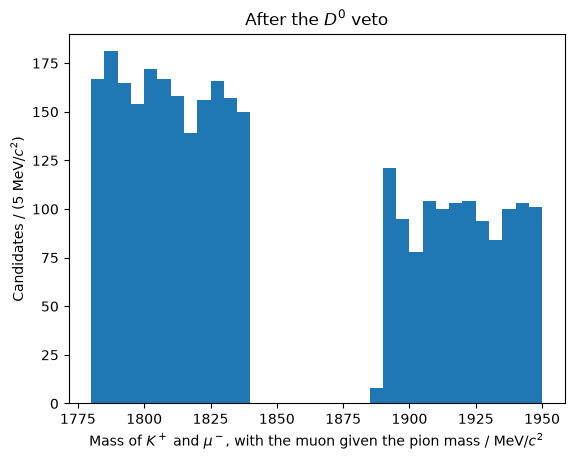

In [44]:
#Veto candidates where the K+ and the "mu-" look like a D0 -> K+ pi- decay
d0_veto = abs(kpi_mass - M_D0) > 25

plot_mass(kpi_mass[rare_selected & psi2s_swap_veto & d0_veto],
          r'Mass of $K^+$ and $\mu^-$, with the muon given the pion mass / MeV/$c^2$',
          bins=34, range=(1780, 1950), title=r'After the $D^0$ veto')

## Task 6: Finalising the B count

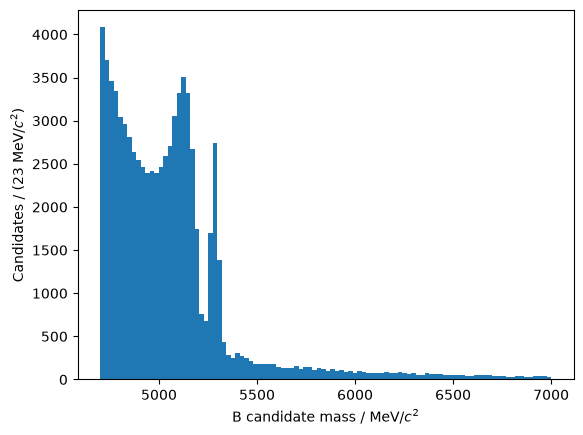

In [45]:
#All cuts for the rare B -> K mu mu decay together
keep = (not_jpsi            #dimuon not a J/psi
    & not_psi2s             #dimuon not a psi(2S)
    & passes_bdt            #XGBoost selection
    & jpsi_swap_veto        #kaon + muon not a J/psi
    & psi2s_swap_veto       #kaon + muon not a psi(2S)
    & d0_veto               #kaon + muon (as a pion) not a D0
)

plot_mass(b_mass[keep], r'B candidate mass / MeV/$c^2$')

### The bump below the B peak
After all the cuts there is a large bump at about 5000–5200 MeV, below the B peak at 5280 MeV. It is background, and it comes from two kinds of real B decays:

1. **B decays where a particle was missed**, e.g. B → K* μμ, where the K* decays to K π and the pion is not picked up. Losing the pion's energy makes the B mass come out too low. This kind can't be heavier than the B mass minus the pion mass, about 5140 MeV, so it stops at about 5180 MeV.
2. **B → J/ψ K decays where the J/ψ gave off a photon.** These reach up to about 5240 MeV. The next markdown explains them.

There are two ways to deal with it:
- **Option A:** just cut away everything below 5220 MeV and fit what is left.
- **Option B:** first remove the J/ψ photon events with a "photon veto", then cut away everything below 5180 MeV and fit what is left.

Both fits use the same shape: a double-sided Crystal Ball for the B peak plus an exponential for the background. The Crystal Ball's width and tails are **fixed** to the values from the big B → J/ψ K fit in Task 1. The rare-decay sample is too small to measure them itself, and the peak should have the same shape in both decays (same B, same detector). Only the peak position, the two yields and the background slope are left free.

In [46]:
def fit_rare_b_mass(values, lower, name, upper=5700):
    #Fit the B mass between `lower` and `upper` with a double-sided Crystal Ball (shape fixed from the
    #B -> J/psi K fit in Task 1) plus an exponential. `name` keeps the parameter names of each fit different.
    #Returns the fit result and the signal-yield parameter.
    space = zfit.Space('B invariant mass', (lower, upper))

    #Fixed shape, copied from the Task 1 fit (floating=False means the fit can't change them)
    fixed = {p: zfit.Parameter(f'{name}_{p}', result_b_cb.params[par]['value'], floating=False)
             for p, par in [('sigma', b_cb_sigma), ('alphaL', b_cb_alphaL), ('nL', b_cb_nL),
                            ('alphaR', b_cb_alphaR), ('nR', b_cb_nR)]}

    mean         = zfit.Parameter(f'{name}_mean', b_cb_mu_fit, 5250, 5320)
    signal_yield = zfit.Parameter(f'{name}_signalYield', 500, 0, 1e6)
    signal = zfit.pdf.DoubleCB(obs=space, mu=mean, sigma=fixed['sigma'],
                               alphal=fixed['alphaL'], nl=fixed['nL'], alphar=fixed['alphaR'], nr=fixed['nR'],
                               extended=signal_yield)

    exponent         = zfit.Parameter(f'{name}_exponent', -0.003, -0.1, 0.1)
    background_yield = zfit.Parameter(f'{name}_backgroundYield', 200, 0, 1e6)
    background = zfit.pdf.Exponential(obs=space, lam=exponent, extended=background_yield)

    total = zfit.pdf.SumPDF([signal, background])
    result = fit_and_plot(values, total,
                          components={'Signal (double Crystal Ball)': signal, 'Background (exponential)': background},
                          bins=int((upper - lower) / 10), xlabel=r'B candidate mass / MeV/$c^2$',
                          title=f'Rare B decays, fit from {lower} MeV', show_pulls=True)
    print(f'\nSignal yield: {result.params[signal_yield]["value"]:.0f} +/- {result.params[signal_yield]["hesse"]["error"]:.0f}')
    return result, signal_yield

### Option A: chop at 5220 MeV
The simplest choice: start the fit at 5220 MeV, above almost all of the bump. A few tens of J/ψ photon events (see below) are still left in the first 20 MeV of the fit range. They are a few percent of the signal, and the exponential absorbs some of them, so they could only push the signal count up slightly.

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_403, Composed_autoparam_404]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(10260, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 1.5e-06 │         57386.93 | -8554.195 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                      value  (rounded)        hesse    at limit
----------------------  ------------------  -----------  ----------
rare_A_signalYield                 5378.77  +/-      94       False
rare_A_backgroundYield             4881.36  +/-      91       False
rare_A_mean               

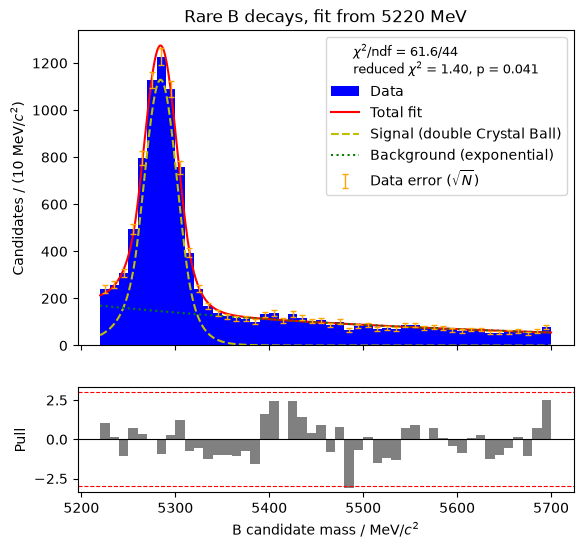


Signal yield: 5379 +/- 94


In [90]:
chop_A = 5220
result_A, yield_A = fit_rare_b_mass(b_mass[keep], chop_A, 'rare_A')
n_rare_A = result_A.params[yield_A]['value']

### Option B: the photon veto, then chop at 5180 MeV

**What goes wrong.** In a B → J/ψ K decay, the J/ψ sometimes gives off a photon (a particle of light) as it decays to two muons. The detector doesn't see the photon. So the energy the photon carried away is missing from our calculation, and two masses come out too low **at the same time**:
- the **dimuon mass** comes out below 3097 MeV. If the photon took more than about 100 MeV, it falls below our J/ψ veto window, so the event is no longer removed as a J/ψ;
- the **B mass** comes out too low by about the same amount, so it lands in the bump below the B peak.

**The trick.** Both masses drop by about the same amount (the photon's energy), so the **gap between them stays the same**, like two people standing on a staircase who both step down one stair: their heights change, but the difference in their heights doesn't. For these events

  B mass − dimuon mass ≈ 5284 − 3100 ≈ **2184 MeV**, no matter how much energy the photon took.

The same thing happens for B → ψ(2S) K, where the gap stays at 5284 − 3690 ≈ **1594 MeV**.

**The photon veto** removes every candidate whose gap is within ±100 MeV of 2184 or 1594 (the same ±100 MeV as our J/ψ and ψ(2S) vetoes).

**Why it doesn't remove real rare decays in the B peak.** A real rare decay has the *correct* B mass, about 5284 MeV. For its gap to be 2184 ± 100, its dimuon mass would have to be 3100 ± 100, and those events were already removed by the J/ψ veto. So the photon veto costs (almost) no signal, and it is much better than just making the J/ψ veto wider, which *would* throw away real rare decays.

With the photon events gone, only the "missed particle" decays like B → K* μμ are left in the bump, and they stop at about 5180 MeV, so we can start the fit lower than in Option A.

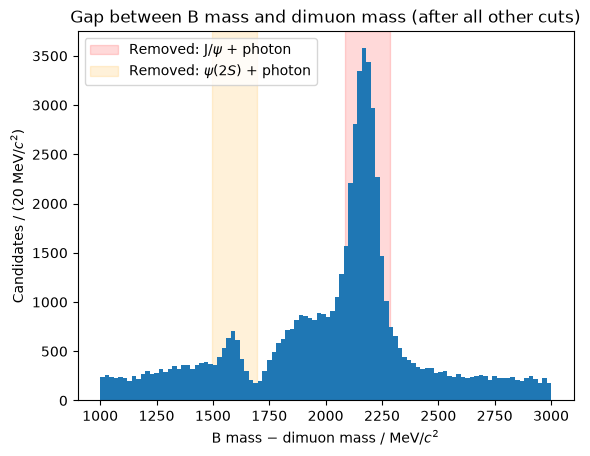

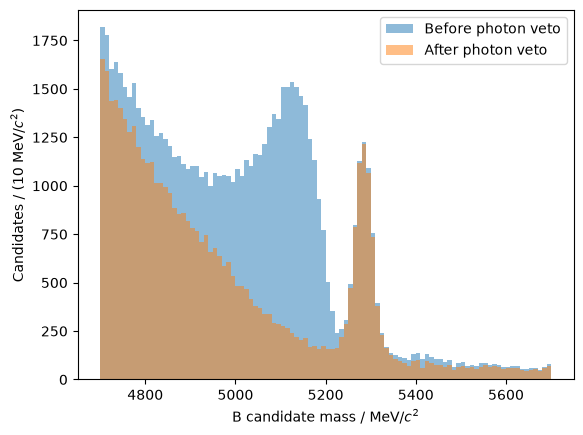

Photon veto removes 28994 candidates, of which 186 are in the B peak window


In [48]:
#Gap between the B mass and the dimuon mass. For J/psi (or psi(2S)) events that lost a photon it stays the same
mass_difference = b_mass - dimuon_mass
jpsi_gap  = b_cb_mu_fit - jpsi_cb_mu_fit     #about 2184 MeV
psi2s_gap = b_cb_mu_fit - psi2s_cb_mu_fit    #about 1594 MeV

photon_veto = (abs(mass_difference - jpsi_gap) > 100) & (abs(mass_difference - psi2s_gap) > 100)

#Before the veto: two spikes at the J/psi and psi(2S) gaps
plt.axvspan(jpsi_gap - 100, jpsi_gap + 100, color='red', alpha=0.15, label=r'Removed: J/$\psi$ + photon')
plt.axvspan(psi2s_gap - 100, psi2s_gap + 100, color='orange', alpha=0.15, label=r'Removed: $\psi(2S)$ + photon')
plt.legend()
plot_mass(mass_difference[keep], r'B mass $-$ dimuon mass / MeV/$c^2$', bins=100, range=(1000, 3000),
          title='Gap between B mass and dimuon mass (after all other cuts)')

#B mass before and after the photon veto
plt.hist(b_mass[keep], bins=100, range=(4700, 5700), alpha=0.5, label='Before photon veto')
plt.hist(b_mass[keep & photon_veto], bins=100, range=(4700, 5700), alpha=0.5, label='After photon veto')
plt.xlabel(r'B candidate mass / MeV/$c^2$')
plt.ylabel(r'Candidates / (10 MeV/$c^2$)')
plt.legend()
plt.show()

in_peak = abs(b_mass - b_cb_mu_fit) < 3*b_cb_sigma_fit
print(f'Photon veto removes {int((keep & ~photon_veto).sum())} candidates, '
      f'of which {int((keep & ~photon_veto & in_peak).sum())} are in the B peak window')

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_406, Composed_autoparam_407]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(9996, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 2.6e-06 │         56128.94 | -7682.782 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                      value  (rounded)        hesse    at limit
----------------------  ------------------  -----------  ----------
rare_B_signalYield                 5649.15  +/-      89       False
rare_B_backgroundYield             4346.77  +/-      82       False
rare_B_mean                

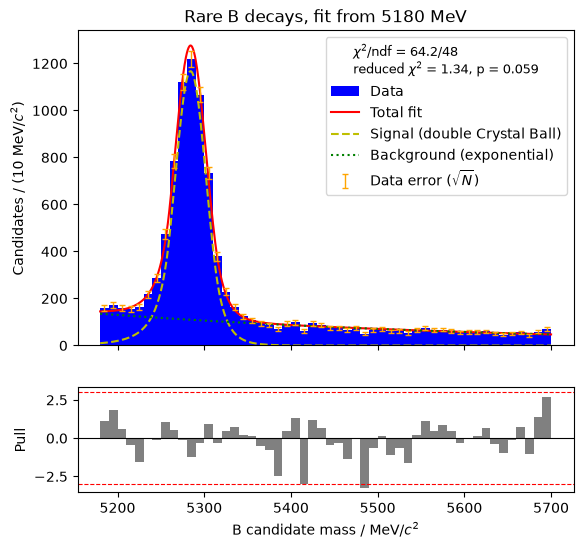


Signal yield: 5649 +/- 89


In [91]:
chop_B = 5180
result_B, yield_B = fit_rare_b_mass(b_mass[keep & photon_veto], chop_B, 'rare_B')
n_rare_B = result_B.params[yield_B]['value']

## Choosing the XGBoost cut: the S/√(S+B) sweep
(This is part of Task 4, "how you may best choose where to place any cuts". It sits here because it needs the number of rare decays from the fit just above.)

**What the cut does.** XGBoost gives every candidate a score from 0 to 1, and we keep candidates above the cut (`bdt_cut`). A tighter cut throws away more background, but also more real signal. A looser cut keeps more signal, but lets in more background. We want the cut that measures A_CP **most precisely**.

**Why S/√(S+B)?** Let S be the number of signal events and B the number of background events in the B-mass peak window.
- Measuring A is like flipping coins: each signal event is a B⁻ ("heads") or a B⁺ ("tails"). With S coins, chance alone moves the heads/tails balance by about 1/√S. So without background, the error on A is about √S / S.
- Background makes it worse: we count S + B events in the window and subtract the background, and the count jiggles by about √(S+B). So the error on A is about **√(S+B) / S**.
- Turned upside down, that is **S/√(S+B) = 1 / (error on A)**. Making S/√(S+B) as big as possible makes the error on A as small as possible.

**Why we can't just count the peak to get S.** The peak window contains background as well as signal (background is spread across all masses, including under the peak). Counting the window gives S + B, not S.

**How we get B (background in the peak window).**
1. Look above the peak, at 5400–7000 MeV. Nothing real is there, only random-combination background.
2. Count the events there that pass the cut.
3. Work out how much of that background would sit under the peak. The background isn't flat: it slowly gets smaller as the mass goes up, like exp(slope × mass). So we measure the slope from those same background events (at each cut), and use it to scale the count to the peak window.

(Why not use the background slope from the fit above? That fit starts at 5180 MeV, where a few leftover "missed particle" decays make the background look steeper than the random-combination background really is.)

**How we get S (signal in the peak window).**
1. **How many rare decays were there before the XGBoost cut?** At the current cut we have counted them with the fit above. J/ψ K test events tell us what fraction of real signal survives that cut. So: rare decays before the cut = (rare decays counted at the current cut) ÷ (fraction surviving the current cut).
2. **How many survive any other cut?** That number times the fraction of J/ψ K test events surviving that cut.

We use J/ψ K for the fractions because it is real signal and its kaons and B mesons look just like the rare decay's (checked in the Task 8 cross-checks). We use its *test* events because XGBoost never trained on them, so the fractions are honest. And we don't count the rare peak at every cut, because the rare signal jumps around randomly: picking the cut where it happened to jump up would make the result look better than it really is. The J/ψ K fractions come from tens of thousands of events, so they are smooth.

**How to use the result.** The best cut is the highest point of the S/√(S+B) curve. The top is usually flat, so if several cuts are almost as good (within 2% of the best), we take the **loosest** of them: it keeps the most signal and loses nothing. Then set `bdt_cut` to that value (in Task 4, "Apply the selection to the full dataset") and re-run the notebook from there. When the sweep is re-run after that, the current cut should come out at (or very near) the top.

In [50]:
#Every cut to try: coarse steps up to 0.9, finer near the top, where the XGBoost scores bunch up.
#(The loosest cut comes first, so the background slope can always be measured at the start.)
cuts = np.unique(np.round(np.r_[np.arange(0.50, 0.90, 0.05), np.arange(0.90, 0.99, 0.01), np.arange(0.990, 0.9995, 0.001)], 4))

#Rare-decay region with every cut EXCEPT the XGBoost one, for counting the background above the peak.
#(The photon veto is left out here: above the peak it removes a band of random background, but under the peak
#that band lines up with the J/psi veto and removes almost nothing extra, so including it would make B too small.)
rare_before_bdt = not_jpsi & not_psi2s & jpsi_swap_veto & psi2s_swap_veto & d0_veto

#The B-mass peak window (same as in_peak) and the background-only region above the peak
window_lo, window_hi = b_cb_mu_fit - 3*b_cb_sigma_fit, b_cb_mu_fit + 3*b_cb_sigma_fit
side_lo, side_hi     = 5400, 7000          #above the peak: only random-combination background lives here
in_sideband          = (b_mass > side_lo) & (b_mass < side_hi)

#--- B: background in the window, from the background-only region above the peak.
#The background falls as exp(slope * mass). We measure the slope from the events above the peak (at each cut),
#then use it to work out how much of that background sits inside the peak window.
from scipy.optimize import minimize_scalar

def background_slope(masses, lo, hi):
    #Best-fit slope of an exponential exp(slope * m) for masses between lo and hi (maximum likelihood)
    x, width = np.asarray(masses) - lo, hi - lo
    def minus_log_likelihood(s):
        return -(len(x) * np.log(-s / (1 - np.exp(s * width))) + s * np.sum(x))
    return minimize_scalar(minus_log_likelihood, bounds=(-0.02, -1e-6), method='bounded').x

def window_over_sideband(slope):
    #(background inside the window) / (background in the sideband) for an exponential with this slope
    area = lambda a, b: np.exp(slope * (b - side_lo)) - np.exp(slope * (a - side_lo))
    return area(window_lo, window_hi) / area(side_lo, side_hi)

print(f'Background-only region above the peak: {side_lo}-{side_hi} MeV; peak window: {window_lo:.0f}-{window_hi:.0f} MeV')

#--- S: signal in the window
#Fraction of J/psi K test events (real signal, never seen in training) that survive a cut
def signal_fraction(cut):
    return np.mean(prob['Signal', 'test'] > cut)

#Rare decays counted at the current cut (Option B fit), but only the part inside the window:
#fraction of the signal shape (same shape as in the fit) that lies inside the window
signal_shape = zfit.pdf.DoubleCB(obs=zfit.Space('B invariant mass', (chop_B, 5700)),
                                 mu=result_B.params['rare_B_mean']['value'], sigma=result_b_cb.params[b_cb_sigma]['value'],
                                 alphal=result_b_cb.params[b_cb_alphaL]['value'], nl=result_b_cb.params[b_cb_nL]['value'],
                                 alphar=result_b_cb.params[b_cb_alphaR]['value'], nr=result_b_cb.params[b_cb_nR]['value'])
in_window_fraction = float(np.ravel(signal_shape.integrate(limits=(window_lo, window_hi)))[0])
S_now = n_rare_B * in_window_fraction

#Step 1: rare decays (in the window) before the XGBoost cut. Step 2 is in the loop below
S_before_cut = S_now / signal_fraction(bdt_cut)
print(f'Current cut {bdt_cut}: {n_rare_B:.0f} rare decays fitted, {S_now:.0f} of them in the window '
      f'({in_window_fraction:.1%}); {signal_fraction(bdt_cut):.1%} of signal survives this cut, '
      f'so there were about {S_before_cut:.0f} in the window before the cut')

rows = []
for cut in cuts:
    S = S_before_cut * signal_fraction(cut)                                         #step 2
    side_masses = b_mass[rare_before_bdt & in_sideband & (signal_probability > cut)]
    n_side = len(side_masses)
    #Slope measured from this cut's background (with very few events it can't be measured, so keep the previous one)
    if n_side >= 20:
        slope = background_slope(side_masses, side_lo, side_hi)
    B = n_side * window_over_sideband(slope)
    rows.append((cut, signal_fraction(cut), S, n_side, slope, B, S / np.sqrt(S + B), np.sqrt(S + B) / S))
rows = np.array(rows)
cut_col, frac_col, S_col, side_col, slope_col, B_col, fom_col, err_col = rows.T

#Best cut, and the loosest cut that is almost as good (within 2% of the best)
best_cut       = cut_col[np.argmax(fom_col)]
suggested_cut  = cut_col[fom_col >= 0.98 * fom_col.max()].min()

print()
print(tabulate([(f'{c:.3f}', f'{f:.1%}', f'{s:.0f}', int(n), f'{sl:.4f}', f'{b:.1f}', f'{fom:.1f}', f'{e:.4f}')
                for c, f, s, n, sl, b, fom, e in rows],
               headers=['Cut', 'Signal surviving', 'S (window)', f'Bkg events {side_lo}-{side_hi}', 'Bkg slope /MeV',
                        'B (window)', 'S/sqrt(S+B)', 'Expected error on A']))
print(f'\nHighest S/sqrt(S+B) at cut = {best_cut:.3f}; loosest cut within 2% of the best: {suggested_cut:.3f} '
      f'(current cut: {bdt_cut})')
print(f'Expected error on A: {err_col[cut_col == suggested_cut][0]:.4f} at {suggested_cut:.3f}, '
      f'compared with {np.sqrt(S_now + B_col[np.isclose(cut_col, bdt_cut)][0]) / S_now:.4f} at the current cut'
      if np.isclose(cut_col, bdt_cut).any() else '')

Background-only region above the peak: 5400-7000 MeV; peak window: 5230-5338 MeV
Current cut 0.9: 5649 rare decays fitted, 5445 of them in the window (96.4%); 89.6% of signal survives this cut, so there were about 6077 in the window before the cut

  Cut  Signal surviving      S (window)    Bkg events 5400-7000    Bkg slope /MeV    B (window)    S/sqrt(S+B)    Expected error on A
-----  ------------------  ------------  ----------------------  ----------------  ------------  -------------  ---------------------
0.5    98.1%                       5961                   43757           -0.001         6873.2           52.6                 0.019
0.55   97.8%                       5941                   37489           -0.0011        5944.9           54.5                 0.0183
0.6    97.4%                       5917                   31967           -0.0011        5120.7           56.3                 0.0178
0.65   96.9%                       5888                   26926           -0.0011 

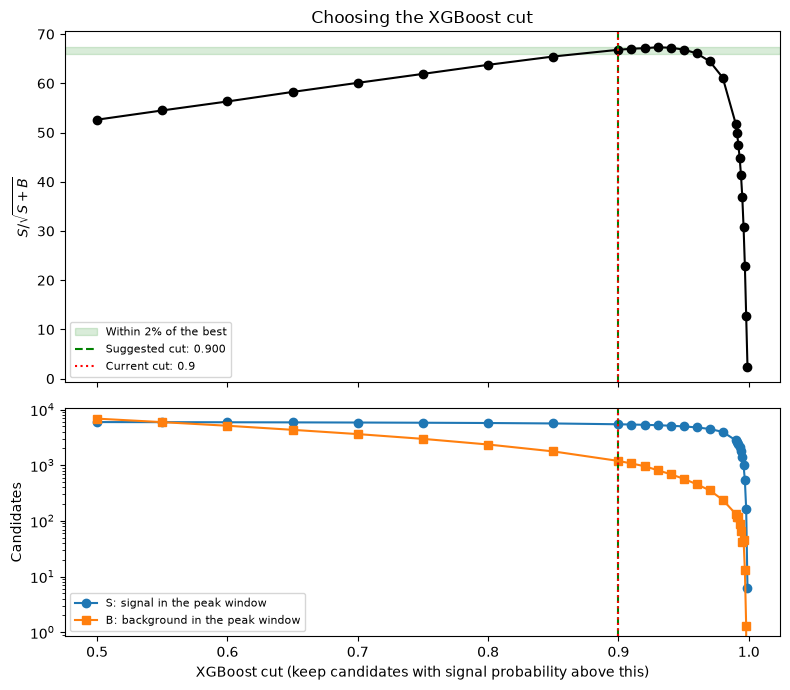

In [51]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(8, 7), gridspec_kw={'height_ratios': [2, 1.3]})

#Top: the score we want as big as possible
ax1.plot(cut_col, fom_col, 'o-', color='black')
ax1.axhspan(0.98 * fom_col.max(), fom_col.max(), color='green', alpha=0.15, label='Within 2% of the best')
ax1.axvline(suggested_cut, color='green', linestyle='--', label=f'Suggested cut: {suggested_cut:.3f}')
ax1.axvline(bdt_cut, color='red', linestyle=':', label=f'Current cut: {bdt_cut}')
ax1.set_ylabel(r'$S/\sqrt{S+B}$')
ax1.set_title('Choosing the XGBoost cut')
ax1.legend(fontsize=8)

#Bottom: what goes into it
ax2.plot(cut_col, S_col, 'o-', color='tab:blue', label='S: signal in the peak window')
ax2.plot(cut_col, B_col, 's-', color='tab:orange', label='B: background in the peak window')
ax2.axvline(suggested_cut, color='green', linestyle='--')
ax2.axvline(bdt_cut, color='red', linestyle=':')
ax2.set_yscale('log')
ax2.set_xlabel('XGBoost cut (keep candidates with signal probability above this)')
ax2.set_ylabel('Candidates')
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Raw asymmetry of the rare decay: one fit to B⁺ and B⁻ at the same time
We use Option B (photon veto, fit from 5180 MeV) as the main result.

We split the candidates by the kaon's charge (`Kaon assumed particle type`: +321 is a K⁺, so a **B⁺**; −321 is a K⁻, so a **B⁻**) and fit **both halves at once**:
- The signal shape is the **same** for B⁺ and B⁻ (same B mass, same detector), so any difference between the two halves comes only from the numbers of events.
- Instead of a separate signal yield for each half, the fit uses the **total** N = N(B⁺) + N(B⁻) and the **raw asymmetry**

  A_raw = (N(B⁻) − N(B⁺)) / (N(B⁻) + N(B⁺)),

  so that N(B⁻) = N(1 + A)/2 and N(B⁺) = N(1 − A)/2. The fit then gives A_raw and its uncertainty directly, with no error propagation needed.
- Each half has its own amount of background, with the same background slope.

"Raw" means it still includes fake asymmetries from how B mesons are produced and detected. Task 7 measures those, and Task 8 removes them.

In [92]:
def fit_charge_asymmetry(values, kaon_type, lower, name, title, fix_shape=True, upper=5700, plot=True, fixed_exponent=None,
                         free_shape=(), separate_slopes=False, shape_values=None):
    #Fit the B mass of B+ and B- candidates at the same time and return the raw asymmetry A and its uncertainty.
    #values:    B masses of the selected candidates
    #kaon_type: 'Kaon assumed particle type' of the same candidates (+321 = B+, -321 = B-)
    #fix_shape: True  = signal width and tails fixed from the Task 1 fit (for small samples)
    #           False = they float, starting from the Task 1 values (for big samples), but are still shared by B+ and B-
    #plot:      False = no plots and no long fit printout (useful when fitting many subsets in a loop)
    #fixed_exponent: if given, the background slope is fixed to this value instead of being fitted
    #           (for very small samples, where there is too little background to measure its slope)
    #free_shape: with fix_shape=True, names of shape parameters to let float anyway, e.g. ('alphaR', 'nR')
    #separate_slopes: True = B+ and B- each get their own background slope (instead of sharing one)
    #shape_values: optional {name: value} to use instead of the Task 1 value for some shape parameters,
    #           e.g. {'alphaR': 1.76, 'nR': 73} (with fix_shape=True they are fixed to these values)
    space = zfit.Space('B invariant mass', (lower, upper))

    limits = {'sigma': (1, 100), 'alphaL': (0.1, 10), 'nL': (0.5, 100), 'alphaR': (0.1, 10), 'nR': (0.5, 100)}
    shape = {}
    for p, par in [('sigma', b_cb_sigma), ('alphaL', b_cb_alphaL), ('nL', b_cb_nL), ('alphaR', b_cb_alphaR), ('nR', b_cb_nR)]:
        start = (shape_values or {}).get(p, result_b_cb.params[par]['value'])
        if fix_shape and p not in free_shape:
            shape[p] = zfit.Parameter(f'{name}_{p}', start, floating=False)
        else:
            shape[p] = zfit.Parameter(f'{name}_{p}', start, *limits[p])
    mean     = zfit.Parameter(f'{name}_mean', b_cb_mu_fit, 5250, 5320)
    if fixed_exponent is None:
        exponent = zfit.Parameter(f'{name}_exponent', -0.003, -0.1, 0.1)   #same background slope for B+ and B-
    else:
        exponent = zfit.Parameter(f'{name}_exponent', fixed_exponent, floating=False)

    values, kaon_type = np.asarray(values), np.asarray(kaon_type)
    in_range = (values >= lower) & (values <= upper)

    #Signal yields written as total N and asymmetry A
    N = zfit.Parameter(f'{name}_N', in_range.sum(), 0, 1e8)
    A = zfit.Parameter(f'{name}_A', 0, -1, 1)
    n_signal = {
        'B+': zfit.ComposedParameter(f'{name}_N_Bplus',  lambda p: p['N'] * (1 - p['A']) / 2, params={'N': N, 'A': A}),
        'B-': zfit.ComposedParameter(f'{name}_N_Bminus', lambda p: p['N'] * (1 + p['A']) / 2, params={'N': N, 'A': A}),
    }

    models, datasets, parts = [], [], []
    for charge, kaon_id, tag in (('B+', 321, 'Bplus'), ('B-', -321, 'Bminus')):
        charge_values = values[in_range & (kaon_type == kaon_id)]
        signal = zfit.pdf.DoubleCB(obs=space, mu=mean, sigma=shape['sigma'],
                                   alphal=shape['alphaL'], nl=shape['nL'], alphar=shape['alphaR'], nr=shape['nR'],
                                   extended=n_signal[charge])
        background_yield = zfit.Parameter(f'{name}_backgroundYield_{tag}', 0.1 * len(charge_values) + 1, 0, 1e8)
        slope = zfit.Parameter(f'{name}_exponent_{tag}', -0.003, -0.1, 0.1) if separate_slopes else exponent
        background = zfit.pdf.Exponential(obs=space, lam=slope, extended=background_yield)
        model = zfit.pdf.SumPDF([signal, background])

        models.append(model)
        datasets.append(zfit.Data.from_numpy(obs=space, array=charge_values))
        parts.append((charge, charge_values, model, signal, background))

    #One likelihood for both datasets: the fit chooses N, A and everything else to describe B+ and B- together
    nll = zfit.loss.ExtendedUnbinnedNLL(model=models, data=datasets)
    result = zfit.minimize.Minuit().minimize(nll)
    result.hesse()
    if plot:
        print(result)
    print(f"Valid: {result.valid}")
    if not result.valid:
        print('WARNING: the fit is not valid, do not trust these numbers.')

    if plot:
        for charge, charge_values, model, signal, background in parts:
            plot_fit(charge_values, model, components={'Signal (double Crystal Ball)': signal, 'Background (exponential)': background},
                     bins=int((upper - lower) / 10), xlabel=r'B candidate mass / MeV/$c^2$', title=f'{title}: {charge}', show_pulls=True)

    a, a_err = result.params[A]['value'], result.params[A]['hesse']['error']
    print(f"N(B+) = {float(n_signal['B+'].value()):.0f}, N(B-) = {float(n_signal['B-'].value()):.0f}")
    print(f'Raw asymmetry A = {a:.4f} +/- {a_err:.4f}')
    return a, a_err, result

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_409, Composed_autoparam_410], <zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_412, Composed_autoparam_413]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(4976, 1)>, <zfit.Data: Data obs=('B invariant mass',) shape=(5020, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 0.00046 │         56133.66 |  7332.125 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                                value  (rounded)        hesse    at limit
--------------------------------  ------------------  -----

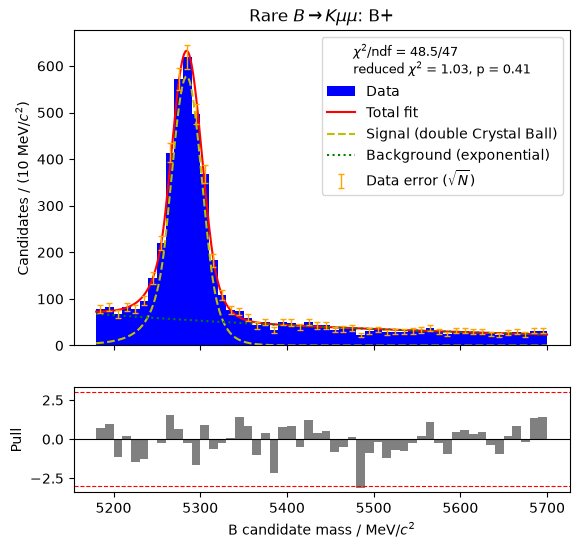

chi2 = 70.4, ndf = 47, reduced chi2 = 1.50, p-value = 0.0151


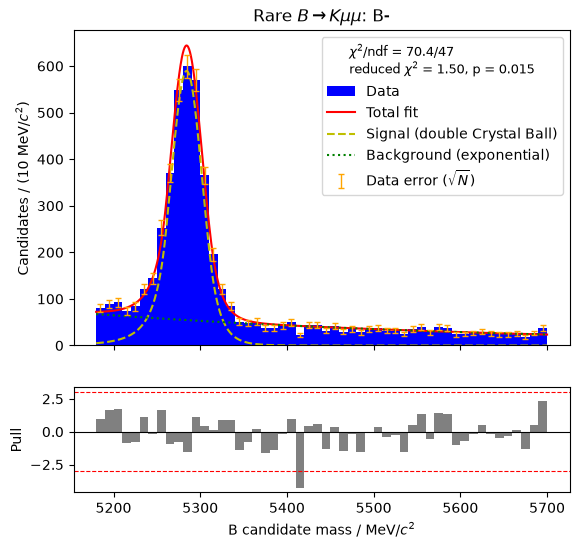

N(B+) = 2796, N(B-) = 2854
Raw asymmetry A = 0.0103 +/- 0.0152


In [93]:
#Rare decay: Option B sample (all cuts + photon veto), fit from chop_B, shape fixed from Task 1
rare_sample = keep & photon_veto
A_raw_rare, A_raw_rare_err, result_asym_rare = fit_charge_asymmetry(
    b_mass[rare_sample], data['Kaon assumed particle type'][rare_sample],
    chop_B, 'asym_rare', r'Rare $B \to K \mu\mu$', fix_shape=True)

## Task 7: CP asymmetry of B⁺ → J/ψ K⁺ (the "fake asymmetry")
Even if nature treated B⁺ and B⁻ exactly the same, we would not count equal numbers of them:
- **Production:** the LHC collides protons (matter), so B⁺ and B⁻ are not made in exactly equal numbers.
- **Detection:** K⁺ and K⁻ interact slightly differently with the detector material, so they are not found equally efficiently.

B⁺ → J/ψ K⁺ (with J/ψ → μ⁺μ⁻) has **exactly the same final particles** as the rare decay (a kaon and two muons) and is selected in the same way, so it suffers the **same** fake asymmetry. Its real CP asymmetry is predicted (and measured) to be essentially zero, so whatever raw asymmetry we measure for it is the fake part.

The J/ψ K sample uses **exactly the same cuts as the rare decay, with two exceptions**:
- the dimuon mass must be **in** the J/ψ peak (instead of vetoed);
- **no photon veto**: every real J/ψ K event has a B mass − dimuon mass gap of about 2184 MeV, so the photon veto would remove all of them.

There are about 300× more J/ψ K than rare decays, so here the signal shape is left free (but still shared by B⁺ and B⁻), and the uncertainty on its asymmetry is tiny. A clearly non-zero result does **not** mean CP violation: it is the production and detection asymmetry.

(Some of these J/ψ K events were used to train XGBoost, so they score slightly too high. That affects B⁺ and B⁻ in the same way, so it does not change the asymmetry.)

B -> J/psi K candidates: 1440503


FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_415, Composed_autoparam_416], <zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_418, Composed_autoparam_419]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(445646, 1)>, <zfit.Data: Data obs=('B invariant mass',) shape=(434022, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  False  │    True     │       True       │ 4.9e-05 │       3940182.85 | -35104.93 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                                 value  (rounded)        hesse    at limit
---------------------------------  ------------------ 

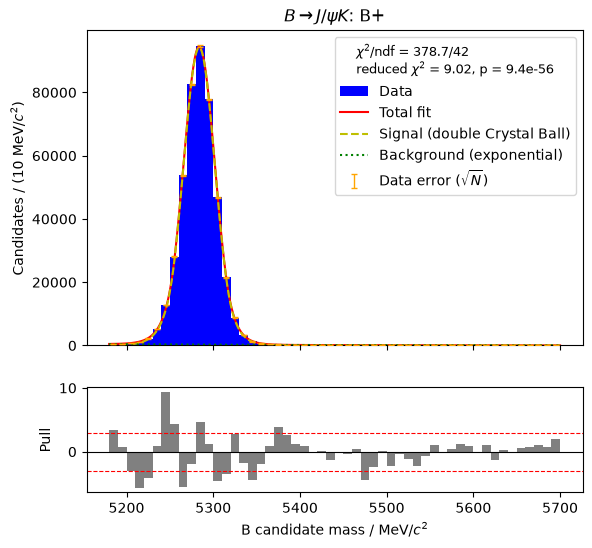

chi2 = 393.0, ndf = 42, reduced chi2 = 9.36, p-value = 1.58e-58


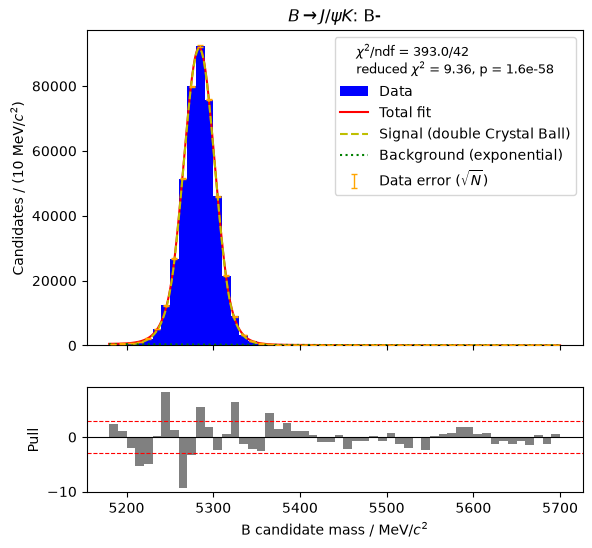

N(B+) = 437374, N(B-) = 425352
Raw asymmetry A = -0.0139 +/- 0.0011


In [94]:
#Same cuts as the rare decay, but the dimuon mass IN the J/psi peak and no photon veto
jpsi_k_sample = in_jpsi_peak & passes_bdt & jpsi_swap_veto & psi2s_swap_veto & d0_veto
print(f'B -> J/psi K candidates: {int(jpsi_k_sample.sum())}')

A_raw_jpsik, A_raw_jpsik_err, result_asym_jpsik = fit_charge_asymmetry(
    b_mass[jpsi_k_sample], data['Kaon assumed particle type'][jpsi_k_sample],
    chop_B, 'asym_jpsik', r'$B \to J/\psi K$', fix_shape=False)

**Answers to Task 7's questions** (all data, XGBoost cut 0.90)

**Is the asymmetry consistent with zero?** No. A_raw(B → J/ψ K) = −0.0139 ± 0.0011, which is about 13σ from zero: about 1.4% fewer B⁻ than B⁺ are counted.

**Do we expect it to be?** It depends on which asymmetry we mean:
- **The true CP asymmetry: yes, about zero.** B⁺ → J/ψ K⁺ happens almost entirely through a single process (b → c c̄ s). A CP asymmetry needs two different processes that interfere, so the Standard Model predicts it to be tiny (well below 1%), and measurements agree it is consistent with zero.
- **The raw asymmetry we count: no.** What we count also contains the fake asymmetries, A_raw = A_CP + A_det + A_prod (see the lab script): B⁺ and B⁻ are not produced in exactly equal numbers in proton–proton collisions (A_prod), and K⁺ and K⁻ are not detected equally well, because K⁻ interact more with the detector material (A_det).

So the −1.4% we measure is the production and detection asymmetry, not CP violation. This is exactly why B → J/ψ K is used to correct the rare decay in Task 8.

## Task 8: CP asymmetry of the rare decay
Both decays have the same fake asymmetry, so we remove it by subtracting:

  **A_CP(B → K μμ) = A_raw(B → K μμ) − A_raw(B → J/ψ K)**

(this uses the fact that the real CP asymmetry of B → J/ψ K is about zero). The two uncertainties are independent, so they are combined in quadrature. The rare decay's uncertainty is much larger, so it dominates.

The Standard Model predicts A_CP(B → K μμ) to be very close to zero. A clearly non-zero value would hint at new physics. For comparison, LHCb's published measurement with 3 fb⁻¹ (2011 + 2012) is A_CP = 0.012 ± 0.017 (stat) ± 0.001 (syst) [JHEP 09 (2014) 177].

The uncertainty here is **statistical only**. Systematic uncertainties (fit shape, fit range, cut choices, how well the two decays' kinematics match) still need to be added.

In [55]:
A_CP_rare     = A_raw_rare - A_raw_jpsik
A_CP_rare_err = np.sqrt(A_raw_rare_err**2 + A_raw_jpsik_err**2)

print(tabulate([
    (r'A_raw(B -> K mu mu)',    A_raw_rare,  A_raw_rare_err),
    (r'A_raw(B -> J/psi K)',    A_raw_jpsik, A_raw_jpsik_err),
    (r'A_CP(B -> K mu mu)',     A_CP_rare,   A_CP_rare_err),
], headers=['Quantity', 'Value', 'Stat. uncertainty'], floatfmt='.4f'))

print(f'\nA_CP(B -> K mu mu) = {A_CP_rare:.3f} +/- {A_CP_rare_err:.3f} (stat), '
      f'which is {abs(A_CP_rare) / A_CP_rare_err:.1f} standard deviations from zero')

Quantity               Value    Stat. uncertainty
-------------------  -------  -------------------
A_raw(B -> K mu mu)   0.0103               0.0152
A_raw(B -> J/psi K)  -0.0139               0.0011
A_CP(B -> K mu mu)    0.0242               0.0152

A_CP(B -> K mu mu) = 0.024 +/- 0.015 (stat), which is 1.6 standard deviations from zero


## Task 8: CP asymmetry in other regions of the dataset

### B → ψ(2S) K: a second control sample
B → ψ(2S) K, with ψ(2S) → μ⁺μ⁻, is like B → J/ψ K: its true CP asymmetry is expected (and measured) to be essentially zero. But it sits at a different dimuon mass, and its kaon has less momentum, because the ψ(2S) is heavier than the J/ψ.

So it tests whether our correction **works for a different sample**: after subtracting A_raw(J/ψ K), A_CP(ψ(2S) K) should be consistent with zero.
- If it is, the fake asymmetry measured with J/ψ K also applies to a decay with different kinematics, which supports the rare-decay result.
- If it isn't, the fake asymmetry depends on kinematics, and the rare decay's correction isn't exact. The difference becomes a systematic uncertainty.

It is selected exactly like J/ψ K (same cuts, dimuon mass in the ψ(2S) peak, **no photon veto**, because every ψ(2S) K event has a B-mass − dimuon-mass gap of about 1594 MeV). None of these events were used to train XGBoost (the training signal was J/ψ K only).

B -> psi(2S) K candidates: 117120
FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_421, Composed_autoparam_422], <zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_424, Composed_autoparam_425]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(39125, 1)>, <zfit.Data: Data obs=('B invariant mass',) shape=(38199, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 0.00039 │        346770.75 |  6091.846 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name                                  value  (rounded)        hesse    at limit
---------------------

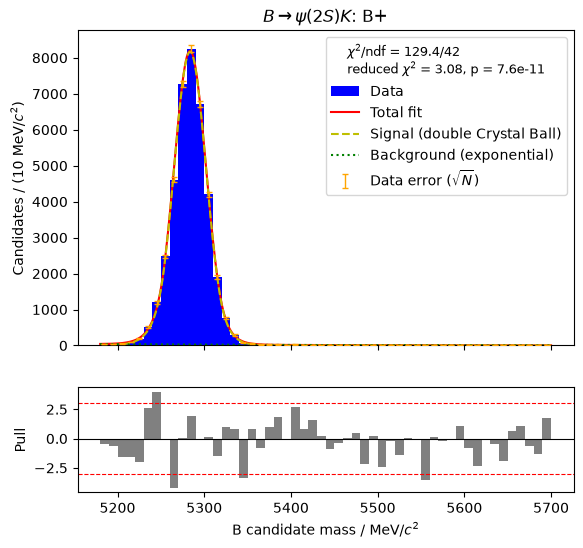

chi2 = 116.3, ndf = 42, reduced chi2 = 2.77, p-value = 6.72e-09


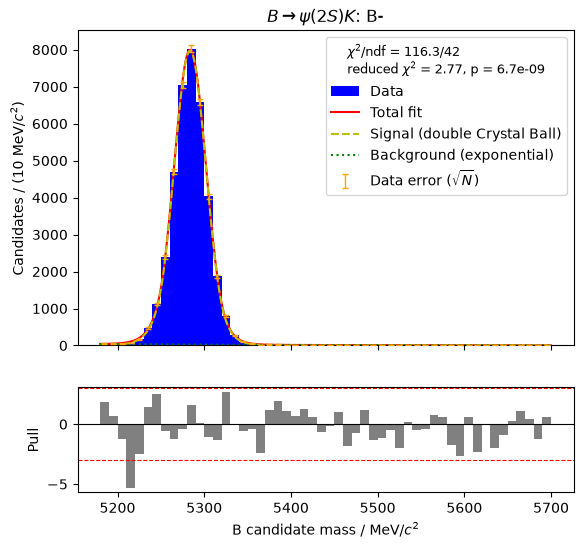

N(B+) = 38339, N(B-) = 37427
Raw asymmetry A = -0.0120 +/- 0.0037

A_CP(B -> psi(2S) K) = 0.0019 +/- 0.0038, which is 0.5 standard deviations from zero


In [95]:
#Same cuts as J/psi K, but with the dimuon mass in the psi(2S) peak (no photon veto)
psi2s_k_sample = in_psi2s_peak & passes_bdt & jpsi_swap_veto & psi2s_swap_veto & d0_veto
print(f'B -> psi(2S) K candidates: {int(psi2s_k_sample.sum())}')

A_raw_psi2sk, A_raw_psi2sk_err, result_asym_psi2sk = fit_charge_asymmetry(
    b_mass[psi2s_k_sample], data['Kaon assumed particle type'][psi2s_k_sample],
    chop_B, 'asym_psi2sk', r'$B \to \psi(2S) K$', fix_shape=False)

#Correct with the J/psi K fake asymmetry, exactly as for the rare decay
A_CP_psi2sk     = A_raw_psi2sk - A_raw_jpsik
A_CP_psi2sk_err = np.sqrt(A_raw_psi2sk_err**2 + A_raw_jpsik_err**2)
print(f'\nA_CP(B -> psi(2S) K) = {A_CP_psi2sk:.4f} +/- {A_CP_psi2sk_err:.4f}, '
      f'which is {abs(A_CP_psi2sk) / A_CP_psi2sk_err:.1f} standard deviations from zero')

### The rare decay in bins of q²
q² is the dimuon mass squared (in GeV²/c⁴). Instead of one A_CP for all rare decays, we measure it separately in five q² ranges:

| Bin | q² range (GeV²) | Dimuon mass (MeV) | Why this bin |
|---|---|---|---|
| 1 | below 1.1 | below 1049 | lowest masses |
| 2 | 1.1 – 6.0 | 1049 – 2449 | the range theorists can predict most precisely (LHCb uses these edges) |
| 3 | 6.0 – 9.0 | 2449 – 2997 | just below the J/ψ veto: photon-leakage events would show up here first |
| 4 | 10.2 – 12.9 | 3197 – 3586 | between the J/ψ and ψ(2S) vetoes |
| 5 | above 14.3 | above 3786 | highest masses, up to the largest possible (B mass − kaon mass) |

The gaps are our J/ψ and ψ(2S) vetoes (±100 MeV around each peak).

Each bin is fitted exactly like the whole rare sample (Option B: photon veto, fit from 5180 MeV, shape fixed from Task 1), and corrected with the J/ψ K raw asymmetry from the **whole** J/ψ K sample:

  A_CP(bin) = A_raw(bin) − A_raw(J/ψ K)

**What to look for:**
- The Standard Model predicts A_CP ≈ 0 in **every** bin.
- The bins should agree **with each other**. We check this with a χ² of the bins around their average. The J/ψ K correction is the same for every bin, so this check uses only the bins' own (raw) uncertainties.
- The error-weighted average of the bins should be close to the A_CP of the whole sample.
- Bins 3 and 4, next to the J/ψ, are where leftover photon events could still sit, and where interference between the rare decay and the J/ψ could genuinely create an asymmetry (that is the "CP near the J/ψ resonance" extension).

In [57]:
#q^2 bins as dimuon-mass edges (MeV). 1.1 and 6.0 GeV^2 are LHCb's edges; the others come from our vetoes
#and from the smallest (two muon masses) and largest (B mass - kaon mass) possible dimuon mass
q2_bins = [
    (r'$q^2$ < 1.1',                     2*M_MUON,            np.sqrt(1.1) * 1000),
    (r'1.1 < $q^2$ < 6.0',               np.sqrt(1.1) * 1000, np.sqrt(6.0) * 1000),
    (r'6.0 < $q^2$ < J/$\psi$ veto',     np.sqrt(6.0) * 1000, M_JPSI - 100),
    (r'between J/$\psi$ and $\psi(2S)$', M_JPSI + 100,        M_PSI2S - 100),
    (r'above $\psi(2S)$',                M_PSI2S + 100,       5279.3 - M_KAON),
]

bin_results = []
for i, (label, lo, hi) in enumerate(q2_bins):
    in_bin = rare_sample & (dimuon_mass > lo) & (dimuon_mass < hi)
    print(f'\n===== Bin {i + 1}: {label}')
    a_raw, a_raw_err, bin_fit = fit_charge_asymmetry(
        b_mass[in_bin], data['Kaon assumed particle type'][in_bin],
        chop_B, f'asym_q2bin{i + 1}', label, fix_shape=True, plot=False)
    n_signal = bin_fit.params[f'asym_q2bin{i + 1}_N']['value']   #fitted number of rare decays (B+ and B-) in this bin
    bin_results.append({'label': label, 'lo': lo, 'hi': hi, 'n': n_signal,
                        'A_raw': a_raw, 'A_raw_err': a_raw_err,
                        'A_CP': a_raw - A_raw_jpsik, 'A_CP_err': np.sqrt(a_raw_err**2 + A_raw_jpsik_err**2)})

#Error-weighted average of the bins. The J/psi K correction is common to all bins, so average the raw asymmetries
#and subtract the correction once
weights      = np.array([1 / r['A_raw_err']**2 for r in bin_results])
A_raw_bins   = np.array([r['A_raw'] for r in bin_results])
avg_raw      = np.sum(weights * A_raw_bins) / np.sum(weights)
avg_cp       = avg_raw - A_raw_jpsik
avg_cp_err   = np.sqrt(1 / np.sum(weights) + A_raw_jpsik_err**2)

#Do the bins agree with each other? chi2 of the bins around their average (only the bins' own uncertainties)
chi2_bins = np.sum(weights * (A_raw_bins - avg_raw)**2)
ndf_bins  = len(bin_results) - 1
p_bins    = chi2_distribution.sf(chi2_bins, ndf_bins)

print()
print(tabulate([(i + 1, r['label'].replace('$', ''), f"{(r['lo'] / 1000)**2:.2f} - {(r['hi'] / 1000)**2:.2f}", f"{r['n']:.0f}",
                 r['A_raw'], r['A_CP'], r['A_CP_err'], abs(r['A_CP']) / r['A_CP_err'])
                for i, r in enumerate(bin_results)],
               headers=['Bin', 'Region', 'q^2 (GeV^2)', 'Signal yield', 'A_raw', 'A_CP', 'Stat. unc.', 'Sigma from 0'],
               floatfmt='.4f'))
print(f'\nWeighted average of the bins: A_CP = {avg_cp:.4f} +/- {avg_cp_err:.4f}  '
      f'(whole sample: {A_CP_rare:.4f} +/- {A_CP_rare_err:.4f})')
print(f'Do the bins agree with each other? chi2 / ndf = {chi2_bins:.1f} / {ndf_bins}, p-value = {p_bins:.3f}')


===== Bin 1: $q^2$ < 1.1
Valid: True
N(B+) = 190, N(B-) = 247
Raw asymmetry A = 0.1314 +/- 0.0543

===== Bin 2: 1.1 < $q^2$ < 6.0
Valid: True
N(B+) = 752, N(B-) = 757
Raw asymmetry A = 0.0033 +/- 0.0303

===== Bin 3: 6.0 < $q^2$ < J/$\psi$ veto
Valid: True
N(B+) = 519, N(B-) = 551
Raw asymmetry A = 0.0307 +/- 0.0354

===== Bin 4: between J/$\psi$ and $\psi(2S)$
Valid: True
N(B+) = 426, N(B-) = 467
Raw asymmetry A = 0.0468 +/- 0.0373

===== Bin 5: above $\psi(2S)$
Valid: True
N(B+) = 910, N(B-) = 833
Raw asymmetry A = -0.0440 +/- 0.0268

  Bin  Region                       q^2 (GeV^2)      Signal yield    A_raw     A_CP    Stat. unc.    Sigma from 0
-----  ---------------------------  -------------  --------------  -------  -------  ------------  --------------
    1  q^2 < 1.1                    0.04 - 1.10               437   0.1314   0.1453        0.0543          2.6777
    2  1.1 < q^2 < 6.0              1.10 - 6.00              1509   0.0033   0.0173        0.0303          0.5698


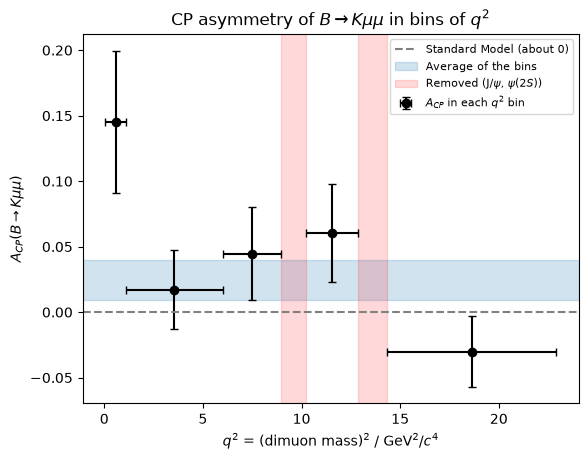

In [58]:
#A_CP against q^2
q2_lo   = np.array([(r['lo'] / 1000)**2 for r in bin_results])
q2_hi   = np.array([(r['hi'] / 1000)**2 for r in bin_results])
a_cp    = np.array([r['A_CP'] for r in bin_results])
a_cp_er = np.array([r['A_CP_err'] for r in bin_results])

plt.errorbar(0.5 * (q2_lo + q2_hi), a_cp, xerr=0.5 * (q2_hi - q2_lo), yerr=a_cp_er,
             fmt='o', color='black', capsize=3, label=r'$A_{CP}$ in each $q^2$ bin')
plt.axhline(0, color='grey', linestyle='--', label='Standard Model (about 0)')
plt.axhspan(avg_cp - avg_cp_err, avg_cp + avg_cp_err, color='tab:blue', alpha=0.2, label='Average of the bins')

#Shade the regions removed by the J/psi and psi(2S) vetoes
for k, (m, name) in enumerate(((M_JPSI, r'J/$\psi$'), (M_PSI2S, r'$\psi(2S)$'))):
    plt.axvspan(((m - 100) / 1000)**2, ((m + 100) / 1000)**2, color='red', alpha=0.15,
                label='Removed (J/$\\psi$, $\\psi(2S)$)' if k == 0 else None)

plt.xlabel(r'$q^2$ = (dimuon mass)$^2$ / GeV$^2$/$c^4$')
plt.ylabel(r'$A_{CP}(B \to K \mu\mu)$')
plt.title(r'CP asymmetry of $B \to K \mu\mu$ in bins of $q^2$')
plt.legend(fontsize=8)
plt.show()

### A_CP in 1 GeV² bins of q²
The same measurement in narrow bins, 1 GeV² wide, to see how A_CP behaves across the whole q² range.

- Bins that lie **completely inside** the J/ψ or ψ(2S) veto (9–10 and 13–14 GeV²) contain no data and are left out. Bins that are **partly** vetoed only use the part outside the veto (the vetoed regions are shaded in red).
- Each bin has only about 1/20 of the rare decays, so the uncertainties are much bigger than in the 5 wide bins. Bins with very few candidates are skipped, and bins whose fit fails are marked.
- There is so little background in each bin that its **slope can't be measured**, so it is fixed to the slope from the fit of the whole rare sample. (When it was left free, bins with no background at all gave a meaningless slope and a wrong uncertainty on A.)
- Often the fit finds **no background at all** in a bin (a background yield of exactly 0). zfit then prints "not valid", because a parameter sits at the edge of its allowed range. That's fine here: zero background is a sensible answer. So for these bins we only require that the fit **converged** and that A is not stuck at its limits.
- With about 20 bins, one or two being more than 2σ from zero is expected purely by chance. What matters is whether the bins **as a whole** are consistent with zero and with each other (the χ² printed below).

In [59]:
#1 GeV^2 bins from 0 to 23 GeV^2 (the largest possible q^2 is (B mass - kaon mass)^2 = 22.9 GeV^2)
fine_edges = np.arange(0, 24, 1.0)
min_candidates = 20          #skip bins with fewer candidates than this in the fit range

#Background slope fixed to the value from the fit of the whole rare sample (too little background per bin to measure it)
rare_exponent = result_asym_rare.params['asym_rare_exponent']['value']

fine_results = []
for i, (q2_lo_bin, q2_hi_bin) in enumerate(zip(fine_edges[:-1], fine_edges[1:])):
    lo, hi = np.sqrt(q2_lo_bin) * 1000, np.sqrt(q2_hi_bin) * 1000   #dimuon-mass edges in MeV
    in_bin = rare_sample & (dimuon_mass > lo) & (dimuon_mass < hi)
    n_in_range = int((in_bin & (b_mass > chop_B) & (b_mass < 5700)).sum())
    if n_in_range < min_candidates:
        print(f'q^2 {q2_lo_bin:.0f}-{q2_hi_bin:.0f}: {n_in_range} candidates, skipped')
        continue

    print(f'\n===== q^2 {q2_lo_bin:.0f}-{q2_hi_bin:.0f} GeV^2 ({n_in_range} candidates in the fit range)')
    a_raw, a_raw_err, bin_fit = fit_charge_asymmetry(
        b_mass[in_bin], data['Kaon assumed particle type'][in_bin],
        chop_B, f'asym_fineq2_{i}', f'q2 {q2_lo_bin:.0f}-{q2_hi_bin:.0f}', fix_shape=True, plot=False,
        fixed_exponent=rare_exponent)

    #A background yield of exactly 0 is fine here, so only require convergence and A away from its limits (-1, +1)
    A_param = [p for p in bin_fit.params if p.name == f'asym_fineq2_{i}_A'][0]
    fit_ok = bin_fit.converged and not A_param.at_limit and np.isfinite(a_raw_err)

    fine_results.append({'lo': q2_lo_bin, 'hi': q2_hi_bin, 'valid': bool(fit_ok),
                         'n': bin_fit.params[f'asym_fineq2_{i}_N']['value'],
                         'A_raw': a_raw, 'A_raw_err': a_raw_err,
                         'A_CP': a_raw - A_raw_jpsik, 'A_CP_err': np.sqrt(a_raw_err**2 + A_raw_jpsik_err**2)})

#Do the (valid) bins agree with zero, and with each other? (bins' own uncertainties only, as for the 5 wide bins)
good = [r for r in fine_results if r['valid']]
w    = np.array([1 / r['A_raw_err']**2 for r in good])
araw = np.array([r['A_raw'] for r in good])
fine_avg_raw = np.sum(w * araw) / np.sum(w)
fine_chi2    = np.sum(w * (araw - fine_avg_raw)**2)
fine_ndf     = len(good) - 1
print()
print(tabulate([(f"{r['lo']:.0f} - {r['hi']:.0f}", f"{r['n']:.0f}", r['A_CP'], r['A_CP_err'],
                 abs(r['A_CP']) / r['A_CP_err'], 'yes' if r['valid'] else 'NO')
                for r in fine_results],
               headers=['q^2 (GeV^2)', 'Signal yield', 'A_CP', 'Stat. unc.', 'Sigma from 0', 'Fit OK'], floatfmt='.3f'))
print(f'\nDo the bins agree with each other? chi2 / ndf = {fine_chi2:.1f} / {fine_ndf}, '
      f'p-value = {chi2_distribution.sf(fine_chi2, fine_ndf):.3f}')
print(f'Bins more than 2 sigma from zero: {sum(abs(r["A_CP"]) / r["A_CP_err"] > 2 for r in good)} of {len(good)} '
      f'(about {0.046 * len(good):.1f} expected by chance)')


===== q^2 0-1 GeV^2 (734 candidates in the fit range)
Valid: True
N(B+) = 164, N(B-) = 219
Raw asymmetry A = 0.1438 +/- 0.0587

===== q^2 1-2 GeV^2 (560 candidates in the fit range)
Valid: True
N(B+) = 146, N(B-) = 156
Raw asymmetry A = 0.0306 +/- 0.0665

===== q^2 2-3 GeV^2 (653 candidates in the fit range)
Valid: True
N(B+) = 163, N(B-) = 169
Raw asymmetry A = 0.0190 +/- 0.0640

===== q^2 3-4 GeV^2 (632 candidates in the fit range)
Valid: True
N(B+) = 162, N(B-) = 155
Raw asymmetry A = -0.0211 +/- 0.0662

===== q^2 4-5 GeV^2 (577 candidates in the fit range)
Valid: True
N(B+) = 168, N(B-) = 149
Raw asymmetry A = -0.0593 +/- 0.0649

===== q^2 5-6 GeV^2 (600 candidates in the fit range)
Valid: True
N(B+) = 149, N(B-) = 163
Raw asymmetry A = 0.0457 +/- 0.0661

===== q^2 6-7 GeV^2 (657 candidates in the fit range)
Valid: True
N(B+) = 170, N(B-) = 176
Raw asymmetry A = 0.0163 +/- 0.0623

===== q^2 7-8 GeV^2 (646 candidates in the fit range)
Valid: True
N(B+) = 170, N(B-) = 168
Raw asymme

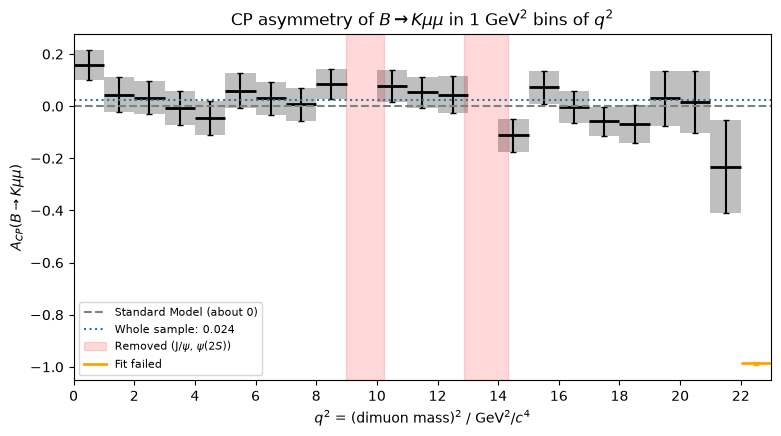

In [60]:
#Histogram-style plot: one flat bar per 1 GeV^2 bin, with its uncertainty
fig, ax = plt.subplots(figsize=(9, 4.5))
for r in fine_results:
    colour = 'black' if r['valid'] else 'orange'
    ax.hlines(r['A_CP'], r['lo'], r['hi'], color=colour, linewidth=2)                 #the bin's value across its width
    ax.add_patch(plt.Rectangle((r['lo'], r['A_CP'] - r['A_CP_err']), r['hi'] - r['lo'], 2 * r['A_CP_err'],
                               color=colour, alpha=0.25, linewidth=0))                 #its uncertainty band
    ax.errorbar(0.5 * (r['lo'] + r['hi']), r['A_CP'], yerr=r['A_CP_err'], fmt='none', ecolor=colour, capsize=2)

ax.axhline(0, color='grey', linestyle='--', label='Standard Model (about 0)')
ax.axhline(A_CP_rare, color='tab:blue', linestyle=':', label=f'Whole sample: {A_CP_rare:.3f}')
for k, m in enumerate((M_JPSI, M_PSI2S)):
    ax.axvspan(((m - 100) / 1000)**2, ((m + 100) / 1000)**2, color='red', alpha=0.15,
               label='Removed (J/$\\psi$, $\\psi(2S)$)' if k == 0 else None)
if not all(r['valid'] for r in fine_results):
    ax.plot([], [], color='orange', linewidth=2, label='Fit failed')

ax.set_xlim(0, 23)
ax.set_xticks(np.arange(0, 24, 2))
ax.set_xlabel(r'$q^2$ = (dimuon mass)$^2$ / GeV$^2$/$c^4$')
ax.set_ylabel(r'$A_{CP}(B \to K \mu\mu)$')
ax.set_title(r'CP asymmetry of $B \to K \mu\mu$ in 1 GeV$^2$ bins of $q^2$')
ax.legend(fontsize=8)
plt.show()

## Cross-checks: does the J/ψ K correction really work?
We remove the fake (production + detection) asymmetry by subtracting A_raw(J/ψ K). To test whether that is fair, we split the data into pieces where the fake asymmetry should be **different**. If the correction works, A_CP of the rare decay should come out the **same** in every piece.

**Golden rule:** in every piece, the rare decay is corrected with J/ψ K from the **same** piece:

  A_CP(piece) = A_raw(rare, piece) − A_raw(J/ψ K, piece)

**Do two numbers agree?** Work out (A₁ − A₂) / √(σ₁² + σ₂²). Below about 2 means they agree; above about 3 means something isn't cancelling, and the difference goes into the systematic uncertainty.

The three checks:
1. **Magnet up vs magnet down.** Flipping the magnet swaps which side of the detector K⁺ and K⁻ travel through, so any left/right difference in the detector moves from K⁺ to K⁻. A_raw(J/ψ K) may differ between the two settings (that difference measures the left/right effect); A_CP should not.
2. **2011 vs 2012.** Different collision energies (7 and 8 TeV) and detector conditions, so the production asymmetry (and maybe the detection asymmetry) can differ. A_CP should not.
3. **Do the two decays look alike?** The detection asymmetry depends on the kaon's momentum (e.g. slow K⁻ are absorbed by the detector material more often than slow K⁺). The subtraction is fair if the kaons in J/ψ K and in the rare decay have similar momenta, **or** if A_raw(J/ψ K) doesn't depend on the kaon momentum. Either one is enough.

In [61]:
kaon_type = data['Kaon assumed particle type']

def acp_in_subset(subset, name, label):
    #A_CP of the rare decay in a piece of the data, corrected with J/psi K from the SAME piece.
    #subset: True/False for every candidate in data, e.g. data['Magnet polarity'] == 1
    print(f'\n===== {label}')
    a_j, e_j, _ = fit_charge_asymmetry(b_mass[jpsi_k_sample & subset], kaon_type[jpsi_k_sample & subset],
                                       chop_B, f'{name}_jpsik', label, fix_shape=False, plot=False)
    a_r, e_r, _ = fit_charge_asymmetry(b_mass[rare_sample & subset], kaon_type[rare_sample & subset],
                                       chop_B, f'{name}_rare', label, fix_shape=True, plot=False)
    return {'label': label, 'A_raw_jpsik': a_j, 'A_raw_jpsik_err': e_j, 'A_raw_rare': a_r, 'A_raw_rare_err': e_r,
            'A_CP': a_r - a_j, 'A_CP_err': np.sqrt(e_r**2 + e_j**2)}

def compare(r1, r2, key):
    #Difference between two independent pieces, and how many standard deviations it is
    diff = r1[key] - r2[key]
    err  = np.sqrt(r1[key + '_err']**2 + r2[key + '_err']**2)
    return diff, err, abs(diff) / err

def print_pieces(results):
    print()
    print(tabulate([(r['label'], f"{r['A_raw_jpsik']:.4f} +/- {r['A_raw_jpsik_err']:.4f}",
                     f"{r['A_raw_rare']:.4f} +/- {r['A_raw_rare_err']:.4f}", f"{r['A_CP']:.4f} +/- {r['A_CP_err']:.4f}")
                    for r in results],
                   headers=['Piece', 'A_raw(J/psi K)', 'A_raw(rare)', 'A_CP(rare)']))

def verdict(n_sigma):
    return 'agree' if n_sigma < 2 else ('borderline' if n_sigma < 3 else 'DISAGREE')

### 1. Magnet up vs magnet down
`Magnet polarity` is +1 for up and −1 for down. Both years contain both settings.

In [62]:
magnet_results = [acp_in_subset(data['Magnet polarity'] == 1,  'magup',   'Magnet up'),
                  acp_in_subset(data['Magnet polarity'] == -1, 'magdown', 'Magnet down')]
print_pieces(magnet_results)

d, e, n = compare(*magnet_results, 'A_raw_jpsik')
print(f'\nA_raw(J/psi K), up - down = {d:.4f} +/- {e:.4f} ({n:.1f} sigma): this is the size of the left/right detector effect')
d, e, n = compare(*magnet_results, 'A_CP')
print(f'A_CP(rare),     up - down = {d:.4f} +/- {e:.4f} ({n:.1f} sigma): {verdict(n)}')

#Average of the two settings: any left/right effect left over after the correction cancels in this average
A_CP_magnet_avg     = 0.5 * (magnet_results[0]['A_CP'] + magnet_results[1]['A_CP'])
A_CP_magnet_avg_err = 0.5 * np.sqrt(magnet_results[0]['A_CP_err']**2 + magnet_results[1]['A_CP_err']**2)
print(f'\nAverage of the two magnet settings: A_CP = {A_CP_magnet_avg:.4f} +/- {A_CP_magnet_avg_err:.4f} '
      f'(whole sample: {A_CP_rare:.4f} +/- {A_CP_rare_err:.4f})')


===== Magnet up
Valid: False
N(B+) = 210388, N(B-) = 204811
Raw asymmetry A = -0.0134 +/- 0.0016
Valid: True
N(B+) = 1374, N(B-) = 1393
Raw asymmetry A = 0.0066 +/- 0.0217

===== Magnet down
Valid: True
N(B+) = 227017, N(B-) = 220574
Raw asymmetry A = -0.0144 +/- 0.0015
Valid: True
N(B+) = 1422, N(B-) = 1461
Raw asymmetry A = 0.0137 +/- 0.0213

Piece        A_raw(J/psi K)      A_raw(rare)        A_CP(rare)
-----------  ------------------  -----------------  -----------------
Magnet up    -0.0134 +/- 0.0016  0.0066 +/- 0.0217  0.0201 +/- 0.0217
Magnet down  -0.0144 +/- 0.0015  0.0137 +/- 0.0213  0.0281 +/- 0.0214

A_raw(J/psi K), up - down = 0.0010 +/- 0.0022 (0.4 sigma): this is the size of the left/right detector effect
A_CP(rare),     up - down = -0.0080 +/- 0.0305 (0.3 sigma): agree

Average of the two magnet settings: A_CP = 0.0241 +/- 0.0152 (whole sample: 0.0242 +/- 0.0152)


### 2. 2011 vs 2012

In [63]:
year_results = [acp_in_subset(data['Year'] == 2011, 'y2011', '2011 (7 TeV)'),
                acp_in_subset(data['Year'] == 2012, 'y2012', '2012 (8 TeV)')]
print_pieces(year_results)

d, e, n = compare(*year_results, 'A_raw_jpsik')
print(f'\nA_raw(J/psi K), 2011 - 2012 = {d:.4f} +/- {e:.4f} ({n:.1f} sigma): how much the fake asymmetry changed between the years')
d, e, n = compare(*year_results, 'A_CP')
print(f'A_CP(rare),     2011 - 2012 = {d:.4f} +/- {e:.4f} ({n:.1f} sigma): {verdict(n)}')


===== 2011 (7 TeV)
Valid: True
N(B+) = 134873, N(B-) = 130957
Raw asymmetry A = -0.0147 +/- 0.0020
Valid: True
N(B+) = 887, N(B-) = 872
Raw asymmetry A = -0.0085 +/- 0.0271

===== 2012 (8 TeV)
Valid: False
N(B+) = 302506, N(B-) = 294397
Raw asymmetry A = -0.0136 +/- 0.0013
Valid: True
N(B+) = 1911, N(B-) = 1983
Raw asymmetry A = 0.0186 +/- 0.0183

Piece         A_raw(J/psi K)      A_raw(rare)         A_CP(rare)
------------  ------------------  ------------------  -----------------
2011 (7 TeV)  -0.0147 +/- 0.0020  -0.0085 +/- 0.0271  0.0063 +/- 0.0272
2012 (8 TeV)  -0.0136 +/- 0.0013  0.0186 +/- 0.0183   0.0322 +/- 0.0184

A_raw(J/psi K), 2011 - 2012 = -0.0011 +/- 0.0024 (0.5 sigma): how much the fake asymmetry changed between the years
A_CP(rare),     2011 - 2012 = -0.0259 +/- 0.0328 (0.8 sigma): agree


### 3. Do the kaons in J/ψ K and in the rare decay look alike?
We compare candidates in the B-mass peak window (±3σ) of both samples. The background there is very small (about 2% for the rare decay and well below 1% for J/ψ K), so we simply use all candidates in the window.

Pseudorapidity η describes the direction of a particle: η = ½ ln((p + p_z) / (p − p_z)), where p_z is the momentum along the beam. LHCb sees particles with η between about 2 and 5.

**a) Compare the distributions.** If the two decays' kaons (and B mesons) have similar momenta and directions, the AUC between them is close to 0.5.

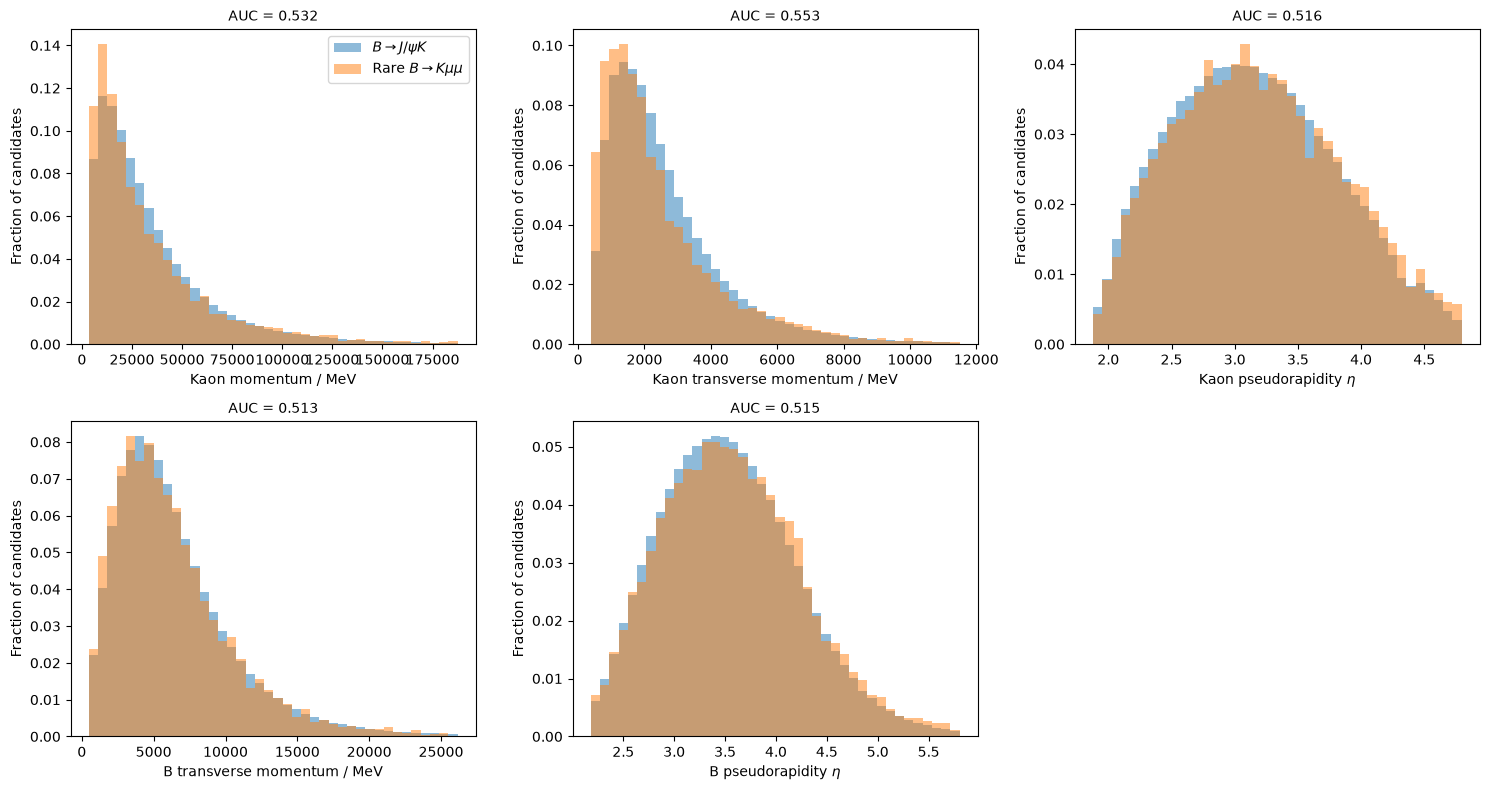

Variable                          AUC J/psi K vs rare (0.5 = identical)
------------------------------  ---------------------------------------
Kaon momentum / MeV                                               0.532
Kaon transverse momentum / MeV                                    0.553
Kaon pseudorapidity $\eta$                                        0.516
B transverse momentum / MeV                                       0.513
B pseudorapidity $\eta$                                           0.515


In [64]:
def pseudorapidity(p, pz):
    return 0.5 * np.log((p + pz) / (p - pz))

jpsi_window = jpsi_k_sample & in_peak     #B -> J/psi K candidates in the B-mass peak window
rare_window = rare_sample & in_peak       #rare-decay candidates in the B-mass peak window

kinematics = {
    'Kaon momentum / MeV':            data['Kaon magnitude of momentum'],
    'Kaon transverse momentum / MeV': data['Kaon magnitude of momentum transverse to beam'],
    r'Kaon pseudorapidity $\eta$':    pseudorapidity(data['Kaon magnitude of momentum'], data['Kaon 4-momentum z component']),
    'B transverse momentum / MeV':    data['B magnitude of momentum transverse to beam'],
    r'B pseudorapidity $\eta$':       pseudorapidity(data['B magnitude of momentum'], data['B 4-momentum z component']),
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
kinematics_auc = {}
for ax, (label, values) in zip(axes.flat, kinematics.items()):
    jpsi_values, rare_values = values[jpsi_window].to_numpy(), values[rare_window].to_numpy()
    auc = roc_auc_score(np.r_[np.ones(len(jpsi_values)), np.zeros(len(rare_values))], np.r_[jpsi_values, rare_values])
    kinematics_auc[label] = max(auc, 1 - auc)

    lo, hi = np.percentile(np.r_[jpsi_values, rare_values], [0.5, 99.5])
    edges = np.linspace(lo, hi, 41)
    ax.hist(jpsi_values, bins=edges, weights=np.full(len(jpsi_values), 1 / len(jpsi_values)), alpha=0.5, label=r'$B \to J/\psi K$')
    ax.hist(rare_values, bins=edges, weights=np.full(len(rare_values), 1 / len(rare_values)), alpha=0.5, label=r'Rare $B \to K \mu\mu$')
    ax.set_xlabel(label)
    ax.set_ylabel('Fraction of candidates')
    ax.set_title(f'AUC = {kinematics_auc[label]:.3f}', fontsize=10)
axes.flat[0].legend()
axes.flat[-1].set_visible(False)
fig.tight_layout()
plt.show()

print(tabulate(kinematics_auc.items(), headers=['Variable', 'AUC J/psi K vs rare (0.5 = identical)'], floatfmt='.3f'))

**b) Does A_raw(J/ψ K) depend on the kaon momentum?** We split the J/ψ K candidates into 10 bins of kaon momentum, each with the same number of candidates, and count the asymmetry in each: A = (N(B⁻) − N(B⁺)) / (N(B⁻) + N(B⁺)), with uncertainty √((1 − A²)/N). (Counting is fine here, because there is almost no background in the J/ψ K peak window.)

If A_raw(J/ψ K) is the same in every bin (a flat line, χ² test below), the kaon momentum doesn't matter, and the subtraction is fair even if the two decays' kaon momenta differ. The grey histogram shows where the rare decay's kaons are.

A_raw(J/psi K) averaged over the bins: -0.0138. Is it flat? chi2 / ndf = 8.3 / 9, p-value = 0.501


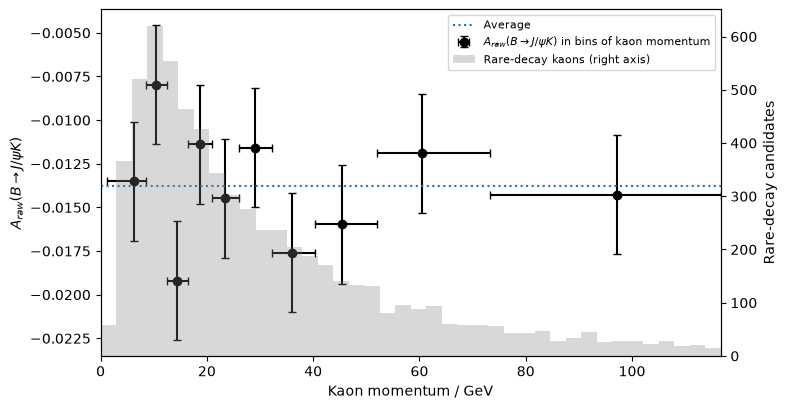

In [65]:
def counted_asymmetry(mask):
    #A = (N(B-) - N(B+)) / (N(B-) + N(B+)) by counting, with its statistical uncertainty sqrt((1 - A^2) / N)
    q = np.where(kaon_type[mask].to_numpy() == -321, 1.0, -1.0)   #+1 for a B-, -1 for a B+
    a = np.mean(q)
    return a, np.sqrt((1 - a**2) / len(q))

kaon_p = data['Kaon magnitude of momentum']
p_edges = np.quantile(kaon_p[jpsi_window], np.linspace(0, 1, 11))   #10 bins with equal numbers of J/psi K candidates

p_bins = []
for lo, hi in zip(p_edges[:-1], p_edges[1:]):
    in_bin = jpsi_window & (kaon_p >= lo) & (kaon_p <= hi)
    a, a_err = counted_asymmetry(in_bin)
    p_bins.append((lo, hi, np.median(kaon_p[in_bin]), a, a_err))
p_lo, p_hi, p_mid, a_p, a_p_err = (np.array(x) for x in zip(*p_bins))

#Is it flat? chi2 of the bins around their average
w = 1 / a_p_err**2
a_p_avg = np.sum(w * a_p) / np.sum(w)
chi2_p, ndf_p = np.sum(w * (a_p - a_p_avg)**2), len(a_p) - 1
print(f'A_raw(J/psi K) averaged over the bins: {a_p_avg:.4f}. Is it flat? chi2 / ndf = {chi2_p:.1f} / {ndf_p}, '
      f'p-value = {chi2_distribution.sf(chi2_p, ndf_p):.3f}')

#Each point sits at the median kaon momentum of its bin; the horizontal bar shows the bin's range.
#The last bin has a very long tail, so the plot stops at 100 GeV (or a bit beyond the last point, if that is higher)
p_max = max(100e3, 1.2 * p_mid.max())
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(p_mid / 1000, a_p, xerr=[(p_mid - p_lo) / 1000, (np.minimum(p_hi, p_max) - p_mid) / 1000], yerr=a_p_err,
            fmt='o', color='black', capsize=3, label=r'$A_{raw}(B \to J/\psi K)$ in bins of kaon momentum')
ax.axhline(a_p_avg, color='tab:blue', linestyle=':', label='Average')
ax.set_xlabel('Kaon momentum / GeV')
ax.set_ylabel(r'$A_{raw}(B \to J/\psi K)$')
ax.set_xlim(0, p_max / 1000)

#Where the rare decay's kaons are, for comparison
ax2 = ax.twinx()
ax2.hist(kaon_p[rare_window] / 1000, bins=np.linspace(0, p_max, 41) / 1000, color='grey', alpha=0.3,
         label='Rare-decay kaons (right axis)')
ax2.set_ylabel('Rare-decay candidates')
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, fontsize=8, loc='upper right')
plt.show()

### Summary of the cross-checks
All the values of A_CP(rare) from the different pieces, next to the whole-sample result. If the correction works, they should all agree with it.

A_CP(B -> K mu mu) from        Value
-----------------------------  -----------------
Whole sample                   0.0242 +/- 0.0152
Magnet up                      0.0201 +/- 0.0217
Magnet down                    0.0281 +/- 0.0214
2011 (7 TeV)                   0.0063 +/- 0.0272
2012 (8 TeV)                   0.0322 +/- 0.0184
Average of magnet up and down  0.0241 +/- 0.0152

Control sample B -> psi(2S) K (should be 0): A_CP = 0.0019 +/- 0.0038
Magnet up vs down: agree, 2011 vs 2012: agree


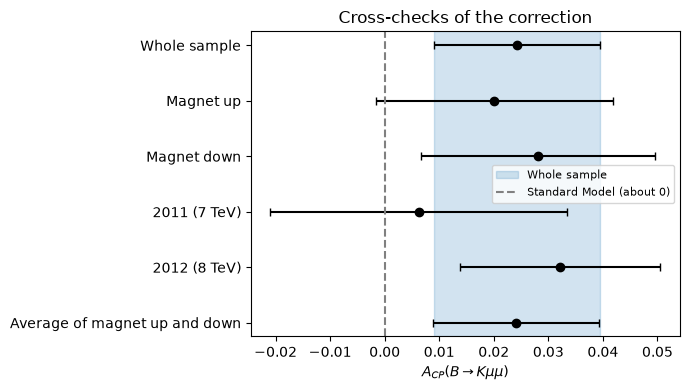

In [66]:
summary_rows = [('Whole sample', A_CP_rare, A_CP_rare_err)]
summary_rows += [(r['label'], r['A_CP'], r['A_CP_err']) for r in magnet_results + year_results]
summary_rows += [('Average of magnet up and down', A_CP_magnet_avg, A_CP_magnet_avg_err)]

print(tabulate([(label, f'{value:.4f} +/- {err:.4f}') for label, value, err in summary_rows],
               headers=['A_CP(B -> K mu mu) from', 'Value']))
print(f'\nControl sample B -> psi(2S) K (should be 0): A_CP = {A_CP_psi2sk:.4f} +/- {A_CP_psi2sk_err:.4f}')
print(f'Magnet up vs down: {verdict(compare(*magnet_results, "A_CP")[2])}, 2011 vs 2012: {verdict(compare(*year_results, "A_CP")[2])}')

#Plot: every version of A_CP, with the whole-sample result as a band
fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(summary_rows))[::-1]
ax.errorbar([v for _, v, _ in summary_rows], y, xerr=[e for _, _, e in summary_rows], fmt='o', color='black', capsize=3)
ax.axvspan(A_CP_rare - A_CP_rare_err, A_CP_rare + A_CP_rare_err, color='tab:blue', alpha=0.2, label='Whole sample')
ax.axvline(0, color='grey', linestyle='--', label='Standard Model (about 0)')
ax.set_yticks(y)
ax.set_yticklabels([label for label, _, _ in summary_rows])
ax.set_xlabel(r'$A_{CP}(B \to K \mu\mu)$')
ax.set_title('Cross-checks of the correction')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Duplicate candidates: more than one candidate from the same collision
Each row of the data is a **candidate**: one combination of a kaon and two muons. Sometimes one collision (an "event") gives **two or more** candidates, e.g. the same two muons paired with two different kaon tracks. At most one of them can be the real B decay, so keeping all of them can count one B twice, and makes the uncertainties look slightly too small.

**What we do:** in the final samples (after every cut, inside the fit range), keep **one candidate per event, chosen at random**. Choosing at random is the standard method; picking "the best" one (e.g. the highest XGBoost score) can bias the result. Then we redo A_CP and see how much it moves.

An event is identified by **Year + Magnet polarity + Event ID** together, because the same Event ID number appears in more than one data file.

For J/ψ K, where duplicates are extremely rare, the change in A_raw is worked out by counting in the B-mass peak window instead of refitting (the background there is tiny, and this is much faster).

In [67]:
event_key = ['Year', 'Magnet polarity', 'Event ID']   #Event ID on its own repeats across the data files

def one_candidate_per_event(selection, seed=42):
    #Of the candidates in `selection`, keep one per collision (event), picked at random
    keys = data.loc[selection, event_key]
    kept = keys.sample(frac=1, random_state=seed).drop_duplicates().index   #shuffle, then keep the first candidate of each event
    return pandas.Series(data.index.isin(kept), index=data.index)

fit_range = (b_mass > chop_B) & (b_mass < 5700)
for label, selection in (('Rare decay', rare_sample & fit_range), ('B -> J/psi K', jpsi_k_sample & fit_range)):
    per_event = data.loc[selection, event_key].groupby(event_key).size()
    n_extra = int(per_event.sum() - len(per_event))
    print(f'{label}: {int(per_event.sum())} candidates in {len(per_event)} events; {int((per_event > 1).sum())} events have '
          f'more than one candidate. Keeping one per event removes {n_extra} candidates ({n_extra / per_event.sum():.2%}).')

rare_single  = one_candidate_per_event(rare_sample & fit_range)
jpsik_single = one_candidate_per_event(jpsi_k_sample & fit_range)

#Rare decay: refit with one candidate per event
A_raw_rare_single, A_raw_rare_single_err, _ = fit_charge_asymmetry(
    b_mass[rare_single], kaon_type[rare_single], chop_B, 'single_rare', 'Rare decay, one candidate per event',
    fix_shape=True, plot=False)

#J/psi K: change in A_raw from removing duplicates, by counting in the peak window
jpsik_shift_single = counted_asymmetry(jpsik_single & in_peak)[0] - counted_asymmetry(jpsi_k_sample & in_peak)[0]

A_CP_single     = A_raw_rare_single - (A_raw_jpsik + jpsik_shift_single)
A_CP_single_err = np.sqrt(A_raw_rare_single_err**2 + A_raw_jpsik_err**2)
print(f'\nA_CP with one candidate per event: {A_CP_single:.4f} +/- {A_CP_single_err:.4f} '
      f'(nominal: {A_CP_rare:.4f} +/- {A_CP_rare_err:.4f}; change {A_CP_single - A_CP_rare:+.4f})')

Rare decay: 9996 candidates in 9964 events; 32 events have more than one candidate. Keeping one per event removes 32 candidates (0.32%).
B -> J/psi K: 879668 candidates in 879526 events; 141 events have more than one candidate. Keeping one per event removes 142 candidates (0.02%).
Valid: True
N(B+) = 2794, N(B-) = 2854
Raw asymmetry A = 0.0106 +/- 0.0152

A_CP with one candidate per event: 0.0245 +/- 0.0152 (nominal: 0.0242 +/- 0.0152; change +0.0003)


## Checking for misidentified B⁺ → K⁺π⁺π⁻ (including B⁺ → K⁺ρ⁰)
**The worry.** The lowest q² bin (q² < 1.1 GeV²) has a larger A_CP than the others. One possible cause: B⁺ → K⁺ρ⁰, with ρ⁰ → π⁺π⁻, where **both pions are mistaken for muons**. That would look exactly like K⁺μ⁺μ⁻, with a fake "dimuon" mass around the ρ⁰ mass (775 MeV, inside the lowest bin). B⁺ → K⁺ρ⁰ has a large CP asymmetry of its own (about +0.4), so even a few such events could pull that bin upwards. More generally, any B⁺ → K⁺π⁺π⁻ decay with two misidentified pions could sneak in.

**How big could it be? (a rough estimate from known decay rates; check the numbers in the PDG)**
- B⁺ → K⁺π⁺π⁻ happens about 5 × 10⁻⁵ of the time, about **110×** more often than B⁺ → K⁺μ⁺μ⁻ (4.5 × 10⁻⁷). Of that, B⁺ → K⁺ρ⁰ is about 3.7 × 10⁻⁶ (about 8× the rare decay).
- A pion is mistaken for a muon about **1–2%** of the time (lab script), so **both** pions: about (1–2%)² = 10⁻⁴ to 4 × 10⁻⁴.
- So about 110 × (1–4) × 10⁻⁴ ≈ **1–4% of our rare-decay sample** could be misidentified K⁺π⁺π⁻, and only about 8 × (1–4) × 10⁻⁴ ≈ **0.1–0.3%** could be K⁺ρ⁰ (a few to about 20 events, mostly in the lowest q² bin). This is only a rough estimate, and probably on the high side: misidentified pions also have to pass our XGBoost cut and look like a good B decay.
- Effect on A_CP: (fraction of contamination) × (its asymmetry). K⁺π⁺π⁻ overall has a small CP asymmetry (about +0.03), so 4% × 0.03 ≈ 0.001 on the whole sample. K⁺ρ⁰ could shift the lowest bin by up to about 20/440 × 0.4 ≈ 0.02, much less than that bin's 0.145 − 0 difference.

**Checks in the data:**
1. **Can we spot them by mass?** Recompute the B mass giving both "muons" the pion mass. Real K⁺π⁺π⁻ decays would peak at the B mass. But because muons and pions have similar masses and these tracks have tens of GeV of momentum, **real rare decays also stay at the B mass** (we check this with the simulation). So this can't separate them, and a "K⁺π⁺π⁻ veto" would throw away most of our signal.
2. **Is there a ρ⁰ bump?** Compare the "dimuon" mass (with pion masses) of the low-q² candidates with simulated rare decays. A K⁺ρ⁰ component would show up as an extra bump around 775 MeV.
3. **Particle ID.** The only real handle: real muons score high on the muon-ID score, pions lower. We tighten a cut on the **smaller of the two muons' muon-ID scores** and watch A_CP. If misidentified pions were pulling A_CP, it would move as the cut tightens (by more than the random change expected from removing events).

Simulated rare decays (q^2 < 1.1) with the pion mass given to both muons: 79% are still within 40 MeV of the B mass


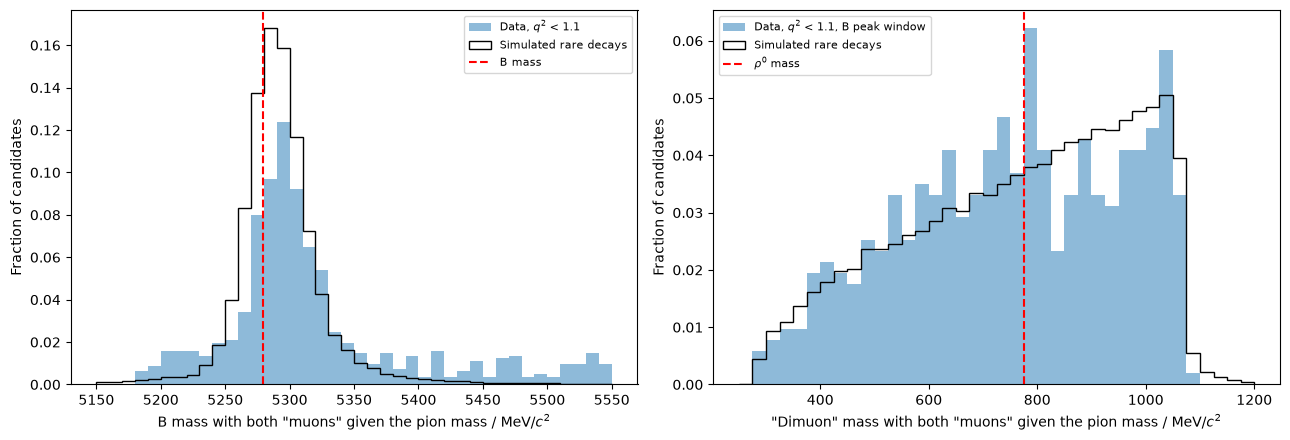

In [68]:
def three_body_mass(df, kaon_mass, muon_mass):
    #B mass recomputed with the kaon given kaon_mass and both "muons" given muon_mass
    energy = (track_energy(df, 'Kaon', kaon_mass) + track_energy(df, 'Same-sign muon', muon_mass)
              + track_energy(df, 'Opposite-sign muon', muon_mass))
    p_sq = sum((df[f'Kaon 4-momentum {c} component'] + df[f'Same-sign muon 4-momentum {c} component']
                + df[f'Opposite-sign muon 4-momentum {c} component'])**2 for c in 'xyz')
    return np.sqrt(energy**2 - p_sq)

low_q2   = dimuon_mass < np.sqrt(1.1) * 1000
rare_low = rare_sample & fit_range & low_q2
sim_low  = sim_kmumu['dimuon-system invariant mass'] < np.sqrt(1.1) * 1000

kpipi_mass     = three_body_mass(data, M_KAON, M_PION)
sim_kpipi_mass = three_body_mass(sim_kmumu[sim_low], M_KAON, M_PION)
print(f'Simulated rare decays (q^2 < 1.1) with the pion mass given to both muons: '
      f'{np.mean(abs(sim_kpipi_mass - 5279.3) < 40):.0%} are still within 40 MeV of the B mass')

pipi_mass     = two_body_mass(data, 'Same-sign muon', 'Opposite-sign muon', M_PION, M_PION)
sim_pipi_mass = two_body_mass(sim_kmumu[sim_low], 'Same-sign muon', 'Opposite-sign muon', M_PION, M_PION)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
#1) B mass with pion masses: data vs simulated rare decays
edges = np.linspace(5150, 5550, 41)
d1, s1 = kpipi_mass[rare_low], sim_kpipi_mass
ax1.hist(d1, bins=edges, weights=np.full(len(d1), 1 / len(d1)), alpha=0.5, label=r'Data, $q^2$ < 1.1')
ax1.hist(s1, bins=edges, weights=np.full(len(s1), 1 / len(s1)), histtype='step', color='black', label='Simulated rare decays')
ax1.axvline(5279.3, color='red', linestyle='--', label='B mass')
ax1.set_xlabel(r'B mass with both "muons" given the pion mass / MeV/$c^2$')
ax1.set_ylabel('Fraction of candidates')
ax1.legend(fontsize=8)
#2) "dimuon" mass with pion masses, candidates in the B peak window: a K rho component would add a bump near 775 MeV
edges = np.linspace(250, 1200, 39)
d2, s2 = pipi_mass[rare_low & in_peak], sim_pipi_mass
ax2.hist(d2, bins=edges, weights=np.full(len(d2), 1 / len(d2)), alpha=0.5, label=r'Data, $q^2$ < 1.1, B peak window')
ax2.hist(s2, bins=edges, weights=np.full(len(s2), 1 / len(s2)), histtype='step', color='black', label='Simulated rare decays')
ax2.axvline(775, color='red', linestyle='--', label=r'$\rho^0$ mass')
ax2.set_xlabel(r'"Dimuon" mass with both "muons" given the pion mass / MeV/$c^2$')
ax2.set_ylabel('Fraction of candidates')
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()


===== muon-ID score > 0.0
Valid: True
N(B+) = 2796, N(B-) = 2854
Raw asymmetry A = 0.0103 +/- 0.0152
Valid: True
N(B+) = 186, N(B-) = 242
Raw asymmetry A = 0.1318 +/- 0.0554

===== muon-ID score > 0.2
Valid: True
N(B+) = 2682, N(B-) = 2747
Raw asymmetry A = 0.0120 +/- 0.0151
Valid: True
N(B+) = 177, N(B-) = 227
Raw asymmetry A = 0.1231 +/- 0.0553

===== muon-ID score > 0.4
Valid: True
N(B+) = 2395, N(B-) = 2459
Raw asymmetry A = 0.0132 +/- 0.0158
Valid: True
N(B+) = 152, N(B-) = 186
Raw asymmetry A = 0.1002 +/- 0.0599

===== muon-ID score > 0.6
Valid: True
N(B+) = 1907, N(B-) = 1946
Raw asymmetry A = 0.0100 +/- 0.0176
Valid: True
N(B+) = 111, N(B-) = 144
Raw asymmetry A = 0.1296 +/- 0.0686

===== muon-ID score > 0.8
Valid: True
N(B+) = 1084, N(B-) = 1010
Raw asymmetry A = -0.0352 +/- 0.0238
Valid: True
N(B+) = 55, N(B-) = 59
Raw asymmetry A = 0.0374 +/- 0.1032

Muon-ID cut    J/psi K kept    A_CP (all q^2)      A_CP (q^2 < 1.1)    Lowest-bin change / noise
-------------  -------------

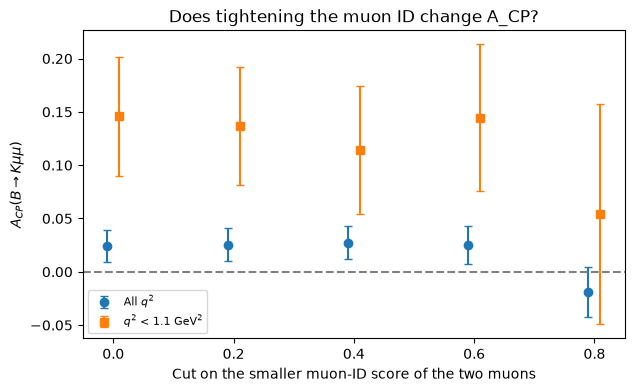

In [69]:
#3) Particle ID: tighten a cut on the smaller of the two muons' muon-ID scores and watch A_CP
muon_pid_min = np.minimum(data['Same-sign muon PID NN score for muon hypothesis'],
                          data['Opposite-sign muon PID NN score for muon hypothesis'])
rare_exponent = result_asym_rare.params['asym_rare_exponent']['value']
jpsi_count_nominal = counted_asymmetry(jpsi_k_sample & in_peak)[0]

def rare_acp_with(extra, name, rare_only=None, **fit_options):
    #A_CP of the rare decay with an extra cut (e.g. on muon ID) applied to BOTH the rare and the J/psi K samples.
    #rare_only: an optional cut for the rare sample only (e.g. a q^2 bin; J/psi K always sits at q^2 = 9.6 GeV^2).
    #J/psi K: nominal fitted A_raw, shifted by the change seen by counting in the peak window
    rare_selection = rare_sample & extra if rare_only is None else rare_sample & extra & rare_only
    a, e, _ = fit_charge_asymmetry(b_mass[rare_selection], kaon_type[rare_selection],
                                   chop_B, name, name, plot=False, **fit_options)
    jpsi_raw = A_raw_jpsik + counted_asymmetry(jpsi_k_sample & in_peak & extra)[0] - jpsi_count_nominal
    return a - jpsi_raw, np.sqrt(e**2 + A_raw_jpsik_err**2)

pid_cuts = [0.0, 0.2, 0.4, 0.6, 0.8]
pid_rows = []
for k, cut in enumerate(pid_cuts):
    passes = muon_pid_min > cut
    print(f'\n===== muon-ID score > {cut}')
    all_cp, all_err = rare_acp_with(passes, f'pid_all_{k}', fix_shape=True)
    low_cp, low_err = rare_acp_with(passes, f'pid_low_{k}', rare_only=low_q2, fix_shape=True, fixed_exponent=rare_exponent)
    eff = np.mean(passes[jpsi_k_sample & in_peak])
    pid_rows.append((cut, eff, all_cp, all_err, low_cp, low_err))

base = pid_rows[0]
print()
print(tabulate([(f'> {c}', f'{eff:.1%}', f'{a:.4f} +/- {ae:.4f}', f'{l:.4f} +/- {le:.4f}',
                 #how far each point is from the no-cut value, in units of the random change expected from removing events
                 f'{abs(l - base[4]) / np.sqrt(max(le**2 - base[5]**2, 1e-12)):.1f}' if c > 0 else '-')
                for c, eff, a, ae, l, le in pid_rows],
               headers=['Muon-ID cut', 'J/psi K kept', 'A_CP (all q^2)', 'A_CP (q^2 < 1.1)', 'Lowest-bin change / noise']))

fig, ax = plt.subplots(figsize=(7, 4))
c_, eff_, a_, ae_, l_, le_ = (np.array(x) for x in zip(*pid_rows))
ax.errorbar(c_ - 0.01, a_, yerr=ae_, fmt='o', capsize=3, label=r'All $q^2$')
ax.errorbar(c_ + 0.01, l_, yerr=le_, fmt='s', capsize=3, label=r'$q^2$ < 1.1 GeV$^2$')
ax.axhline(0, color='grey', linestyle='--')
ax.set_xlabel('Cut on the smaller muon-ID score of the two muons')
ax.set_ylabel(r'$A_{CP}(B \to K \mu\mu)$')
ax.set_title('Does tightening the muon ID change A_CP?')
ax.legend(fontsize=8)
plt.show()

**How to read the muon-ID test.** Tightening the cut removes events, so A_CP always moves a little by chance. The last column compares the change in the lowest bin with the change expected from chance alone (√(σ_cut² − σ_no cut²), the "uncorrelated" part of the uncertainties). Values up to about 2 are just noise; a steady trend well above that as the cut tightens would point to misidentified pions.

## Systematic uncertainties
The ± on A_CP so far is **statistical**: it comes only from the limited number of events. A **systematic** uncertainty covers the **choices we made**: if we had made another reasonable choice, how much would A_CP change?

**Method:** change one choice at a time, redo A_CP, and record the shift from the nominal result. There are two kinds of change:
- **Same events, different model** (e.g. letting the right tail of the signal shape float): every bit of the shift is real, so the **whole shift** is the systematic.
- **Slightly different events** (e.g. a different fit range or cut): part of the shift is just random noise from adding or removing events, of size √|σ_new² − σ_nominal²|. Only the part of the shift **beyond** that noise counts: √(max(shift² − noise², 0)). This avoids counting the statistical uncertainty twice.

**Why the right tail is taken from J/ψ K, not left free.** With about 5,600 signal events on top of about 4,350 background events, the rare-decay fit can't pin down the tail by itself: when `alphaR` and `nR` were left free, the tail stretched out and swallowed most of the flat background (the "signal" went from about 5,600 to about 8,800 events, with an impossibly *smaller* uncertainty). So instead we use a different, well-measured tail: the J/ψ K fit, with about 860,000 events and its tails left free. Only the *right* tail is taken from it, because the J/ψ mass window removes the photon events that make the left tail (which is why its `nL` runs to its limit). This is a fair alternative: the Task 1 tail was partly soaking up B⁺ → J/ψ π⁺ events just above the peak, so the true tail lies somewhere between the two.

When there are two versions of the same choice (e.g. starting the fit lower or higher), we take the larger. The individual systematics are independent, so the total is the square root of the sum of their squares.

| Source | What we change |
|---|---|
| Right tail of the signal shape | take `alphaR` and `nR` from the J/ψ K fit (Task 7) instead of the Task 1 fit |
| Width of the signal peak | let σ float instead of fixing it |
| Background model | separate background slopes for B⁺ and B⁻ |
| How the J/ψ K asymmetry is measured | count in the peak window instead of fitting |
| How the bump below the peak is handled | Option A (chop at 5220 MeV, no photon veto) |
| Start of the fit range | 5160 and 5200 MeV instead of 5180 |
| End of the fit range | 5600 and 5800 MeV instead of 5700 |
| Duplicate candidates | one candidate per event |
| XGBoost cut | 0.95 instead of 0.90 |
| Muon identification | require muon-ID score > 0.6 for both muons |
| Misidentified K⁺π⁺π⁻ | estimate from known decay rates (above): 0.001 |
| Kaon kinematics, J/ψ K vs rare | negligible: A_raw(J/ψ K) does not depend on kaon momentum (cross-check above) |

In [70]:
def rare_acp(selection, name, lower=chop_B, upper=5700, **fit_options):
    #A_CP from the rare-decay fit of `selection`, corrected with the nominal J/psi K raw asymmetry
    a, e, _ = fit_charge_asymmetry(b_mass[selection], kaon_type[selection], lower, name, name,
                                   upper=upper, plot=False, **fit_options)
    return a - A_raw_jpsik, np.sqrt(e**2 + A_raw_jpsik_err**2)

#(source, kind, label, A_CP, uncertainty). kind: 'model' = same events; 'sample' = slightly different events
variations = []
#Right tail of the signal shape taken from the J/psi K fit (Task 7) instead of the Task 1 fit (see the markdown above)
jpsik_tail = {p: result_asym_jpsik.params[f'asym_jpsik_{p}']['value'] for p in ('alphaR', 'nR')}
print(f"===== Right tail from the J/psi K fit: alphaR = {jpsik_tail['alphaR']:.2f}, nR = {jpsik_tail['nR']:.1f} "
      f"(Task 1: alphaR = {result_b_cb.params[b_cb_alphaR]['value']:.2f}, nR = {result_b_cb.params[b_cb_nR]['value']:.1f})")
variations.append(('Right tail of the signal shape', 'model', 'right tail from J/psi K fit',
                   *rare_acp(rare_sample, 'syst_tail', fix_shape=True, shape_values=jpsik_tail)))
print('===== Width floating');             variations.append(('Width of the signal peak', 'model', 'sigma floats', *rare_acp(rare_sample, 'syst_width', fix_shape=True, free_shape=('sigma',))))
print('===== Separate background slopes'); variations.append(('Background model', 'model', 'separate slopes for B+ and B-', *rare_acp(rare_sample, 'syst_slopes', fix_shape=True, separate_slopes=True)))
variations.append(('J/psi K asymmetry method', 'model', 'counting in the peak window', A_raw_rare - jpsi_count_nominal, A_CP_rare_err))
print('===== Option A');                   variations.append(('Bump below the peak', 'sample', 'Option A', *rare_acp(keep, 'syst_optionA', lower=chop_A, fix_shape=True)))
for lo in (5160, 5200):
    print(f'===== Fit from {lo}');          variations.append(('Start of the fit range', 'sample', f'from {lo} MeV', *rare_acp(rare_sample, f'syst_lo{lo}', lower=lo, fix_shape=True)))
for hi in (5600, 5800):
    print(f'===== Fit up to {hi}');         variations.append(('End of the fit range', 'sample', f'up to {hi} MeV', *rare_acp(rare_sample, f'syst_hi{hi}', upper=hi, fix_shape=True)))
variations.append(('Duplicate candidates', 'sample', 'one candidate per event', A_CP_single, A_CP_single_err))
print('===== XGBoost cut 0.95');           variations.append(('XGBoost cut', 'sample', 'cut 0.95', *rare_acp_with(signal_probability > 0.95, 'syst_bdt095', fix_shape=True)))
print('===== Muon ID > 0.6');              variations.append(('Muon identification', 'sample', 'muon-ID > 0.6', *rare_acp_with(muon_pid_min > 0.6, 'syst_pid06', fix_shape=True)))

#Systematic from each variation
rows, per_source = [], {}
for source, kind, label, a_cp, err in variations:
    shift = a_cp - A_CP_rare
    noise = np.sqrt(abs(err**2 - A_CP_rare_err**2)) if kind == 'sample' else 0.0
    assigned = np.sqrt(max(shift**2 - noise**2, 0.0))
    per_source[source] = max(per_source.get(source, 0.0), assigned)      #two versions of the same choice: take the larger
    rows.append((source, label, f'{a_cp:.4f}', f'{shift:+.4f}', f'{noise:.4f}' if kind == 'sample' else '-', f'{assigned:.4f}'))

#Sources estimated without a fit
per_source['Misidentified K pi pi'] = 0.001
per_source['Kaon kinematics (J/psi K vs rare)'] = 0.0
rows += [('Misidentified K pi pi', 'estimate from decay rates', '-', '-', '-', '0.0010'),
         ('Kaon kinematics (J/psi K vs rare)', 'negligible (flat A_raw vs momentum)', '-', '-', '-', '0.0000')]

print()
print(tabulate(rows, headers=['Source', 'Variation', 'A_CP', 'Shift', 'Noise from changed events', 'Systematic']))

A_CP_syst = np.sqrt(sum(v**2 for v in per_source.values()))
print()
print(tabulate(sorted(per_source.items(), key=lambda x: -x[1]) + [('TOTAL (in quadrature)', A_CP_syst)],
               headers=['Source', 'Systematic uncertainty'], floatfmt='.4f'))

===== Right tail from the J/psi K fit: alphaR = 1.76, nR = 73.0 (Task 1: alphaR = 1.57, nR = 17.6)
Valid: True
N(B+) = 2764, N(B-) = 2824
Raw asymmetry A = 0.0107 +/- 0.0153
===== Width floating
Valid: True
N(B+) = 2816, N(B-) = 2874
Raw asymmetry A = 0.0103 +/- 0.0151
===== Separate background slopes
Valid: True
N(B+) = 2806, N(B-) = 2843
Raw asymmetry A = 0.0065 +/- 0.0158
===== Option A
Valid: True
N(B+) = 2656, N(B-) = 2723
Raw asymmetry A = 0.0124 +/- 0.0160
===== Fit from 5160
Valid: True
N(B+) = 2782, N(B-) = 2842
Raw asymmetry A = 0.0106 +/- 0.0153
===== Fit from 5200
Valid: True
N(B+) = 2805, N(B-) = 2865
Raw asymmetry A = 0.0105 +/- 0.0151
===== Fit up to 5600
Valid: True
N(B+) = 2792, N(B-) = 2840
Raw asymmetry A = 0.0085 +/- 0.0154
===== Fit up to 5800
Valid: True
N(B+) = 2810, N(B-) = 2872
Raw asymmetry A = 0.0109 +/- 0.0151
===== XGBoost cut 0.95
Valid: True
N(B+) = 2522, N(B-) = 2597
Raw asymmetry A = 0.0146 +/- 0.0153
===== Muon ID > 0.6
Valid: True
N(B+) = 1907, N(B-) 

## Final result
The CP asymmetry of B⁺ → K⁺μ⁺μ⁻, using all the data (2011 + 2012), with its statistical and systematic uncertainties. It is compared with zero (the Standard Model expectation) using both uncertainties combined in quadrature, and with LHCb's published measurement on the same 3 fb⁻¹ of data.

In [71]:
A_CP_total_err = np.sqrt(A_CP_rare_err**2 + A_CP_syst**2)
lhcb_value, lhcb_err = 0.012, np.sqrt(0.017**2 + 0.001**2)   #LHCb, JHEP 09 (2014) 177

print('=' * 70)
print(f'  A_CP(B -> K mu mu) = {A_CP_rare:.3f} +/- {A_CP_rare_err:.3f} (stat) +/- {A_CP_syst:.3f} (syst)')
print('=' * 70)
print(f'Total uncertainty: {A_CP_total_err:.3f}')
print(f'Distance from zero (Standard Model): {abs(A_CP_rare) / A_CP_total_err:.1f} standard deviations')
print(f'Difference from LHCb ({lhcb_value} +/- {lhcb_err:.3f}): '
      f'{abs(A_CP_rare - lhcb_value) / np.sqrt(A_CP_total_err**2 + lhcb_err**2):.1f} standard deviations '
      f'(the two use the same data, so they are not independent; this is only a rough comparison)')
print(f'\nControl sample B -> psi(2S) K (should be 0): A_CP = {A_CP_psi2sk:.4f} +/- {A_CP_psi2sk_err:.4f}')

  A_CP(B -> K mu mu) = 0.024 +/- 0.015 (stat) +/- 0.005 (syst)
Total uncertainty: 0.016
Distance from zero (Standard Model): 1.5 standard deviations
Difference from LHCb (0.012 +/- 0.017): 0.5 standard deviations (the two use the same data, so they are not independent; this is only a rough comparison)

Control sample B -> psi(2S) K (should be 0): A_CP = 0.0019 +/- 0.0038


# Summary of the analysis
**The CP asymmetry of the rare decay B⁺ → K⁺μ⁺μ⁻, measured with LHCb data**

All numbers are from all the data (2011 + 2012) with the final selection.

---

## 1. The question
- **Matter and antimatter.** The Big Bang should have produced equal amounts of matter and antimatter, but the Universe today is almost entirely matter. Something must treat them differently. A difference between how a particle and its antiparticle behave is called **CP violation**.
- **Our decay.** B⁺ → K⁺μ⁺μ⁻: a B meson decays to a kaon and two muons. At the quark level a b quark becomes an s quark (b → s μ⁺μ⁻). This cannot happen directly in the Standard Model, only through "loop" diagrams with heavy W bosons and top quarks, so it is **very rare**: about 1 in every 2 million B⁺ decays.
- **Why it is interesting.** New, undiscovered heavy particles could also take part in these loops and change the decay. The Standard Model predicts **almost no difference** between B⁺ and B⁻ here, so a clearly non-zero asymmetry would point to new physics.
- **What we measure.**

  A_CP = (N(B⁻) − N(B⁺)) / (N(B⁻) + N(B⁺)), where N is the number of decays (B⁻ contains the b quark, so it is the "matter" particle).

  **Standard Model prediction: A_CP ≈ 0.**

## 2. The data
- **LHCb data from 2011 (7 TeV, 1 fb⁻¹) and 2012 (8 TeV, 2 fb⁻¹), both magnet polarities:** about **3.0 million candidates**. A *candidate* is one combination of a kaon and two oppositely charged muons that might have come from a B decay. Almost all of them are something else.
- **Same-sign data:** candidates where both muons have the **same charge**. No real B → K μμ decay can produce this, so it is a sample of **pure random-combination background** (164,000 candidates).
- **Simulation (RapidSim):** simulated B⁺ → K⁺μ⁺μ⁻ and B⁺ → J/ψ K⁺ decays, where the right answer is known. It only contains B⁺ and has no particle-ID or vertex-quality variables, so it is used only for kinematic studies.

## 3. The B mass (Task 1)
- **The B-candidate mass distribution has three parts:** a sharp **peak at about 5280 MeV** (real B decays), a **bump below it** (real B decays where a particle was missed, so the mass comes out too low), and a **smooth spread** (random combinations of tracks).
- **Fitting the peak.** A Gaussian describes it badly (reduced χ² = 471). A **double-sided Crystal Ball** (a Gaussian core with slowly falling power-law tails on both sides) does much better (reduced χ² = 4.8). The low-mass tail comes mainly from photons radiated by the final-state particles; the high-mass tail from the detector resolution not being exactly Gaussian.

| | Fitted | PDG | Difference |
|---|---|---|---|
| B⁺ mass (Gaussian) | 5283.57 ± 0.02 MeV | 5279.34 MeV | +0.080% |
| B⁺ mass (double Crystal Ball) | 5283.90 ± 0.03 MeV | 5279.34 MeV | +0.086% |
| J/ψ mass | 3099.93 ± 0.01 MeV | 3096.90 MeV | +0.098% |
| ψ(2S) mass | 3689.80 ± 0.05 MeV | 3686.10 MeV | +0.100% |

- **The mass is about 4.6 MeV too high**, far more than its statistical uncertainty. It does not depend on the fit shape (the two fits agree to 0.3 MeV), and **all three particles are too high by the same fraction (≈ 0.09%)**. A common fractional shift means the **momentum scale** of the detector is slightly too high (about 0.1%); the dataset has no momentum-scale calibration applied. This shifts B⁺ and B⁻ equally, so it does not affect A_CP.
- **The width.** The fitted width is σ ≈ 18 MeV. The natural width of the B⁺ is Γ = ħ/τ ≈ 4 × 10⁻¹⁰ MeV (lifetime τ = 1.64 ps), far too small to see. The 18 MeV is entirely **detector resolution** (momenta are measured to about 0.5%).

## 4. The dimuon mass (Task 2)
- The dimuon-mass spectrum shows two large peaks: the **J/ψ** (3097 MeV, σ = 13.1 MeV) and the **ψ(2S)** (3686 MeV, σ = 15.9 MeV). Most "B → K μμ" candidates are really **B⁺ → J/ψ K⁺** (or ψ(2S) K⁺) with J/ψ → μ⁺μ⁻, which is about 100 times more common than the rare decay.
- **For the rare decay we remove ±100 MeV around both peaks.** That is about 7σ: these peaks are so large (around a million events) that even a tiny fraction left in their tails would be comparable to our signal.
- **B⁺ → J/ψ K⁺ is kept as a control channel**: it has the same final-state particles as the rare decay, and is used in Tasks 7 and 8.

## 5. Selecting real decays (Tasks 3 and 4)
- **Training samples for machine learning.** *Signal:* B → J/ψ K candidates with both the dimuon mass and the B mass in their peaks (1.07 million, almost all real decays). *Background:* the same-sign data (164,000). J/ψ K is used as signal because it has the same final state, and the B flies and decays in the same way as in the rare decay.
- **Choosing input variables.** We started from 26 variables with a physical reason to differ between signal and background (vertex quality, flight distance, impact parameters, transverse momenta, isolation) and kept only those that are:
  - **useful:** they separate signal from background on their own (ROC AUC above 0.65);
  - **safe for the B mass:** weakly correlated with the B mass in background-only data (rank correlation below 0.15), so cutting on them cannot create a fake peak;
  - **safe for the dimuon mass:** real signal looks the same at the J/ψ and the ψ(2S). We train on J/ψ K but want rare decays at all dimuon masses. (The simulation does not show this effect correctly; the real data does.)

  **14 variables passed**, e.g. the impact-parameter χ² of the kaon and of the muons, the B-vertex fit χ², the B flight-distance χ² and the B direction angle. Removing even the least important of them made the classifier measurably worse, so all 14 are used.
- **The classifier: XGBoost** (boosted decision trees), which combines the 14 variables into one score between 0 and 1. It uses gentle settings (small trees, small learning steps) to avoid **overtraining** (memorising the training sample): the ROC AUC is 0.959 on training events and 0.956 on unseen test events.
- **Choosing the cut on the score.** We choose the cut that **maximises S/√(S+B)**, where S and B are the numbers of signal and background events in the B-mass peak window. When counting B⁺ against B⁻, the uncertainty on A is about √(S+B)/S, so maximising S/√(S+B) **minimises the uncertainty on A_CP**.
  - S is the rare-decay yield at the current cut, scaled with the fraction of J/ψ K test signal that survives each cut. B is the background measured above the peak (5400–7000 MeV) and extrapolated under the peak with an exponential.
  - The maximum is at 0.93, and 0.90–0.94 are all within 2% of it. **We use 0.90** (the loosest, which keeps 90% of the signal). Compared with a first guess of 0.99, this **doubles the signal** and lowers the expected uncertainty on A from 0.019 to 0.015.

## 6. Peaking and misidentified backgrounds (Task 5)
Some backgrounds look exactly like the signal. We found them by **recomputing masses with a different particle hypothesis** for a track and looking for a peak:

| Background | What happens | How it is removed |
|---|---|---|
| B → J/ψ K with a muon and the kaon swapped | one J/ψ muon is labelled as the "kaon" | veto ±50 MeV around 3097 MeV in the K⁺μ⁻ mass with both given the muon mass (3.8σ) |
| B → ψ(2S) K, same swap | the same mistake | veto ±50 MeV around 3686 MeV (3.2σ) |
| D⁰ → K⁺π⁻ | the pion is misidentified as a muon | veto ±25 MeV around 1865 MeV in the K⁺μ⁻ mass with the muon given the pion mass (3σ) |
| B → J/ψ K (or ψ(2S) K) with final-state radiation | an unseen photon lowers the dimuon mass below the J/ψ veto, and the B mass by the same amount | **photon veto** (below) |
| Partly reconstructed decays, e.g. B → K* μμ | a pion is missed, so the B mass is too low (below about 5180 MeV) | fit only above 5180 MeV |

- **The photon veto.** When a photon is lost, the B mass and the dimuon mass drop by the same amount, so their difference stays at m(B) − m(J/ψ) ≈ 2184 MeV (or 1594 MeV for the ψ(2S)). Removing candidates within ±100 MeV of these values removes almost the whole bump below the B peak (29,000 candidates), but only 186 candidates in the B peak window. Real rare decays survive, because their B mass is correct.
- **B → K π π with both pions misidentified as muons** (including B⁺ → K⁺ρ⁰, which has a large CP asymmetry of its own). Recomputing the mass with pion masses cannot separate these from the signal: muons and pions have similar masses, and **79% of simulated rare decays also stay within 40 MeV of the B mass** under the pion hypothesis. Instead we used **particle identification**: tightening a cut on the muon-ID score of both muons did not change A_CP beyond statistical fluctuations. From known branching fractions and misidentification rates (about 1–2% per pion), the possible effect on A_CP is about 0.001, which is included as a systematic uncertainty.

## 7. Counting the B decays (Task 6)
- **Method:** an extended unbinned maximum-likelihood fit of the B mass between 5180 and 5700 MeV, using zfit and Minuit.
  - **Signal:** the double-sided Crystal Ball, with its width and tails **fixed** from the B → J/ψ K fit (same B meson, same detector, so the same peak shape; the rare sample is too small to measure them itself). Only the peak position is free.
  - **Background:** an exponential (random combinations).
- **Result: N = 5,649 ± 89 rare B decays** (and 4,347 ± 82 background candidates in the fit range). The fit describes the data well (reduced χ² = 1.34).
- **Checks:** an alternative treatment of the bump below the peak (no photon veto, fit from 5220 MeV) gives 5,379 ± 94. **Multiple candidates:** 0.32% of the rare-decay candidates share a collision with another candidate (0.02% for J/ψ K); keeping one at random per collision changes A_CP by only 0.0003.

## 8. The production and detection asymmetry (Task 7)
- Even if B⁺ and B⁻ decayed identically, we would not count equal numbers:
  - **Production asymmetry (A_prod):** the LHC collides protons (matter), so B⁺ and B⁻ are not produced in exactly equal numbers.
  - **Detection asymmetry (A_det):** K⁺ and K⁻ interact differently with the detector material (K⁻ are absorbed more often), so they are not detected with exactly the same efficiency.
- So what we count is the **raw asymmetry**: A_raw = A_CP + A_det + A_prod.
- **B⁺ → J/ψ K⁺** measures these effects. It has the same final state and passes the same selection, and its true A_CP is expected to be essentially zero, because it proceeds through a single tree-level process (b → c c̄ s), and CP violation needs two interfering processes. Fitting B⁺ and B⁻ simultaneously (862,726 decays):

  **A_raw(J/ψ K) = −0.0139 ± 0.0011.** This is clearly not zero (13σ), but it is **not CP violation**: it is A_det + A_prod.

## 9. The CP asymmetry of the rare decay, and checks of the correction (Task 8)
- **Rare decay, B⁺ and B⁻ fitted simultaneously** (2,796 B⁺ and 2,854 B⁻ decays): **A_raw = +0.0103 ± 0.0152.**
- **Correction:** A_CP = A_raw(B → K μμ) − A_raw(B → J/ψ K) = **0.0242 ± 0.0152 (stat).**
- **Does the correction work?** We tested it on pieces of the data where the production and detection asymmetries should be different:

| Check | Result |
|---|---|
| B → ψ(2S) K (true A_CP ≈ 0, different kinematics) | A_CP = 0.0019 ± 0.0038 ✅ consistent with zero |
| Magnet up vs magnet down (swaps which side of the detector K⁺ and K⁻ go to) | 0.020 ± 0.022 vs 0.028 ± 0.021 ✅ agree (0.3σ); average 0.024 ± 0.015 |
| 2011 (7 TeV) vs 2012 (8 TeV) | 0.006 ± 0.027 vs 0.032 ± 0.018 ✅ agree (0.8σ) |
| Kaon and B kinematics, J/ψ K vs rare decay | very similar (AUC 0.51–0.55), and A_raw(J/ψ K) does not depend on the kaon momentum (χ²/ndf = 8.3/9) ✅ |

- **A_CP in bins of q² = (dimuon mass)²:**

| q² (GeV²) | Signal yield | A_CP |
|---|---|---|
| below 1.1 | 437 | +0.145 ± 0.054 |
| 1.1 – 6.0 | 1,509 | +0.017 ± 0.030 |
| 6.0 – 9.0 | 1,070 | +0.045 ± 0.035 |
| 10.2 – 12.9 | 893 | +0.061 ± 0.037 |
| above 14.3 | 1,743 | −0.030 ± 0.027 |

  The average of the bins equals the whole-sample result. In 20 narrow bins of 1 GeV² the values are consistent with each other (χ²/ndf = 20.2/19) and with zero. The lowest bin is 2.7σ from zero; it **stays high when the muon identification is tightened**, so it is not caused by misidentified pions, and with five bins a deviation this size is not unusual (the bins' consistency test gives p = 0.03).

## 10. Systematic uncertainties
The ± 0.015 above is **statistical**: it comes only from the limited number of events. The **systematic** uncertainty covers our choices: each choice is changed in turn and A_CP is redone. When a change also changes the events used, part of the shift is just statistical noise (√|σ²_new − σ²_nominal|); only the part beyond that noise is counted.

| Source | What was changed | Systematic |
|---|---|---|
| Background model | separate background slopes for B⁺ and B⁻ | 0.0037 |
| XGBoost cut | 0.95 instead of 0.90 | 0.0033 |
| Misidentified K π π | estimate from known decay rates | 0.0010 |
| Right tail of the signal shape | tail parameters from the J/ψ K fit instead of the Task 1 fit | 0.0005 |
| Width of the signal peak | width left free | 0.0001 |
| J/ψ K asymmetry method | counting in the peak window instead of fitting | 0.0001 |
| Bump below the peak, fit range (start and end), duplicate candidates, muon identification | various | 0 (shifts within statistical noise) |
| Kaon kinematics (J/ψ K vs rare) | — | negligible |
| **Total** (in quadrature) | | **0.005** |

Most choices barely matter, because B⁺ and B⁻ are treated identically and the effects cancel in the asymmetry. **The systematic uncertainty is three times smaller than the statistical one**: the measurement is limited by the number of rare decays, not by the method.

---

## 11. Final result

> ## A_CP(B⁺ → K⁺μ⁺μ⁻) = 0.024 ± 0.015 (stat) ± 0.005 (syst)

- Total uncertainty 0.016, so the result is **1.5σ from zero: consistent with the Standard Model**, with no evidence for new physics.
- It agrees with LHCb's published measurement on the same 3 fb⁻¹ of data, A_CP = 0.012 ± 0.017 ± 0.001 [JHEP 09 (2014) 177].
- The control channel B → ψ(2S) K gives 0.002 ± 0.004, as expected for a decay with no CP violation, which supports the correction method.
